# Pronóstico de caudales altos en el río Tebicuary — estación Villa Florida

**Diplomado ML/DL Aplicado — FIUNA · Proyecto Final Integrador (M7)**

Objetivo: pronosticar el caudal diario en Villa Florida con 1, 2 y 3 días de anticipación a partir del caudal observado y de la precipitación media areal antecedente de la cuenca, con énfasis en caudales altos.

Pregunta hidrológica asociada: ¿qué ventana de precipitación acumulada (1, 3, 5, 7, 10, 15 o 30 días) aporta más información para el pronóstico, y en qué horizonte la precipitación agrega valor sobre la persistencia?

Flujo del notebook:
1. Carga y limpieza de datos (valores negativos → faltantes, fechas duplicadas).
2. Precipitación media areal por Thiessen dinámico (pesos recalculados cada día según estaciones disponibles).
3. Análisis exploratorio y tiempo de respuesta de la cuenca.
4. Feature engineering y partición temporal.
5. Línea base (persistencia), ablación de ventanas de lluvia y comparación de modelos.
6. Optimización de hiperparámetros con `TimeSeriesSplit`, evaluación en test y SHAP.
7. Evaluación de la serie completa y luego de los extremos; análisis del desfase temporal.
8. Incertidumbre: regresión cuantílica recalibrada y Monte Carlo.
9. Estación Yuty (aguas arriba): tiempo de tránsito y aporte al pronóstico.
10. Lluvia satelital CHIRPS (Google Earth Engine): validación y aporte al pronóstico.
11. Pronósticos meteorológicos históricos GFS: validación y aporte al pronóstico.
12. Alerta de caudales altos (probabilidad de superar umbrales de permanencia) y diagnóstico de caudales bajos.
13. Guardado del modelo, inferencia de prueba y muestra de datos.

## 1. Configuración

In [1]:
import warnings, os, glob
from itertools import compress
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point, MultiPoint, Polygon
from shapely.ops import voronoi_diagram
import joblib, shap

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
SEED = 42
np.random.seed(SEED)

RAW = 'data/raw'
PROC = 'data/processed'
FIG = 'figuras'
os.makedirs(PROC, exist_ok=True); os.makedirs(FIG, exist_ok=True)

# Estilo de gráficos: ejes y grilla recesivos, líneas finas
C_OBS, C_MOD, C_PERS, C_P = '#2a78d6', '#eb6834', '#8a8984', '#1baf7a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#333', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'lines.linewidth': 1.5, 'font.size': 9, 'legend.frameon': False})

## 2. Carga y limpieza de datos

Formato de los archivos: `día mes año valor`. El valor `-1` indica dato faltante. Se detectó un bloque de fechas duplicadas en San Juan Bautista (1–10 ene 2018) con valores idénticos; se conserva la primera ocurrencia.

No se completan faltantes con estaciones vecinas: el Thiessen dinámico redistribuye el área de la estación faltante entre las disponibles, lo que evita introducir series sintéticas que suavizan los extremos.

In [2]:
EST = {  # lat, lon — Estaciones_Pluviometricas.xlsx (DMH)
    'Paraguari': (-25.627040, -57.145998), 'Villarrica': (-25.753987, -56.437998),
    'Coronel_Oviedo': (-25.484017, -56.377995), 'Quyquyho': (-26.217039, -56.983002),
    'Pilar': (-26.881037, -58.318002), 'San_Juan_Bautista': (-26.669977, -57.133996),
    'Caazapa': (-26.174962, -56.355000), 'Encarnacion': (-27.225982, -55.837004)}
VF_GAUGE = (-26.392694, -57.129654)
NOMBRE = {'Paraguari': 'Paraguarí', 'Villarrica': 'Villarrica', 'Coronel_Oviedo': 'Coronel Oviedo', 'Quyquyho': 'Quyquyho',
          'Pilar': 'Pilar', 'San_Juan_Bautista': 'San Juan Bautista', 'Caazapa': 'Caazapá', 'Encarnacion': 'Encarnación'}

def leer_serie(path):
    d = pd.read_csv(path, sep=r'\s+', header=None, names=['d', 'm', 'y', 'v'])
    d.index = pd.to_datetime(dict(year=d.y, month=d.m, day=d.d))
    n_dup = d.index.duplicated().sum()
    s = d.v[~d.index.duplicated(keep='first')]
    return s.where(s >= 0), n_dup   # negativos (-1) -> NaN

P, dups = {}, {}
for k in EST:
    P[k], dups[k] = leer_serie(f'{RAW}/Precipitaciones/{k}.txt')
P = pd.DataFrame(P).asfreq('D')
Q, _ = leer_serie(f'{RAW}/Caudales/Caudal Villa Florida.txt')
Q = Q.asfreq('D').rename('Q')

print('Período:', P.index.min().date(), '→', P.index.max().date(), f'({len(P)} días)')
print('Fechas duplicadas eliminadas:', {k: v for k, v in dups.items() if v})
print('\nFaltantes (%):')
print(pd.concat([P, Q], axis=1).isna().mean().mul(100).round(1).to_string())

Período: 1974-01-01 → 2023-08-23 (18132 días)
Fechas duplicadas eliminadas: {'San_Juan_Bautista': np.int64(10)}

Faltantes (%):
Paraguari            40.7
Villarrica            0.7
Coronel_Oviedo       30.3
Quyquyho              2.5
Pilar                 1.3
San_Juan_Bautista     2.3
Caazapa               2.7
Encarnacion           1.5
Q                    38.6


### Series duplicadas: Quyquyho y Caazapá

Las series originales de Quyquyho y Caazapá son idénticas día a día entre 1974 y 2016 (en las series entregadas por la fuente); desde 2017 se separan. Una de ellas fue completada con la otra. Para no contar dos veces la misma lluvia en el Thiessen, se trata Caazapá como faltante en 1974–2016 (tratamiento D2): en ese período su área se redistribuye entre las estaciones vecinas. La prueba de sensibilidad (Quyquyho o Caazapá como faltante) dio resultados equivalentes y ambas mejoran respecto a mantener la duplicación.

In [3]:
_m = P['Quyquyho'].notna() & P['Caazapa'].notna()
iguales = (P['Quyquyho'][_m] == P['Caazapa'][_m]).groupby(P.index[_m].year).mean()
print('Fracción de días idénticos Quyquyho = Caazapá por año:')
print(iguales.round(2).to_dict())
P_orig = P.copy()   # series tal como fueron entregadas (para el escenario B)
P.loc[P.index.year <= 2016, 'Caazapa'] = np.nan   # tratamiento D2
print(f"Faltantes de Caazapá tras el tratamiento: {P['Caazapa'].isna().mean():.1%}")

Fracción de días idénticos Quyquyho = Caazapá por año:
{1974: 1.0, 1975: 1.0, 1976: 1.0, 1977: 1.0, 1978: 1.0, 1979: 1.0, 1980: 1.0, 1982: 1.0, 1983: 1.0, 1984: 1.0, 1985: 1.0, 1986: 1.0, 1987: 1.0, 1988: 1.0, 1989: 1.0, 1990: 1.0, 1991: 1.0, 1992: 1.0, 1993: 1.0, 1994: 1.0, 1995: 1.0, 1996: 1.0, 1997: 1.0, 1998: 1.0, 1999: 1.0, 2000: 1.0, 2001: 1.0, 2002: 1.0, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 1.0, 2012: 1.0, 2013: 1.0, 2014: 1.0, 2015: 1.0, 2016: 1.0, 2017: 0.72, 2018: 0.7, 2019: 0.7, 2020: 0.75, 2021: 0.72, 2022: 0.75, 2023: 0.73}
Faltantes de Caazapá tras el tratamiento: 86.9%


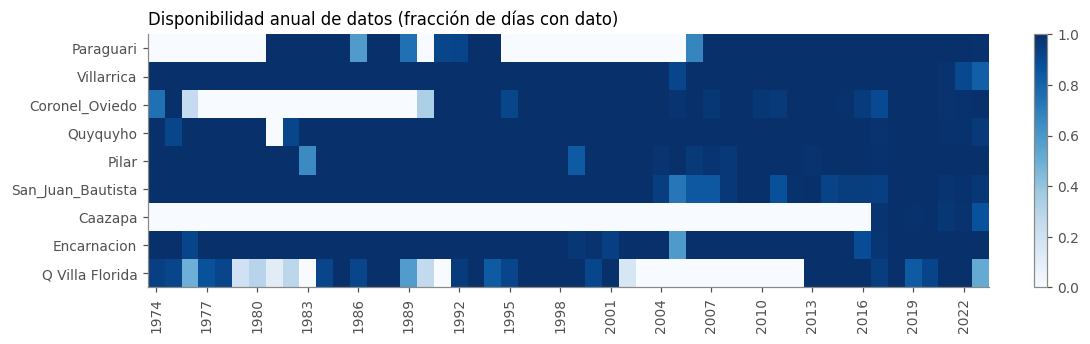

In [4]:
disp = pd.concat([P, Q.rename('Q Villa Florida')], axis=1).notna().groupby(P.index.year).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(disp.T.values, aspect='auto', cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(disp.shape[1])); ax.set_yticklabels(disp.columns)
ax.set_xticks(range(0, len(disp), 3)); ax.set_xticklabels(disp.index[::3], rotation=90)
ax.grid(False); ax.set_title('Disponibilidad anual de datos (fracción de días con dato)', loc='left')
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.savefig(f'{FIG}/disponibilidad.png', dpi=150); plt.show()

El caudal en Villa Florida tiene un vacío continuo entre 2003 y 2012. Eso define la partición temporal: entrenamiento 1974–2002 y test 2013–2023, sin mezclar períodos.

La estación Yuty (caudal) solo tiene registro desde 2016, íntegramente dentro del período de test, por lo que no se usa como predictor en esta etapa.

## 3. Precipitación media areal — Thiessen dinámico

Los polígonos de Thiessen se recortan con la cuenca de aporte a Villa Florida (proyección UTM 21S). Para cada día se recalculan los pesos usando únicamente las estaciones con dato; las combinaciones se guardan en caché.

In [5]:
cuenca = gpd.read_file(f'{RAW}/cuenca/VillaFlorida.shp').to_crs(32721)
# Disolver subcuencas y eliminar huecos internos (artefactos de la disolución)
_g = cuenca.geometry.union_all().buffer(50).buffer(-50)
_g = max(_g.geoms, key=lambda p: p.area) if _g.geom_type == 'MultiPolygon' else _g
geom = Polygon(_g.exterior)
A_KM2 = geom.area / 1e6
est_gs = gpd.GeoSeries([Point(lon, lat) for lat, lon in EST.values()], index=list(EST), crs=4326).to_crs(32721)
print(f'Área de la cuenca: {A_KM2:,.0f} km²')

_cache = {}
def pesos_thiessen(mask):
    key = tuple(bool(m) for m in mask)
    if key in _cache: return _cache[key]
    names = list(compress(EST, key))
    w, cells = pd.Series(0.0, index=list(EST)), {}
    if len(names) == 1:
        w[names[0]] = 1.0
    elif len(names) > 1:
        pts = est_gs[names]
        vor = voronoi_diagram(MultiPoint(list(pts)), envelope=geom.buffer(3e5))
        for cell in vor.geoms:
            for n in names:
                if cell.contains(pts[n]):
                    cells[n] = cell.intersection(geom)
                    w[n] = cells[n].area / geom.area
    _cache[key] = (w, cells)
    return w, cells

w_full, cells_full = pesos_thiessen([True] * len(EST))
print('Pesos de Thiessen con la red completa:')
print(w_full.sort_values(ascending=False).round(3).to_string())

Área de la cuenca: 20,987 km²
Pesos de Thiessen con la red completa:
Caazapa              0.422
Quyquyho             0.162
Villarrica           0.145
San_Juan_Bautista    0.113
Coronel_Oviedo       0.066
Encarnacion          0.065
Paraguari            0.026
Pilar                0.000


### Mapa de la cuenca y polígonos de Thiessen

Coordenadas UTM 21S en km; norte hacia arriba (flecha N), barra de escala de 50 km.

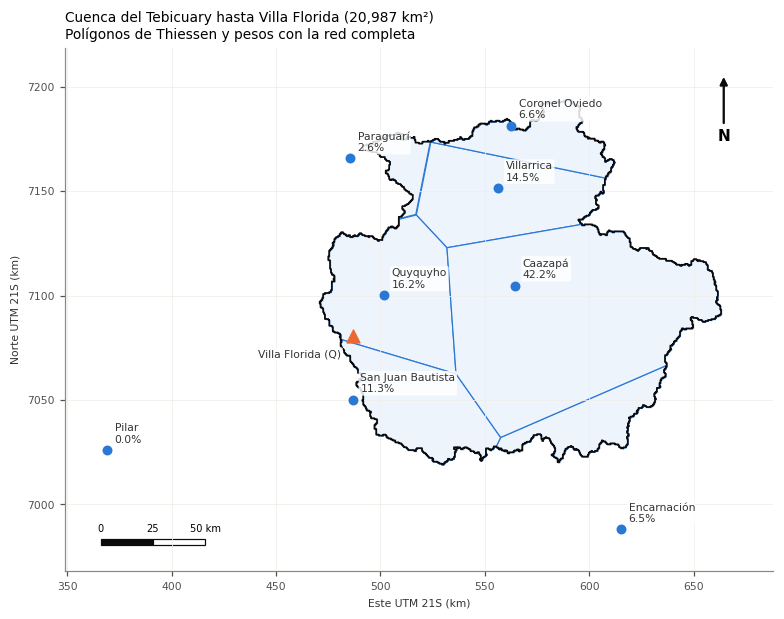

In [6]:
from matplotlib.patches import FancyArrow, Rectangle
vf = gpd.GeoSeries([Point(VF_GAUGE[1], VF_GAUGE[0])], crs=4326).to_crs(32721)
XMIN, YMIN, XMAX, YMAX = geom.buffer(25e3).union(est_gs.union_all().buffer(20e3)).bounds

def dibujar_mapa(ax, cells, w, activos, titulo, etiquetas=True):
    for n, c in cells.items():
        if not c.is_empty:
            gpd.GeoSeries([c], crs=32721).plot(ax=ax, facecolor='#eef4fc', edgecolor='#2a78d6', linewidth=0.8)
    gpd.GeoSeries([geom], crs=32721).boundary.plot(ax=ax, color='#0b0b0b', linewidth=1.1)
    for n, p in est_gs.items():
        on = activos[list(EST).index(n)]
        ax.scatter(p.x, p.y, s=28 if on else 22, color=C_OBS if on else 'white', edgecolor=C_OBS if on else '#8a8984',
                   linewidth=1.2, zorder=3, marker='o' if on else 'X')
        if etiquetas:
            txt = f'{NOMBRE[n]}\n{w[n]:.1%}' if on else f'{NOMBRE[n]}\n(sin dato)'
            ax.annotate(txt, (p.x, p.y), xytext=(5, 5), textcoords='offset points', fontsize=7, color='#333',
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    ax.scatter(vf.x[0], vf.y[0], s=70, marker='^', color=C_MOD, zorder=4)
    if etiquetas:
        ax.annotate('Villa Florida (Q)', (vf.x[0], vf.y[0]), xytext=(-8, -14), textcoords='offset points', fontsize=7,
                    ha='right', color='#333', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX); ax.set_aspect('equal')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}'))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}'))
    ax.set_xlabel('Este UTM 21S (km)', fontsize=7); ax.set_ylabel('Norte UTM 21S (km)', fontsize=7)
    ax.tick_params(labelsize=7); ax.grid(True, color='#eeeeea', lw=0.5)
    # flecha norte y barra de escala
    dx, dy = XMAX - XMIN, YMAX - YMIN
    ax.annotate('N', xy=(XMAX - 0.07*dx, YMAX - 0.05*dy), xytext=(XMAX - 0.07*dx, YMAX - 0.17*dy),
                ha='center', va='center', fontsize=10, fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', color='#0b0b0b', lw=1.5))
    x0, y0 = XMIN + 0.05*dx, YMIN + 0.05*dy
    for i in range(2):
        ax.add_patch(Rectangle((x0 + i*25e3, y0), 25e3, 0.012*dy, facecolor='#0b0b0b' if i == 0 else 'white', edgecolor='#0b0b0b', lw=0.8))
    for i, lab in enumerate(['0', '25', '50 km']):
        ax.text(x0 + i*25e3, y0 + 0.025*dy, lab, ha='center', fontsize=6.5)
    ax.set_title(titulo, loc='left', fontsize=9)

fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_mapa(ax, cells_full, w_full, [True]*len(EST), f'Cuenca del Tebicuary hasta Villa Florida ({A_KM2:,.0f} km²)\nPolígonos de Thiessen y pesos con la red completa')
plt.tight_layout(); plt.savefig(f'{FIG}/mapa_thiessen.png', dpi=170); plt.show()

### Thiessen dinámico: ejemplos

Cuando una estación no tiene dato, su polígono desaparece y el área se reparte entre las vecinas. Se muestran dos situaciones reales del registro: la ausencia simultánea de Paraguarí y Coronel Oviedo (frecuente en los años 80) y la ausencia de Caazapá, la estación de mayor peso.

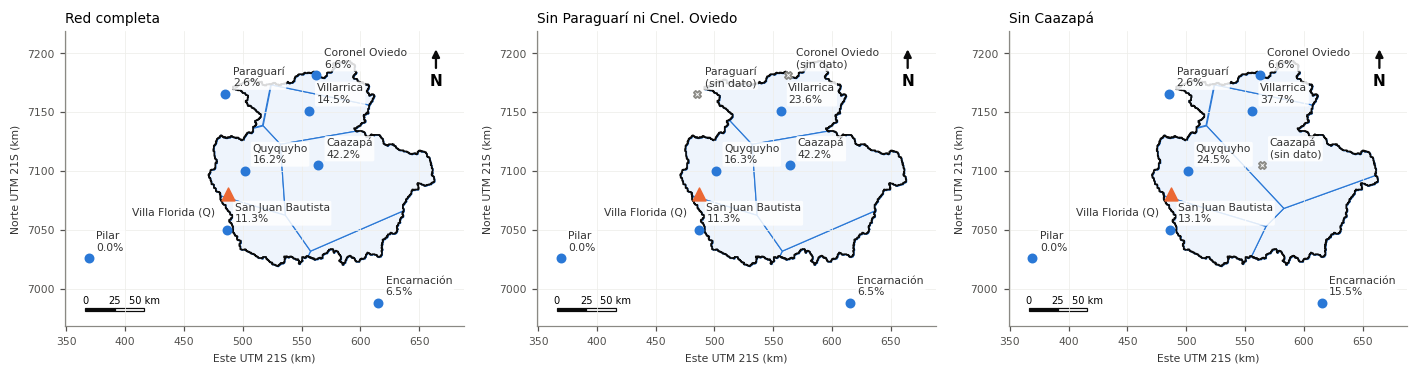

                   Red completa  Sin Paraguarí ni Cnel. Oviedo  Sin Caazapá
Paraguari                 0.026                          0.000        0.026
Villarrica                0.145                          0.236        0.377
Coronel_Oviedo            0.066                          0.000        0.066
Quyquyho                  0.162                          0.163        0.245
Pilar                     0.000                          0.000        0.000
San_Juan_Bautista         0.113                          0.113        0.131
Caazapa                   0.422                          0.422        0.000
Encarnacion               0.065                          0.065        0.155


In [7]:
casos = [('Red completa', [True]*8),
         ('Sin Paraguarí ni Cnel. Oviedo', [n not in ('Paraguari', 'Coronel_Oviedo') for n in EST]),
         ('Sin Caazapá', [n != 'Caazapa' for n in EST])]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (tit, m) in zip(axs, casos):
    w_c, cells_c = pesos_thiessen(m)
    dibujar_mapa(ax, cells_c, w_c, m, tit, etiquetas=True)
plt.tight_layout(); plt.savefig(f'{FIG}/thiessen_dinamico.png', dpi=160); plt.show()
print(pd.DataFrame({t: pesos_thiessen(m)[0] for t, m in casos}).round(3))

In [8]:
disp_mask = P.notna().values
W = np.array([pesos_thiessen(m)[0].values for m in disp_mask])
Pmed = pd.Series((W * np.nan_to_num(P.values)).sum(1), index=P.index)
Pmed[W.sum(1) == 0] = np.nan
cob_red = pd.Series(disp_mask @ w_full.values, index=P.index)  # fracción del área con su estación original disponible

serie = pd.DataFrame({'Pmed': Pmed, 'cob_red': cob_red, 'Q': Q})
serie.join(P).to_csv(f'{PROC}/serie_diaria.csv', index_label='fecha')
print(f'Combinaciones de estaciones distintas: {len(_cache)}')
print(f'Precipitación media anual de la cuenca: {Pmed.resample("YE").sum(min_count=330).mean():.0f} mm')
print(f'Días con cobertura original < 80 % del área: {(cob_red < 0.8).mean():.1%}')

Combinaciones de estaciones distintas: 50
Precipitación media anual de la cuenca: 1668 mm
Días con cobertura original < 80 % del área: 86.9%


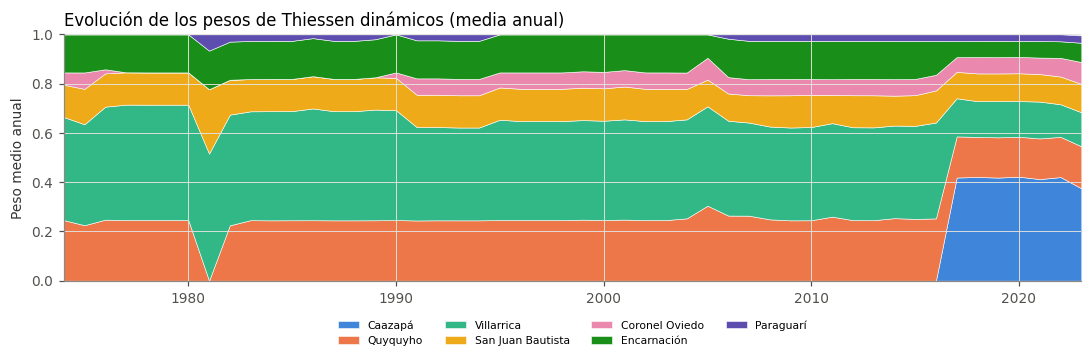

In [9]:
Wdf = pd.DataFrame(W, index=P.index, columns=list(EST))
w_anual = Wdf.groupby(Wdf.index.year).mean()
orden_w = w_full.sort_values(ascending=False).index[:7]
paleta = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7']
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.stackplot(w_anual.index, [w_anual[c] for c in orden_w], labels=[NOMBRE[c] for c in orden_w], colors=paleta, alpha=0.9, edgecolor='white', linewidth=0.4)
ax.set_ylim(0, 1); ax.set_xlim(w_anual.index.min(), w_anual.index.max())
ax.set_ylabel('Peso medio anual'); ax.legend(ncol=4, fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.set_title('Evolución de los pesos de Thiessen dinámicos (media anual)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/pesos_dinamicos.png', dpi=150); plt.show()

### Tratamiento de los faltantes (-1): comparación de escenarios

- Escenario A (adoptado): -1 → faltante; Thiessen dinámico con las estaciones disponibles.
- Escenario B: -1 tratado como 0 mm con pesos fijos (error frecuente al leer estas series).
- Escenario C: igual que A, pero se descartan del entrenamiento los días cuya ventana de 10 días incluye cobertura original < 50 % (con Caazapá tratada como faltante hasta 2016, la cobertura máxima en ese período es 58 %).

El efecto sobre el modelo se evalúa en la sección 10.

{'dias_alguna_faltante': 0.879053606882859, 'Pmed_anual_A': 1668.0575729973884, 'Pmed_anual_B': 1564.5346619442814, 'dif_diaria_max': 64.25750885402853, 'anio_max_dif': 1981, 'dif_anual_max': 903.0934026507}


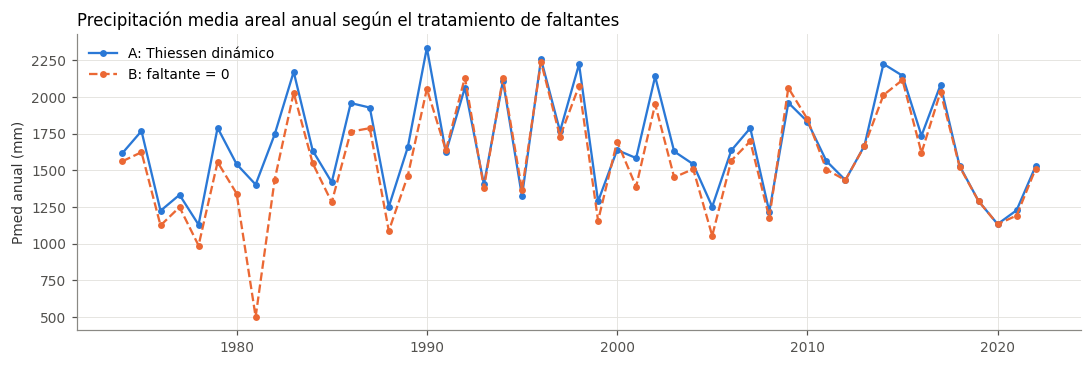

In [10]:
Pmed_B = pd.Series(np.nan_to_num(P_orig.values) @ w_full.values, index=P.index)   # -1 -> 0, pesos fijos, series originales
anual = pd.DataFrame({'A: Thiessen dinámico': Pmed.resample('YE').sum(min_count=330),
                      'B: faltante = 0': Pmed_B.resample('YE').sum(min_count=330)})
anual.index = anual.index.year
dif = Pmed_B - Pmed
R = {}   # resultados clave para la memoria
R['faltantes'] = {'dias_alguna_faltante': float(P.isna().any(axis=1).mean()),
                  'Pmed_anual_A': float(anual.iloc[:, 0].mean()), 'Pmed_anual_B': float(anual.iloc[:, 1].mean()),
                  'dif_diaria_max': float(dif.abs().max()), 'anio_max_dif': int((anual.iloc[:, 0] - anual.iloc[:, 1]).idxmax()),
                  'dif_anual_max': float((anual.iloc[:, 0] - anual.iloc[:, 1]).max())}
print(R['faltantes'])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(anual.index, anual.iloc[:, 0], color=C_OBS, marker='o', ms=3.5, label=anual.columns[0])
ax.plot(anual.index, anual.iloc[:, 1], color=C_MOD, marker='o', ms=3.5, ls='--', label=anual.columns[1])
ax.set_ylabel('Pmed anual (mm)'); ax.legend(loc='upper left')
ax.set_title('Precipitación media areal anual según el tratamiento de faltantes', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/faltantes_AB.png', dpi=150); plt.show()

## 4. Análisis exploratorio

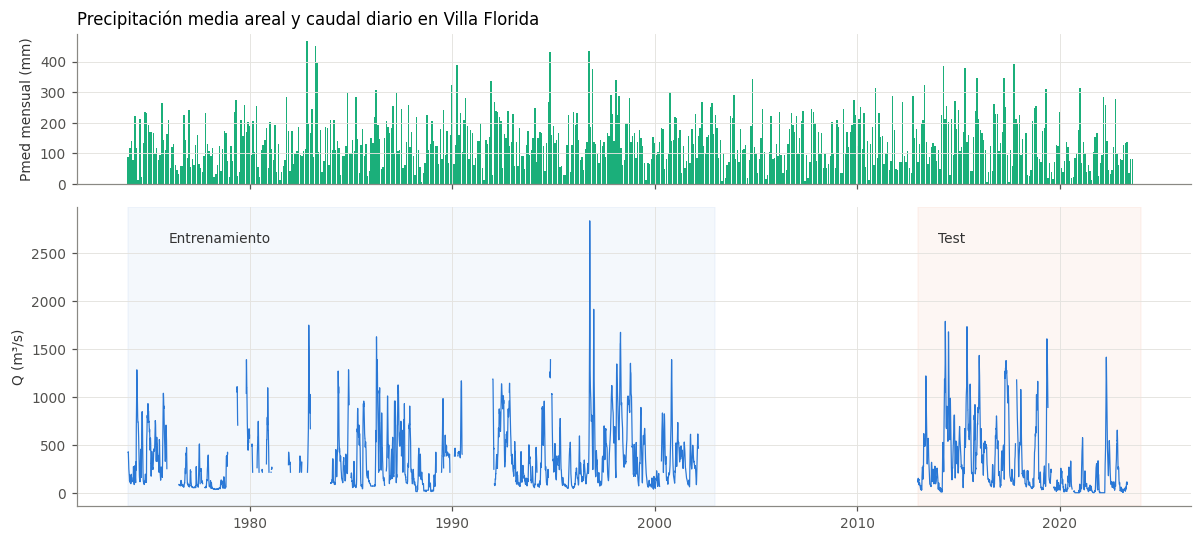

        count   mean    std  min   25%    50%    75%     max
Pmed  18131.0    4.5   11.0  0.0   0.0    0.0    2.9   166.9
Q     11139.0  341.1  320.3  0.9  95.5  232.7  494.5  2836.2


In [11]:
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
pm = Pmed.resample('MS').sum()
axs[0].bar(pm.index, pm.values, width=25, color=C_P)
axs[0].set_ylabel('Pmed mensual (mm)')
axs[1].plot(Q.index, Q.values, color=C_OBS, lw=0.8)
axs[1].set_ylabel('Q (m³/s)')
axs[1].axvspan(pd.Timestamp('1974-01-01'), pd.Timestamp('2002-12-31'), color='#2a78d6', alpha=0.05)
axs[1].axvspan(pd.Timestamp('2013-01-01'), pd.Timestamp('2023-12-31'), color='#eb6834', alpha=0.06)
axs[1].text(pd.Timestamp('1976-01-01'), Q.max() * 0.92, 'Entrenamiento', color='#333')
axs[1].text(pd.Timestamp('2014-01-01'), Q.max() * 0.92, 'Test', color='#333')
axs[0].set_title('Precipitación media areal y caudal diario en Villa Florida', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/series.png', dpi=150); plt.show()

print(serie[['Pmed', 'Q']].describe().round(1).T)

### Tiempo de respuesta de la cuenca

Correlación entre la lluvia del día *t* y la variación del caudal (Δlog Q) *k* días después. El máximo indica el retardo típico entre lluvia y respuesta en Villa Florida, y orienta las ventanas de acumulación a evaluar.

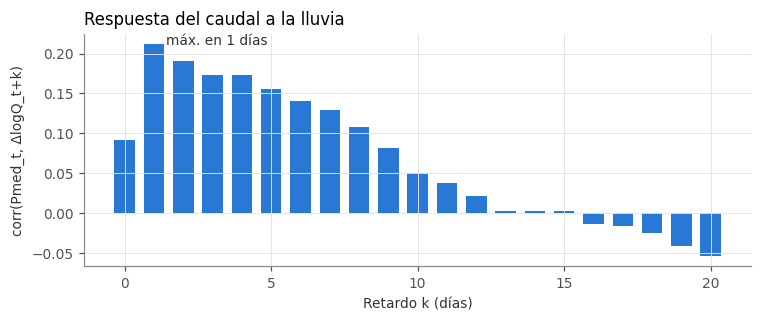

Correlación por retardo: [0.092 0.212 0.19  0.173 0.173 0.156 0.14  0.129 0.107 0.082 0.05  0.037]


In [12]:
dlq = np.log(serie.Q).diff()
lags = range(0, 21)
cc = [serie.Pmed.corr(dlq.shift(-k)) for k in lags]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(lags), cc, color=C_OBS, width=0.7)
k_max = int(np.argmax(cc))
ax.annotate(f'máx. en {k_max} días', (k_max, cc[k_max]), xytext=(8, 0), textcoords='offset points', color='#333')
ax.set_xlabel('Retardo k (días)'); ax.set_ylabel('corr(Pmed_t, ΔlogQ_t+k)')
ax.set_title('Respuesta del caudal a la lluvia', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/correlacion_retardo.png', dpi=150); plt.show()
print('Correlación por retardo:', np.round(cc[:12], 3))

## 5. Feature engineering

Momento de emisión: la mañana del día t+1, cuando ya están disponibles la lectura pluviométrica asignada al día t (convención DMH) y el caudal medio del día t. Variables disponibles en ese momento:

| Grupo | Variables |
|---|---|
| Caudal | log Q en t, t-1, t-2, t-3, t-7; Δlog Q a 1 y 3 días |
| Lluvia acumulada | P1, P3, P5, P7, P10, P15, P30 (mm, suma de *k* días hasta t) |
| Lluvia rezagada | P(t-1), P(t-2) |
| Humedad antecedente | API (índice de precipitación antecedente, k = 0.9) |
| Estacionalidad | mes (categórica → One-Hot) |

Objetivo: `y = log Q(t+h) − log Q(t)`. Modelar la variación relativa en lugar del caudal absoluto permite a los árboles generalizar a caudales fuera del rango de entrenamiento; el caudal se reconstruye como `Q(t) · exp(ŷ)`.

No se usa lluvia futura (sin pronóstico meteorológico), de modo que el modelo es operable con datos observados.

In [13]:
VENT = [1, 3, 5, 7, 10, 15, 30]
API_K = 0.9

def construir_features(df):
    """df: índice diario, columnas Pmed y Q. Devuelve la matriz de features."""
    X = pd.DataFrame(index=df.index)
    lq = np.log(df['Q'])
    for l in [0, 1, 2, 3, 7]:
        X[f'lQ_{l}'] = lq.shift(l)
    X['dlQ_1'] = lq - lq.shift(1)
    X['dlQ_3'] = lq - lq.shift(3)
    for k in VENT:
        X[f'P{k}'] = df['Pmed'].rolling(k, min_periods=k).sum()
    for l in [1, 2]:
        X[f'P_lag{l}'] = df['Pmed'].shift(l)
    p = df['Pmed'].fillna(0).values
    api = np.zeros(len(p))
    for i in range(1, len(p)):
        api[i] = API_K * api[i - 1] + p[i]
    X['API'] = api
    X['mes'] = df.index.month.astype(str)
    return X

X = construir_features(serie)
QCOLS = ['lQ_0', 'lQ_1', 'lQ_2', 'lQ_3', 'lQ_7', 'dlQ_1', 'dlQ_3']
PCOLS = [f'P{k}' for k in VENT] + ['P_lag1', 'P_lag2', 'API']
ALL_COLS = QCOLS + PCOLS + ['mes']

TRAIN = serie.index.year <= 2002
TEST = serie.index.year >= 2013
Q90 = serie.Q[TRAIN].quantile(0.90)
print(f'Umbral de caudal alto (P90 entrenamiento): {Q90:.0f} m³/s')
X.loc[TEST].dropna().head()

Umbral de caudal alto (P90 entrenamiento): 823 m³/s


,lQ_0,lQ_1,lQ_2,lQ_3,lQ_7,dlQ_1,dlQ_3,P1,P3,P5,P7,P10,P15,P30,P_lag1,P_lag2,API,mes
2013-01-08,4.655453,4.655453,5.020350,4.952280,4.762931,0.000000,-0.296827,0.0,20.105347,29.153821,29.153821,69.593914,82.007249,184.404151,11.453674,8.651674,56.071709,1
2013-01-09,4.762931,4.655453,4.655453,5.020350,4.861377,0.107478,-0.257419,0.0,11.453674,28.257669,29.153821,63.625426,81.760034,182.299129,0.000000,11.453674,50.464538,1
2013-01-10,4.907693,4.762931,4.655453,4.655453,4.907693,0.144762,0.252241,0.0,0.000000,20.105347,29.153821,32.878612,72.039144,181.325723,0.000000,0.000000,45.418084,1
2013-01-11,4.952280,4.907693,4.762931,4.655453,4.934644,0.044587,0.296827,0.0,0.000000,11.453674,28.257669,29.153821,71.626535,142.329653,0.000000,0.000000,40.876276,1
2013-01-12,4.861377,4.952280,4.907693,4.762931,4.952280,-0.090903,0.098446,0.0,0.000000,0.000000,20.105347,29.153821,71.553036,130.587831,0.000000,0.000000,36.788648,1


## 6. Pipeline, métricas y línea base

`ColumnTransformer`: numéricas → imputación por mediana + estandarización; mes → One-Hot. El mismo pipeline envuelve a todos los modelos.

Métricas:
- NSE y KGE: desempeño general del hidrograma.
- Skill vs persistencia: `1 − MSE_modelo / MSE_persistencia`. La persistencia (Q(t+h) = Q(t)) es muy exigente en ríos de respuesta lenta; un skill > 0 indica valor agregado real.
- RMSE en caudales altos: error cuando el caudal observado supera el P90 de entrenamiento.

Pesos de muestra: los días cuyo caudal objetivo supera el P90 reciben peso 3 para priorizar el ajuste en crecidas.

In [14]:
def crear_pipeline(modelo, cols):
    num = [c for c in cols if c != 'mes']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['mes'])])
    return Pipeline([('prep', prep), ('modelo', modelo)])

def nse(o, s): return 1 - np.sum((o - s) ** 2) / np.sum((o - o.mean()) ** 2)
def kge(o, s):
    r = np.corrcoef(o, s)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)

def datos_h(h):
    y = np.log(serie.Q.shift(-h)) - np.log(serie.Q)
    ok = y.notna() & X['lQ_0'].notna()
    return y, ok & TRAIN, ok & TEST

def pesos_muestra(h, idx):
    return np.where(serie.Q.shift(-h)[idx] > Q90, 3.0, 1.0)

def evaluar(h, pipe, idx):
    qo = serie.Q.shift(-h)[idx].values
    q0 = serie.Q[idx].values
    qs = q0 * np.exp(pipe.predict(X.loc[idx]))
    alto = qo > Q90
    return dict(NSE=nse(qo, qs), KGE=kge(qo, qs),
                Skill_pers=1 - np.mean((qo - qs) ** 2) / np.mean((qo - q0) ** 2),
                RMSE=np.sqrt(np.mean((qo - qs) ** 2)),
                RMSE_alto=np.sqrt(np.mean((qo[alto] - qs[alto]) ** 2)),
                PBIAS_alto=100 * (qs[alto].sum() - qo[alto].sum()) / qo[alto].sum()), qs

def entrenar(h, modelo, cols, peso=True):
    y, itr, _ = datos_h(h)
    pipe = crear_pipeline(modelo, cols)
    pipe.fit(X.loc[itr, cols], y[itr], modelo__sample_weight=pesos_muestra(h, itr) if peso else None)
    return pipe

lgbm = lambda: LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=30,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED)

HORIZ = [1, 2, 3, 5, 7]
base = []
for h in HORIZ:
    _, _, ite = datos_h(h)
    qo, q0 = serie.Q.shift(-h)[ite].values, serie.Q[ite].values
    alto = qo > Q90
    base.append(dict(h=h, NSE=nse(qo, q0), KGE=kge(qo, q0), RMSE=np.sqrt(np.mean((qo - q0) ** 2)),
                     RMSE_alto=np.sqrt(np.mean((qo[alto] - q0[alto]) ** 2))))
base = pd.DataFrame(base).set_index('h')
print('Persistencia en test (Q(t+h) = Q(t)):')
base.round(3)

Persistencia en test (Q(t+h) = Q(t)):


,NSE,KGE,RMSE,RMSE_alto
h,,,,
1,0.992,0.996,30.392,69.391
2,0.974,0.987,54.312,120.814
3,0.948,0.974,76.852,172.401
5,0.878,0.939,117.240,261.917
7,0.794,0.897,152.337,337.191


## 7. Ablación: ¿qué ventana de lluvia aporta más?

Se entrena LightGBM con el mismo pipeline cambiando solo el conjunto de variables:
- `Q`: solo variables de caudal (el modelo aprende la curva de recesión).
- `Q+Pk`: caudal + lluvia acumulada de *k* días.
- `Q+todas`: caudal + todas las variables de lluvia.

In [15]:
conjuntos = {'Q': QCOLS, **{f'Q+P{k}': QCOLS + [f'P{k}'] for k in VENT}, 'Q+todas': QCOLS + PCOLS}
filas = []
for h in HORIZ:
    _, _, ite = datos_h(h)
    for nombre, cols in conjuntos.items():
        pipe = entrenar(h, lgbm(), cols + ['mes'])
        m, _ = evaluar(h, pipe, ite)
        filas.append(dict(h=h, conjunto=nombre, **m))
abl = pd.DataFrame(filas)
orden = list(conjuntos)
tab_skill = abl.pivot(index='conjunto', columns='h', values='Skill_pers').loc[orden]
tab_alto = abl.pivot(index='conjunto', columns='h', values='RMSE_alto').loc[orden]
print('Skill vs persistencia (test):'); print(tab_skill.round(3))
print('\nRMSE en caudales altos, m³/s (test):'); print(tab_alto.round(0))

Skill vs persistencia (test):
h             1      2      3      5      7
conjunto                                   
Q         0.372  0.427  0.420  0.388  0.353
Q+P1      0.400  0.437  0.444  0.433  0.423
Q+P3      0.387  0.440  0.447  0.454  0.450
Q+P5      0.403  0.468  0.484  0.508  0.494
Q+P7      0.423  0.496  0.535  0.532  0.504
Q+P10     0.421  0.508  0.528  0.523  0.501
Q+P15     0.440  0.507  0.523  0.512  0.492
Q+P30     0.391  0.442  0.453  0.424  0.393
Q+todas   0.457  0.526  0.541  0.559  0.557

RMSE en caudales altos, m³/s (test):
h            1     2      3      5      7
conjunto                                 
Q         58.0  93.0  135.0  205.0  270.0
Q+P1      57.0  94.0  135.0  201.0  254.0
Q+P3      57.0  94.0  136.0  198.0  245.0
Q+P5      57.0  91.0  128.0  181.0  230.0
Q+P7      55.0  87.0  117.0  173.0  228.0
Q+P10     56.0  85.0  120.0  179.0  229.0
Q+P15     54.0  86.0  120.0  181.0  234.0
Q+P30     58.0  92.0  129.0  198.0  258.0
Q+todas   54.0  86.0  122.0 

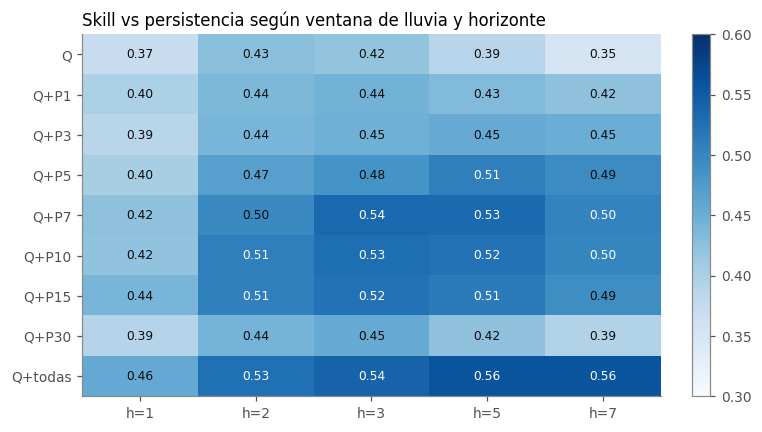

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(tab_skill.values, cmap='Blues', aspect='auto', vmin=0.3, vmax=0.6)
ax.set_xticks(range(len(HORIZ))); ax.set_xticklabels([f'h={h}' for h in HORIZ])
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden); ax.grid(False)
for i in range(len(orden)):
    for j in range(len(HORIZ)):
        v = tab_skill.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.5 else '#0b0b0b')
ax.set_title('Skill vs persistencia según ventana de lluvia y horizonte', loc='left')
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.savefig(f'{FIG}/ablacion_ventanas.png', dpi=150); plt.show()

In [17]:
ganancia = (tab_skill.drop(index='Q') - tab_skill.loc['Q'])
print('Ganancia de skill por agregar lluvia respecto al modelo solo-caudal:')
print(ganancia.round(3))
mejor = ganancia.drop(index='Q+todas').idxmax()
print('\nMejor ventana individual por horizonte:', mejor.to_dict())

Ganancia de skill por agregar lluvia respecto al modelo solo-caudal:
h             1      2      3      5      7
conjunto                                   
Q+P1      0.028  0.010  0.023  0.044  0.070
Q+P3      0.015  0.013  0.027  0.066  0.097
Q+P5      0.031  0.041  0.064  0.120  0.140
Q+P7      0.051  0.069  0.115  0.144  0.150
Q+P10     0.049  0.081  0.108  0.135  0.148
Q+P15     0.068  0.080  0.103  0.124  0.139
Q+P30     0.019  0.015  0.033  0.036  0.039
Q+todas   0.085  0.098  0.121  0.170  0.204

Mejor ventana individual por horizonte: {1: 'Q+P15', 2: 'Q+P10', 3: 'Q+P7', 5: 'Q+P7', 7: 'Q+P7'}


## 8. Comparación de modelos (h = 3 días)

Horizonte principal: 3 días. Es el horizonte en el que la lluvia antecedente agrega más valor respecto al modelo solo-caudal manteniendo un NSE alto, y ofrece un margen operativo útil para una alerta.

In [18]:
H = 3
modelos = {
    'Ridge': lambda: Ridge(alpha=1.0),
    'RandomForest': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    'XGBoost': lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=5, subsample=0.8,
                                    colsample_bytree=0.8, random_state=SEED),
    'LightGBM': lgbm}
_, _, ite = datos_h(H)
comp = []
for n, f in modelos.items():
    for peso in [False, True]:
        m, _ = evaluar(H, entrenar(H, f(), ALL_COLS, peso), ite)
        comp.append(dict(modelo=n, peso_altos=peso, **m))
comp = pd.DataFrame(comp)
comp.round(3)

,modelo,peso_altos,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto
0,Ridge,False,0.967,0.978,0.375,60.755,142.540,0.286
1,Ridge,True,0.969,0.981,0.409,59.078,136.177,0.011
2,RandomForest,False,0.976,0.981,0.536,52.366,121.854,-2.291
3,RandomForest,True,0.976,0.981,0.535,52.393,121.648,-2.360
4,XGBoost,False,0.976,0.978,0.544,51.889,122.659,-2.399
5,XGBoost,True,0.976,0.980,0.542,52.016,120.764,-2.580
6,LightGBM,False,0.976,0.974,0.534,52.477,124.899,-3.104
7,LightGBM,True,0.976,0.980,0.541,52.063,121.844,-2.623


## 9. Optimización de hiperparámetros (LightGBM, validación cruzada temporal)

`RandomizedSearchCV` con `TimeSeriesSplit` (4 bloques, 15 combinaciones) sobre el período de entrenamiento: cada bloque de validación es posterior a su bloque de entrenamiento, sin fuga de información futura.

In [19]:
y, itr, ite = datos_h(H)
busqueda = RandomizedSearchCV(
    crear_pipeline(LGBMRegressor(verbose=-1, random_state=SEED, subsample_freq=1, n_jobs=2), ALL_COLS),
    param_distributions={
        'modelo__n_estimators': [200, 400, 600],
        'modelo__learning_rate': [0.01, 0.02, 0.03, 0.05],
        'modelo__num_leaves': [15, 31, 63],
        'modelo__min_child_samples': [10, 20, 30, 50],
        'modelo__subsample': [0.7, 0.8, 0.9],
        'modelo__colsample_bytree': [0.6, 0.8, 1.0],
        'modelo__reg_lambda': [0, 1, 5]},
    n_iter=15, cv=TimeSeriesSplit(n_splits=4), scoring='neg_mean_squared_error', random_state=SEED, n_jobs=1)
busqueda.fit(X.loc[itr, ALL_COLS], y[itr], modelo__sample_weight=pesos_muestra(H, itr))
MEJORES = {k.replace('modelo__', ''): v for k, v in busqueda.best_params_.items()}
print('Mejores hiperparámetros:', MEJORES)

m_tuned, qs_test = evaluar(H, busqueda.best_estimator_, ite)
m_def = comp.query('modelo == "LightGBM" and peso_altos')[['NSE', 'KGE', 'Skill_pers', 'RMSE', 'RMSE_alto', 'PBIAS_alto']].iloc[0]
pd.DataFrame({'LightGBM por defecto': m_def, 'LightGBM optimizado': pd.Series(m_tuned),
              'Persistencia': base.loc[H]}).round(3)

Mejores hiperparámetros: {'subsample': 0.7, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 10, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


,LightGBM por defecto,LightGBM optimizado,Persistencia
KGE,0.980,0.983,0.974
NSE,0.976,0.976,0.948
PBIAS_alto,-2.623,-2.148,NaN
RMSE,52.063,52.068,76.852
RMSE_alto,121.844,120.353,172.401
Skill_pers,0.541,0.541,NaN


## 10. Sensibilidad al tratamiento de faltantes (escenarios A, B, C)

Mismo modelo (LightGBM optimizado, h = 3), cambiando solo la precipitación de entrada o los días de entrenamiento.

In [20]:
mk = lambda **kw: LGBMRegressor(verbose=-1, random_state=SEED, subsample_freq=1, **{**MEJORES, **kw})
serie_A = serie.copy()
esc = {}
for nom, pm, descartar in [('A: Thiessen dinámico', Pmed, False), ('B: faltante = 0', Pmed_B, False),
                           ('C: A + descarte cobertura < 50 %', Pmed, True)]:
    serie = serie_A.copy(); serie['Pmed'] = pm
    X = construir_features(serie)
    y, itr, ite = datos_h(H)
    if descartar:
        itr = itr & ~(serie.cob_red.rolling(10, min_periods=1).min() < 0.5)
    pipe = crear_pipeline(mk(), ALL_COLS)
    pipe.fit(X.loc[itr, ALL_COLS], y[itr], modelo__sample_weight=pesos_muestra(H, itr))
    esc[nom], _ = evaluar(H, pipe, ite)
    esc[nom]['n_train'] = int(itr.sum())
serie = serie_A.copy(); X = construir_features(serie)   # se restituye el escenario A
esc = pd.DataFrame(esc).T
R['escenarios_faltantes'] = esc.round(4).to_dict(orient='index')
esc.round(3)

,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto,n_train
A: Thiessen dinámico,0.976,0.983,0.541,52.068,120.353,-2.148,7381.0
B: faltante = 0,0.976,0.985,0.541,52.087,118.437,-1.768,7381.0
C: A + descarte cobertura < 50 %,0.976,0.985,0.541,52.047,118.531,-1.705,5657.0


El tratamiento de los faltantes cambia el balance hídrico (B subestima la lluvia anual) pero casi no cambia el desempeño del modelo en test, porque en 2013–2023 la red está prácticamente completa y los árboles se adaptan a un sesgo sistemático. El escenario A es el correcto desde el punto de vista hidrológico y se mantiene.

## 11. Modelos finales (h = 1, 2, 3)

Configuración usada en todos los gráficos y tablas siguientes: **un único modelo LightGBM por horizonte, entrenado con todas las variables juntas** (caudales recientes y tendencias, P1, P3, P5, P7, P10, P15, P30, lluvia rezagada, API y mes; conjunto `Q+todas`). No es un promedio de varios modelos: cada LightGBM es internamente un conjunto de árboles de decisión.

In [21]:
finales, metricas = {}, {}
for h in [1, 2, 3]:
    finales[h] = entrenar(h, mk(), ALL_COLS)
    _, _, ite_h = datos_h(h)
    metricas[h], _ = evaluar(h, finales[h], ite_h)
metricas_df = pd.DataFrame(metricas).T
metricas_df.index.name = 'h'
metricas_df = metricas_df.join(base[['NSE', 'RMSE_alto']].rename(columns={'NSE': 'NSE_pers', 'RMSE_alto': 'RMSE_alto_pers'}))
R['metricas_finales'] = metricas_df.round(4).to_dict(orient='index')
metricas_df.round(3)

,NSE,KGE,Skill_pers,RMSE,RMSE_alto,PBIAS_alto,NSE_pers,RMSE_alto_pers
h,,,,,,,,
1,0.996,0.997,0.464,22.257,53.900,-0.459,0.992,69.391
2,0.988,0.991,0.529,37.271,84.386,-1.275,0.974,120.814
3,0.976,0.983,0.541,52.068,120.353,-2.148,0.948,172.401


In [22]:
def serie_pronostico(h, pipe, XX=None):
    """Devuelve observado, modelo y persistencia indexados por la FECHA OBJETIVO (t + h)."""
    XX = X if XX is None else XX
    _, _, ite_h = datos_h(h)
    idx = ite_h[ite_h].index
    q0 = serie.Q[idx].values
    d = pd.DataFrame({'obs': serie.Q.shift(-h)[idx].values,
                      'mod': q0 * np.exp(pipe.predict(XX.loc[idx])),
                      'pers': q0}, index=idx + pd.Timedelta(days=h))
    return d.asfreq('D')

SP = {h: serie_pronostico(h, finales[h]) for h in [1, 2, 3]}
sp = SP[H]

## 12. Evaluación de la serie completa (test 2013–2023)

Primero se verifica que el modelo represente bien el comportamiento general del río (estiajes, caudales medios, recesiones); después se analizan los extremos, que tienen mayor incertidumbre.

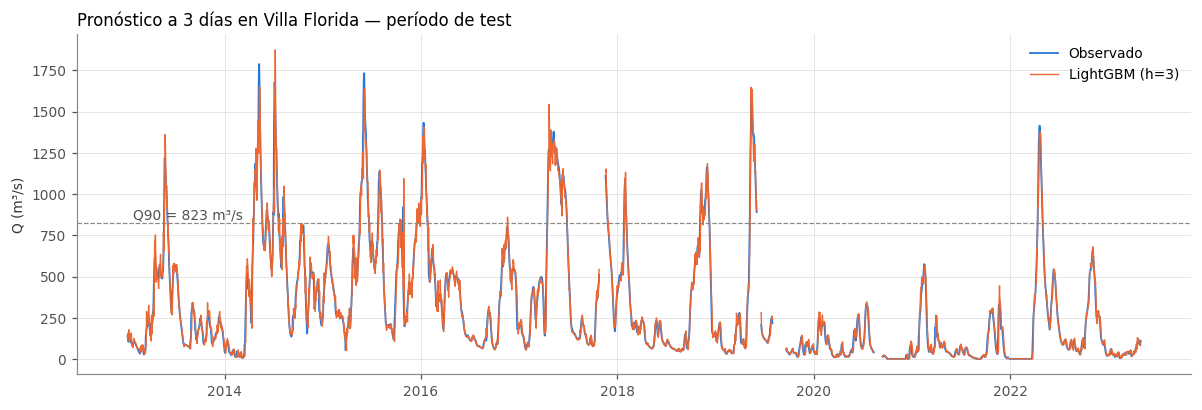

In [23]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(sp.index, sp.obs, color=C_OBS, lw=1.2, label='Observado')
ax.plot(sp.index, sp['mod'], color=C_MOD, lw=0.9, label=f'LightGBM (h={H})')
ax.axhline(Q90, color='#8a8984', lw=0.8, ls='--'); ax.text(sp.index[20], Q90 * 1.03, 'Q90 = 823 m³/s', color='#52514e')
ax.set_ylabel('Q (m³/s)'); ax.legend(loc='upper right')
ax.set_title(f'Pronóstico a {H} días en Villa Florida — período de test', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/hidrograma_test.png', dpi=150); plt.show()

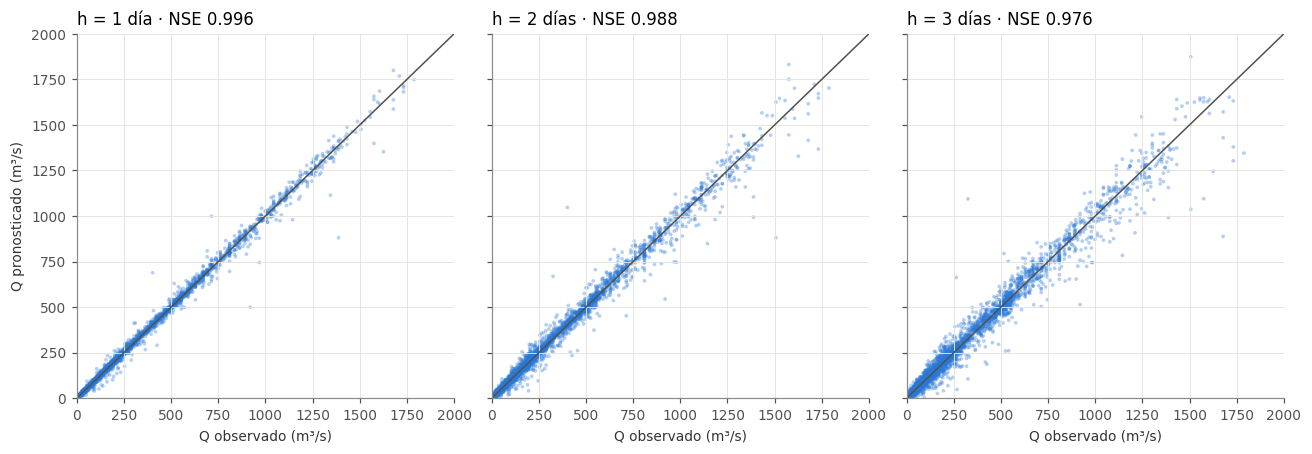

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
for ax, h in zip(axs, [1, 2, 3]):
    d = SP[h].dropna()
    ax.scatter(d.obs, d['mod'], s=6, color=C_OBS, alpha=0.35, edgecolors='none')
    lim = [0, 2000]
    ax.plot(lim, lim, color='#52514e', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'h = {h} día{"s" if h > 1 else ""} · NSE {metricas[h]["NSE"]:.3f}', loc='left')
    ax.set_xlabel('Q observado (m³/s)')
axs[0].set_ylabel('Q pronosticado (m³/s)')
plt.tight_layout(); plt.savefig(f'{FIG}/dispersion.png', dpi=150); plt.show()

### Curva de permanencia

Compara la distribución de caudales observados y pronosticados: si coinciden, el modelo reproduce la frecuencia de estiajes, caudales medios y crecidas.

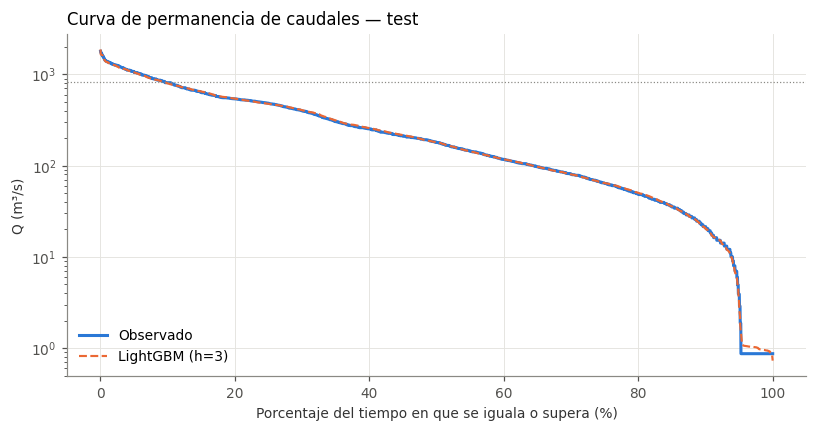

In [25]:
d = sp.dropna()
exc = np.arange(1, len(d) + 1) / (len(d) + 1) * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(exc, np.sort(d.obs.values)[::-1], color=C_OBS, lw=2, label='Observado')
ax.plot(exc, np.sort(d['mod'].values)[::-1], color=C_MOD, lw=1.4, ls='--', label=f'LightGBM (h={H})')
ax.set_yscale('log'); ax.set_xlabel('Porcentaje del tiempo en que se iguala o supera (%)'); ax.set_ylabel('Q (m³/s)')
ax.axhline(Q90, color='#8a8984', lw=0.8, ls=':')
ax.legend(); ax.set_title('Curva de permanencia de caudales — test', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/curva_permanencia.png', dpi=150); plt.show()

In [26]:
Q25 = serie.Q[TRAIN].quantile(0.25)
clases = pd.cut(d.obs, [0, Q25, Q90, np.inf], labels=[f'Bajo (< {Q25:.0f})', f'Medio ({Q25:.0f}–{Q90:.0f})', f'Alto (> {Q90:.0f})'])
filas = []
for c, g in d.groupby(clases, observed=True):
    for nom, col in [('LightGBM', 'mod'), ('Persistencia', 'pers')]:
        e = g[col] - g.obs
        filas.append(dict(clase=c, modelo=nom, n=len(g), RMSE=np.sqrt((e ** 2).mean()),
                          RMSE_rel_pct=100 * np.sqrt((e ** 2).mean()) / g.obs.mean(), PBIAS_pct=100 * e.sum() / g.obs.sum()))
tab_clases = pd.DataFrame(filas)
R['clases'] = tab_clases.round(3).to_dict(orient='records'); R['Q25'] = float(Q25)
tab_clases.round(2)

,clase,modelo,n,RMSE,RMSE_rel_pct,PBIAS_pct
0,Bajo (< 112),LightGBM,1415,14.56,29.50,4.05
1,Bajo (< 112),Persistencia,1415,18.72,37.93,6.53
2,Medio (112–823),LightGBM,1881,49.12,13.75,0.78
3,Medio (112–823),Persistencia,1881,75.36,21.09,0.17
4,Alto (> 823),LightGBM,348,120.35,10.82,-2.15
5,Alto (> 823),Persistencia,348,172.40,15.49,-1.58


### Validez del pronóstico a 3 días según la curva de permanencia y el estado del río

In [27]:
q_tr = serie.Q[TRAIN].dropna()
PERM = {p: float(q_tr.quantile(1 - p / 100)) for p in [2, 5, 10, 25, 50, 75]}
cortes = [0, PERM[75], PERM[50], PERM[25], PERM[10], PERM[5], PERM[2], np.inf]
etq = ['Superado > 75 % del tiempo', '50–75 %', '25–50 %', '10–25 %', '5–10 %', '2–5 %', 'Superado < 2 % del tiempo']
dv = sp.dropna().copy()
dv['err'] = (dv['mod'] - dv.obs) / dv.obs
dv['subiendo'] = dv.obs / dv.pers > 1.10
dv['tramo'] = pd.cut(dv.obs, cortes, labels=etq)
def resumen_err(g):
    return pd.Series({'dias': len(g), 'error_tipico_pct': 100 * g.err.abs().median(), 'dentro_10pct': 100 * (g.err.abs() <= 0.10).mean(),
                      'dentro_20pct': 100 * (g.err.abs() <= 0.20).mean(), 'sesgo_pct': 100 * (g['mod'].sum() - g.obs.sum()) / g.obs.sum()})
val_perm = dv.groupby('tramo', observed=True).apply(resumen_err).iloc[::-1]
val_perm.insert(0, 'caudal_m3s', [f'> {PERM[2]:.0f}', f'{PERM[5]:.0f}–{PERM[2]:.0f}', f'{PERM[10]:.0f}–{PERM[5]:.0f}', f'{PERM[25]:.0f}–{PERM[10]:.0f}',
                                  f'{PERM[50]:.0f}–{PERM[25]:.0f}', f'{PERM[75]:.0f}–{PERM[50]:.0f}', f'< {PERM[75]:.0f}'][:len(val_perm)])
val_estado = pd.DataFrame({'Río estable o bajando': resumen_err(dv[~dv.subiendo]), 'Río subiendo (> 10 % en 3 días)': resumen_err(dv[dv.subiendo]),
                           'Caudal alto (> Q90) y subiendo': resumen_err(dv[dv.subiendo & (dv.obs > Q90)]),
                           'Caudal alto (> Q90) sin subida': resumen_err(dv[~dv.subiendo & (dv.obs > Q90)]), 'Todo el período': resumen_err(dv)}).T
R['validez'] = {'permanencia': val_perm.reset_index().round(2).to_dict(orient='records'), 'estado': val_estado.round(2).to_dict(orient='index'),
                'umbrales_permanencia': PERM, 'max_test': float(sp.obs.max())}
display(val_perm.round(1)); display(val_estado.round(1))

,caudal_m3s,dias,error_tipico_pct,dentro_10pct,dentro_20pct,sesgo_pct
tramo,,,,,,
Superado < 2 % del tiempo,> 1180,120.0,5.8,73.3,90.8,-3.3
2–5 %,993–1180,104.0,3.8,80.8,97.1,-1.1
5–10 %,823–993,124.0,4.4,83.9,93.5,-1.5
10–25 %,500–823,505.0,5.0,81.0,96.6,0.1
25–50 %,263–500,548.0,5.8,69.7,89.2,1.4
50–75 %,112–263,828.0,9.0,52.7,76.2,1.4
Superado > 75 % del tiempo,< 112,1415.0,15.7,36.8,59.6,4.1


,dias,error_tipico_pct,dentro_10pct,dentro_20pct,sesgo_pct
Río estable o bajando,2597.0,7.1,61.3,80.1,3.9
Río subiendo (> 10 % en 3 días),1047.0,12.5,41.2,66.7,-9.7
Caudal alto (> Q90) y subiendo,86.0,11.8,43.0,76.7,-12.4
Caudal alto (> Q90) sin subida,262.0,3.8,91.2,99.2,1.4
Todo el período,3644.0,8.5,55.5,76.2,-0.0


## 13. Análisis de extremos

### Eventos de crecida en test

Picos observados mayores a Q90, separados al menos 20 días. Para cada uno: pico observado, valor pronosticado para ese mismo día (emitido 3 días antes), máximo pronosticado en ±5 días y desfase entre la fecha del máximo pronosticado y la del pico observado.

In [28]:
from scipy.signal import find_peaks
o = sp.obs.interpolate(limit=3)
picos, _ = find_peaks(o.fillna(0).values, height=Q90, distance=20)
ev = []
for i in picos:
    t = o.index[i]
    win = sp.loc[t - pd.Timedelta(days=5): t + pd.Timedelta(days=5)]
    ev.append(dict(fecha=t.date(), Q_obs=sp.obs[t], Q_mod_mismo_dia=sp['mod'][t], Q_pers_mismo_dia=sp.pers[t],
                   Q_mod_max_5d=win['mod'].max(), desfase_mod_dias=(win['mod'].idxmax() - t).days,
                   desfase_pers_dias=(win.pers.idxmax() - t).days))
eventos = pd.DataFrame(ev)
eventos['error_pico_mod_pct'] = 100 * (eventos.Q_mod_mismo_dia - eventos.Q_obs) / eventos.Q_obs
eventos['error_pico_pers_pct'] = 100 * (eventos.Q_pers_mismo_dia - eventos.Q_obs) / eventos.Q_obs
R['eventos'] = eventos.assign(fecha=eventos.fecha.astype(str)).round(2).to_dict(orient='records')
eventos.round(1)

,fecha,Q_obs,Q_mod_mismo_dia,Q_pers_mismo_dia,Q_mod_max_5d,desfase_mod_dias,desfase_pers_dias,error_pico_mod_pct,error_pico_pers_pct
0,2013-05-23,1218.9,1063.7,899.3,1360.4,1,3,-12.7,-26.2
1,2014-05-09,1788.1,1345.5,1344.6,1652.8,1,3,-24.8,-24.8
2,2014-06-06,902.2,891.8,805.0,946.8,2,3,-1.1,-10.8
3,2014-07-05,1678.3,888.2,874.1,1874.8,3,3,-47.1,-47.9
4,2014-08-08,985.8,744.7,746.1,1047.2,1,3,-24.5,-24.3
5,2015-06-03,1732.3,1379.4,1387.9,1639.7,2,3,-20.4,-19.9
6,2015-07-30,1133.3,990.4,949.1,1146.6,1,3,-12.6,-16.3
7,2015-10-26,919.5,513.9,669.9,1094.3,3,3,-44.1,-27.1
8,2015-12-21,890.8,913.0,852.2,945.1,3,3,2.5,-4.3
9,2016-01-11,1432.5,1282.8,1270.1,1403.2,1,3,-10.5,-11.3


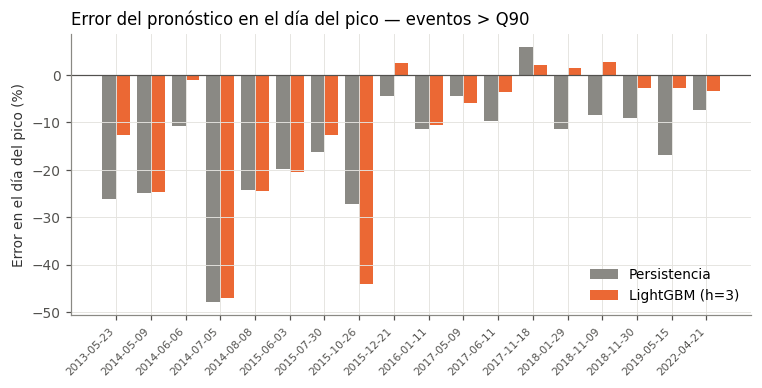

In [29]:
fig, ax = plt.subplots(figsize=(7, 3.6))
xx = np.arange(len(eventos))
ax.bar(xx - 0.2, eventos.error_pico_pers_pct, width=0.4, color=C_PERS, label='Persistencia')
ax.bar(xx + 0.2, eventos.error_pico_mod_pct, width=0.4, color=C_MOD, label=f'LightGBM (h={H})')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels([str(f) for f in eventos.fecha], rotation=45, ha='right', fontsize=7)
ax.set_ylabel('Error en el día del pico (%)'); ax.legend()
ax.set_title('Error del pronóstico en el día del pico — eventos > Q90', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/error_picos.png', dpi=150); plt.show()

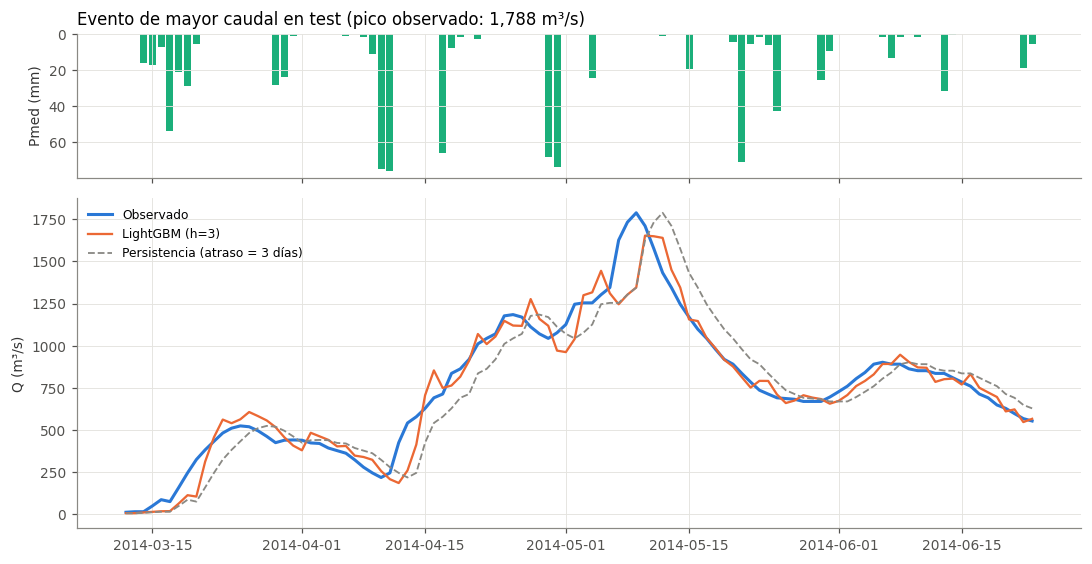

In [30]:
t_pico = sp.obs.idxmax()   # fecha del pico observado máximo del test
ventana = slice(t_pico - pd.Timedelta(days=58), t_pico + pd.Timedelta(days=45))
def grafico_evento(ventana, extra=None, fn='evento_pico.png', titulo=None):
    fig, axs = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={'height_ratios': [1, 2.3]})
    pe = serie.Pmed[ventana]
    axs[0].bar(pe.index, pe.values, color=C_P, width=0.8); axs[0].invert_yaxis(); axs[0].set_ylabel('Pmed (mm)')
    e = sp[ventana]
    if extra is not None: extra(axs[1])
    axs[1].plot(e.index, e.obs, color=C_OBS, lw=2, label='Observado')
    axs[1].plot(e.index, e['mod'], color=C_MOD, lw=1.5, label=f'LightGBM (h={H})')
    axs[1].plot(e.index, e.pers, color=C_PERS, lw=1.2, ls='--', label='Persistencia (atraso = 3 días)')
    axs[1].set_ylabel('Q (m³/s)'); axs[1].legend(loc='upper left', fontsize=8)
    axs[0].set_title(titulo or f'Evento de mayor caudal en test (pico observado: {e.obs.max():,.0f} m³/s)', loc='left')
    plt.tight_layout(); plt.savefig(f'{FIG}/{fn}', dpi=150); plt.show()
grafico_evento(ventana)

## 14. Desfase temporal (error de fase)

En los hidrogramas el pronóstico aparece desplazado hacia la derecha: las subidas llegan tarde. Para medirlo, la serie pronosticada se desplaza L días y se busca el L que maximiza el NSE contra la observada. La persistencia a h días tiene, por definición, un atraso de h días.

Atraso que maximiza el NSE (días):
LightGBM h=1        1
LightGBM h=2        1
LightGBM h=3        1
Persistencia h=3    3
dtype: int64


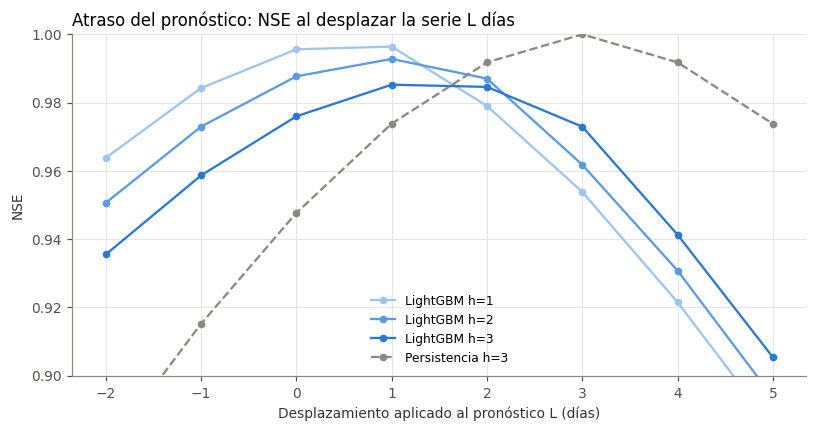

In [31]:
def curva_desfase(o, s, Ls=range(-2, 6)):
    res = {}
    for L in Ls:
        b = s.shift(-L); m = o.notna() & b.notna()
        res[L] = nse(o[m].values, b[m].values)
    return pd.Series(res)
cd = pd.DataFrame({f'LightGBM h={h}': curva_desfase(SP[h].obs, SP[h]['mod']) for h in [1, 2, 3]})
cd['Persistencia h=3'] = curva_desfase(sp.obs, sp.pers)
atraso = cd.idxmax()
R['desfase'] = {k: int(v) for k, v in atraso.items()}
print('Atraso que maximiza el NSE (días):'); print(atraso)
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, c, ls in zip(cd.columns, ['#9ec5f0', '#5a9be3', C_OBS, C_PERS], ['-', '-', '-', '--']):
    ax.plot(cd.index, cd[col], marker='o', ms=4, color=c, ls=ls, label=col)
ax.set_xlabel('Desplazamiento aplicado al pronóstico L (días)'); ax.set_ylabel('NSE')
ax.set_ylim(0.9, 1.0); ax.legend(fontsize=8)
ax.set_title('Atraso del pronóstico: NSE al desplazar la serie L días', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/desfase.png', dpi=150); plt.show()

### ¿Se puede reducir el atraso? Experimentos (h = 3)

1. Base: modelo final.
2. Lluvia por zonas: la Pmed se divide en zona baja (cercana al cierre: Quyquyho, San Juan Bautista, Paraguarí) y zona alta (Caazapá, Villarrica, Cnel. Oviedo, Encarnación), porque la lluvia cercana al cierre llega antes.
3. Peso a la rama ascendente: los días en que el caudal sube más de 10 % reciben el doble de peso.
4. Lluvia futura perfecta: se agrega la lluvia observada de t+1 a t+3, como si existiera un pronóstico meteorológico perfecto (cota superior, no operable).
5. Lluvia futura con error: el modelo anterior alimentado con esa lluvia perturbada (error multiplicativo log-normal, σ = 0,8), similar a un pronóstico meteorológico real.

In [32]:
y, itr, ite = datos_h(H)
qo_t, q0_t = serie.Q.shift(-H)[ite].values, serie.Q[ite].values
sube = qo_t / q0_t > 1.10
def met_exp(qs, lag=None):
    alto = qo_t > Q90
    return dict(NSE=nse(qo_t, qs), Skill_pers=1 - np.mean((qo_t - qs) ** 2) / np.mean((qo_t - q0_t) ** 2),
                RMSE_alto=np.sqrt(np.mean((qo_t[alto] - qs[alto]) ** 2)), RMSE_ascenso=np.sqrt(np.mean((qo_t[sube] - qs[sube]) ** 2)),
                atraso_dias=lag)
def atraso_de(qs):
    s = pd.Series(qs, index=ite[ite].index + pd.Timedelta(days=H)).asfreq('D')
    o_ = pd.Series(qo_t, index=s.dropna().index).asfreq('D')
    return int(curva_desfase(o_, s).idxmax())

EXP = {}
qs = q0_t * np.exp(finales[H].predict(X.loc[ite])); EXP['1. Base'] = met_exp(qs, atraso_de(qs))
# 2. zonas
ZB = ['Quyquyho', 'San_Juan_Bautista', 'Paraguari']; ZA = ['Caazapa', 'Villarrica', 'Coronel_Oviedo', 'Encarnacion', 'Pilar']
Xz = X.copy(); Pz = P.fillna(0)
for nom, Z in [('Pb', ZB), ('Pa', ZA)]:
    pz = ((Wdf[Z] * Pz[Z]).sum(1) / Wdf[Z].sum(1)).where(Wdf[Z].sum(1) > 0)
    for k in [1, 3, 5, 7, 10, 15]:
        Xz[f'{nom}{k}'] = pz.rolling(k, min_periods=k).sum()
ZCOLS = [c for c in Xz.columns if c[:2] in ('Pb', 'Pa')]
p2 = crear_pipeline(mk(), ALL_COLS[:-1] + ZCOLS + ['mes']); p2.fit(Xz.loc[itr], y[itr], modelo__sample_weight=pesos_muestra(H, itr))
qs = q0_t * np.exp(p2.predict(Xz.loc[ite])); EXP['2. Lluvia por zonas'] = met_exp(qs, atraso_de(qs))
# 3. peso a rama ascendente
w_asc = pesos_muestra(H, itr) * np.where(serie.Q.shift(-H)[itr].values / serie.Q[itr].values > 1.10, 2.0, 1.0)
p3 = crear_pipeline(mk(), ALL_COLS); p3.fit(X.loc[itr], y[itr], modelo__sample_weight=w_asc)
qs = q0_t * np.exp(p3.predict(X.loc[ite])); EXP['3. Peso rama ascendente'] = met_exp(qs, atraso_de(qs))
# 4. lluvia futura perfecta
Xf = X.copy()
for k in range(1, H + 1): Xf[f'Pf{k}'] = serie.Pmed.shift(-k)
Xf['Pfut'] = Xf[[f'Pf{k}' for k in range(1, H + 1)]].sum(1, min_count=H)
FUT = ALL_COLS[:-1] + [f'Pf{k}' for k in range(1, H + 1)] + ['Pfut', 'mes']
p4 = crear_pipeline(mk(), FUT); p4.fit(Xf.loc[itr], y[itr], modelo__sample_weight=pesos_muestra(H, itr))
qs = q0_t * np.exp(p4.predict(Xf.loc[ite])); EXP['4. Lluvia futura perfecta'] = met_exp(qs, atraso_de(qs))
# 5. lluvia futura con error
rng = np.random.default_rng(SEED); Xn = Xf.copy()
for k in range(1, H + 1): Xn[f'Pf{k}'] = Xf[f'Pf{k}'] * np.exp(rng.normal(-0.5 * 0.8 ** 2, 0.8, len(Xf)))
Xn['Pfut'] = Xn[[f'Pf{k}' for k in range(1, H + 1)]].sum(1, min_count=H)
qs = q0_t * np.exp(p4.predict(Xn.loc[ite])); EXP['5. Lluvia futura con error'] = met_exp(qs, atraso_de(qs))
EXP = pd.DataFrame(EXP).T
R['experimentos_desfase'] = EXP.round(4).to_dict(orient='index')
EXP.round(3)

,NSE,Skill_pers,RMSE_alto,RMSE_ascenso,atraso_dias
1. Base,0.976,0.541,120.353,74.010,1.0
2. Lluvia por zonas,0.977,0.554,116.526,71.690,1.0
3. Peso rama ascendente,0.976,0.532,119.258,69.749,1.0
4. Lluvia futura perfecta,0.977,0.566,115.615,71.772,1.0
5. Lluvia futura con error,0.977,0.556,116.827,73.053,1.0


Ninguna variante elimina el día de atraso residual. La lluvia futura perfecta mejora poco porque, a 3 días, la mayor parte del caudal ya está en tránsito por la red de drenaje. El atraso residual se explica por información que el modelo no tiene: la ubicación y la intensidad real de la lluvia dentro de la cuenca (8 pluviómetros para 21 000 km², resolución diaria) y el caudal que ya viene aguas arriba. Además, un modelo entrenado para minimizar el error cuadrático tiende a "suavizar" los cambios bruscos; subestimar la magnitud de una subida se ve en el gráfico como un atraso.

Nota sobre el evento de mayo de 2014: entre la emisión (6 de mayo) y el pico (9 de mayo) no llovió; la subida respondió a lluvias ya registradas (146 mm en los 10 días previos) caídas sobre un río que ya venía alto. En el entrenamiento, con Q > 1 000 m³/s y P10 > 120 mm, el caudal subió en mediana solo 7 % en 3 días; en 2014 subió 33 %. El modelo subestima por ser una situación poco frecuente en el registro. En cambio, el error de octubre de 2015 sí corresponde a lluvia posterior a la emisión (83 mm).

## 15. Incertidumbre del pronóstico

### 15.1 Regresión cuantílica con recalibración conformal

Se entrenan cinco modelos LightGBM que, en lugar del valor medio, estiman los percentiles 5, 25, 50, 75 y 95 del cambio de caudal. La banda P5–P95 debería contener al 90 % de las observaciones. Como el período de test es más variable que el de entrenamiento, la banda se recalibra con los errores de 2013–2015 (conformal: se ensancha lo necesario para cubrir el 90 % en ese período) y se evalúa en 2016–2023.

In [33]:
def q_model(a):
    p = crear_pipeline(mk(objective='quantile', alpha=a), ALL_COLS); p.fit(X.loc[itr, ALL_COLS], y[itr]); return p
QM = {a: q_model(a) for a in [0.05, 0.25, 0.5, 0.75, 0.95]}
ical = ite & (serie.index.year <= 2015); iev = ite & (serie.index.year >= 2016)
def qhat_conformal(lo_a, hi_a, nivel):
    yc = y[ical].values
    E = np.maximum(QM[lo_a].predict(X.loc[ical, ALL_COLS]) - yc, yc - QM[hi_a].predict(X.loc[ical, ALL_COLS]))
    n = len(E); return float(np.quantile(E, min(1, np.ceil((n + 1) * nivel) / n)))
QHAT = {90: qhat_conformal(0.05, 0.95, 0.90), 50: qhat_conformal(0.25, 0.75, 0.50)}
filas = []
for periodo, idx in [('Test completo 2013–2023', ite), ('Evaluación 2016–2023', iev)]:
    qo_ = serie.Q.shift(-H)[idx].values; q0_ = serie.Q[idx].values; alto = qo_ > Q90
    for nivel, (a_lo, a_hi) in [(90, (0.05, 0.95)), (50, (0.25, 0.75))]:
        for recal in ([False] if periodo.startswith('Test') else [False, True]):
            qh = QHAT[nivel] if recal else 0.0
            lo = q0_ * np.exp(QM[a_lo].predict(X.loc[idx, ALL_COLS]) - qh); hi = q0_ * np.exp(QM[a_hi].predict(X.loc[idx, ALL_COLS]) + qh)
            cov = (qo_ >= lo) & (qo_ <= hi)
            filas.append(dict(periodo=periodo, banda=f'{nivel} %', recalibrada=recal, cobertura=cov.mean(), cobertura_altos=cov[alto].mean(),
                              ancho_medio=(hi - lo).mean(), ancho_medio_altos=(hi - lo)[alto].mean()))
cobertura = pd.DataFrame(filas)
R['cobertura'] = cobertura.round(4).to_dict(orient='records'); R['qhat'] = QHAT
cobertura.round(3)

,periodo,banda,recalibrada,cobertura,cobertura_altos,ancho_medio,ancho_medio_altos
0,Test completo 2013–2023,90 %,False,0.781,0.859,108.047,309.820
1,Test completo 2013–2023,50 %,False,0.438,0.486,37.858,106.674
2,Evaluación 2016–2023,90 %,False,0.768,0.876,88.157,291.918
3,Evaluación 2016–2023,90 %,True,0.882,0.979,142.008,527.523
4,Evaluación 2016–2023,50 %,False,0.438,0.500,31.180,100.618
5,Evaluación 2016–2023,50 %,True,0.487,0.588,36.130,122.508


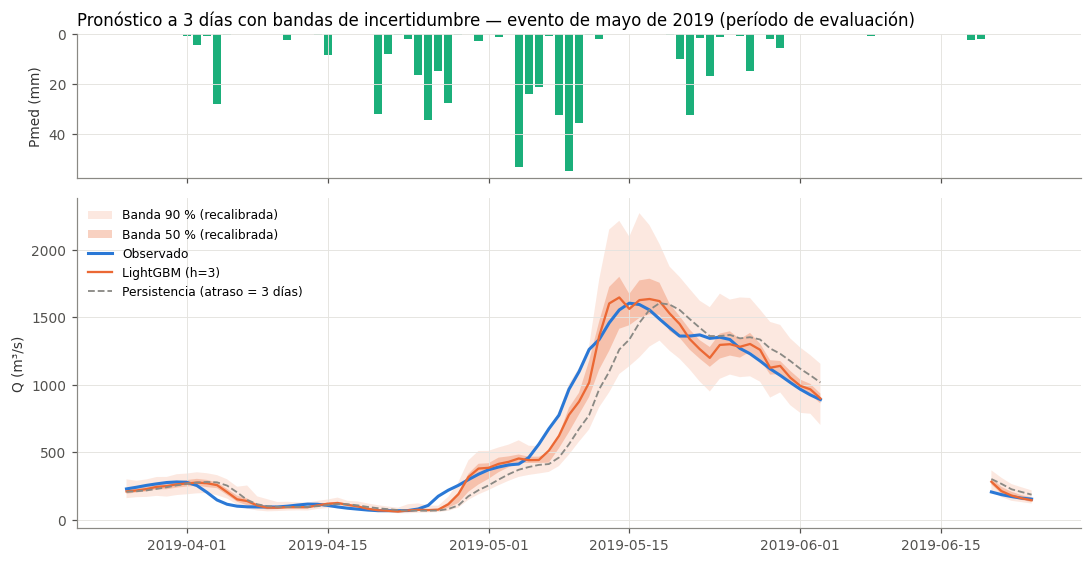

In [34]:
def bandas(idx_emision):
    q0_ = serie.Q[idx_emision].values; Xb = X.loc[idx_emision, ALL_COLS]
    out = pd.DataFrame({f'p{int(a*100)}': q0_ * np.exp(QM[a].predict(Xb)) for a in QM}, index=idx_emision + pd.Timedelta(days=H))
    out['p5c'] = q0_ * np.exp(QM[0.05].predict(Xb) - QHAT[90]); out['p95c'] = q0_ * np.exp(QM[0.95].predict(Xb) + QHAT[90])
    out['p25c'] = q0_ * np.exp(QM[0.25].predict(Xb) - QHAT[50]); out['p75c'] = q0_ * np.exp(QM[0.75].predict(Xb) + QHAT[50])
    return out.asfreq('D')
BD = bandas(ite[ite].index)
ev_eval = sp[sp.index.year >= 2016].obs.idxmax()
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
v2 = slice(ev_eval - pd.Timedelta(days=50), ev_eval + pd.Timedelta(days=40))
def capa_bandas(ax, v=v2):
    b = BD[v]
    ax.fill_between(b.index, b.p5c, b.p95c, color=C_MOD, alpha=0.15, lw=0, label='Banda 90 % (recalibrada)')
    ax.fill_between(b.index, b.p25c, b.p75c, color=C_MOD, alpha=0.30, lw=0, label='Banda 50 % (recalibrada)')
grafico_evento(v2, extra=capa_bandas, fn='bandas_evento_2019.png',
               titulo=f'Pronóstico a 3 días con bandas de incertidumbre — evento de {MESES[ev_eval.month - 1]} de {ev_eval.year} (período de evaluación)')

### 15.2 Monte Carlo sobre los datos de entrada

El método de Monte Carlo propaga la incertidumbre de las entradas: se generan 200 realizaciones en las que la lluvia de cada estación y cada día se multiplica por un error aleatorio (log-normal, σ = 0,35, representa error de medición y de representatividad espacial) y el caudal de entrada se multiplica por un error sistemático de ±5 % (incertidumbre de la curva altura–caudal). Cada realización recalcula la Pmed y las variables, y el modelo final genera un pronóstico. La dispersión de los 200 pronósticos mide cuánto de la incertidumbre total se explica por los datos de entrada.

{'cobertura_90': 0.48737650933040616, 'cobertura_90_altos': 0.6810344827586207, 'ancho_rel_medio': 0.17588694063968452}


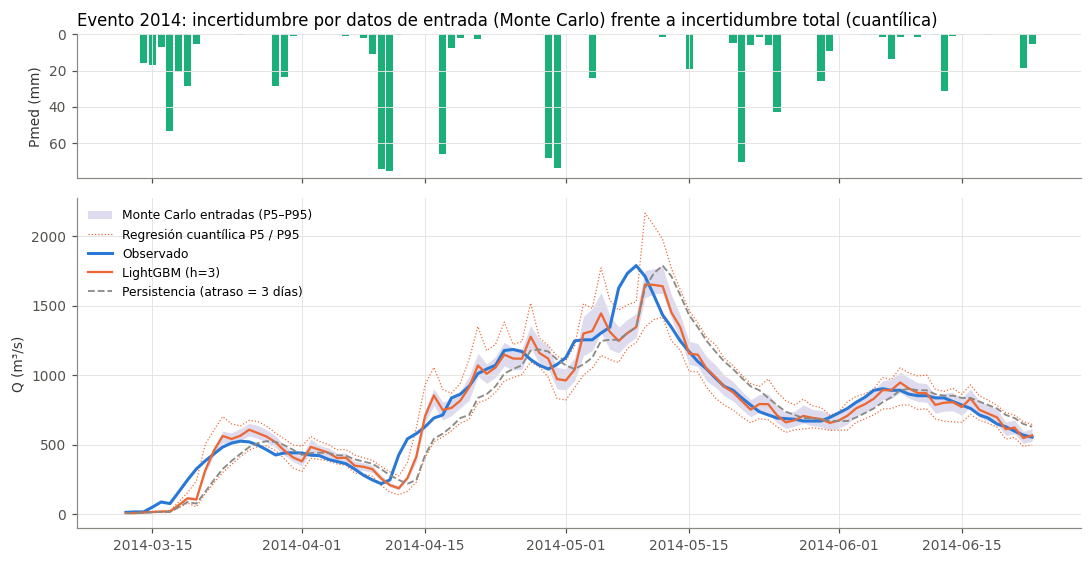

In [35]:
rng = np.random.default_rng(SEED)
idx_e = ite[ite].index
sims = []
for r in range(200):
    eps = np.exp(rng.normal(-0.5 * 0.35 ** 2, 0.35, P.shape))
    s2 = serie[['Pmed', 'Q']].copy()
    pm = (W * np.nan_to_num(P.values * eps)).sum(1); pm[W.sum(1) == 0] = np.nan
    s2['Pmed'] = pm; s2['Q'] = s2['Q'] * np.exp(rng.normal(0, 0.05))
    X2 = construir_features(s2)
    sims.append(s2.Q[idx_e].values * np.exp(finales[H].predict(X2.loc[idx_e, ALL_COLS])))
sims = np.array(sims)
MC = pd.DataFrame({'p5': np.percentile(sims, 5, 0), 'p50': np.percentile(sims, 50, 0), 'p95': np.percentile(sims, 95, 0)},
                  index=idx_e + pd.Timedelta(days=H)).asfreq('D')
qo_ = serie.Q.shift(-H)[idx_e].values
cov_mc = (qo_ >= np.percentile(sims, 5, 0)) & (qo_ <= np.percentile(sims, 95, 0))
R['montecarlo'] = {'cobertura_90': float(cov_mc.mean()), 'cobertura_90_altos': float(cov_mc[qo_ > Q90].mean()),
                   'ancho_rel_medio': float(np.mean((np.percentile(sims, 95, 0) - np.percentile(sims, 5, 0)) / qo_))}
print(R['montecarlo'])
def capa_mc(ax, v=ventana):
    b = MC[v]
    ax.fill_between(b.index, b.p5, b.p95, color='#4a3aa7', alpha=0.18, lw=0, label='Monte Carlo entradas (P5–P95)')
    bq = BD[v]
    ax.plot(bq.index, bq.p5, color=C_MOD, lw=0.8, ls=':', label='Regresión cuantílica P5 / P95')
    ax.plot(bq.index, bq.p95, color=C_MOD, lw=0.8, ls=':')
grafico_evento(ventana, extra=capa_mc, fn='montecarlo_evento_2014.png',
               titulo='Evento 2014: incertidumbre por datos de entrada (Monte Carlo) frente a incertidumbre total (cuantílica)')

La banda de Monte Carlo es mucho más angosta que la cuantílica y cubre solo una parte de las observaciones: la incertidumbre de los datos de entrada es real, pero la mayor parte del error proviene de lo que el modelo no puede saber (lluvia posterior, distribución espacial). Para comunicar rangos de pronóstico se recomienda la regresión cuantílica recalibrada; Monte Carlo sirve para cuantificar cuánto mejoraría el pronóstico si se mejoraran las mediciones.

## 16. Estación Yuty (aguas arriba): ¿mejora el pronóstico?

La estación hidrométrica Yuty está sobre el río Tebicuary, en el puente de la Ruta PY08 (cuenca alta), en UTM 21S 571 393 E – 7 044 889 N (SEAM/MADES, Informe cuenca del río Tebicuary, PMSAS 77/10, 2016). El mismo informe ubica Villa Florida en 486 947 E – 7 079 614 N, que coincide con el punto sin nombre de la planilla de estaciones (487 068 E – 7 079 652 N): ese punto es Villa Florida, no Yuty.

Registro disponible: abril de 2016 a agosto de 2023. Como no existe en 1974–2002, no puede entrar al modelo principal; se evalúa con los años recientes.

In [36]:
YUTY_UTM = (571393.0, 7044889.0)
Qy, _ = leer_serie(f'{RAW}/Caudales/Yuty.txt')
serie['Qy'] = Qy.asfreq('D').reindex(serie.index)
comun = serie[['Q', 'Qy']].dropna()
d_km = np.hypot(YUTY_UTM[0] - vf.x[0], YUTY_UTM[1] - vf.y[0]) / 1e3
R['yuty'] = {'inicio': str(serie.Qy.first_valid_index().date()), 'fin': str(serie.Qy.last_valid_index().date()),
             'dias': int(serie.Qy.notna().sum()), 'dias_comunes': len(comun), 'ceros': int((serie.Qy == 0).sum()),
             'Qy_medio': float(comun.Qy.mean()), 'Qvf_medio_comun': float(comun.Q.mean()), 'Qy_max': float(serie.Qy.max()),
             'fraccion_media': float(comun.Qy.mean() / comun.Q.mean()), 'distancia_recta_km': float(d_km),
             'area_estimada_km2': float(comun.Qy.mean() / comun.Q.mean() * A_KM2)}
print(R['yuty'])
print('Días con caudal 0 en Yuty:', serie.Qy[serie.Qy == 0].index.strftime('%Y-%m-%d').tolist())

{'inicio': '2016-04-28', 'fin': '2023-08-22', 'dias': 2654, 'dias_comunes': 2433, 'ceros': 15, 'Qy_medio': 55.355386531853675, 'Qvf_medio_comun': 236.35431416687217, 'Qy_max': 470.2042, 'fraccion_media': 0.23420510316038218, 'distancia_recta_km': 91.66108612828896, 'area_estimada_km2': 4915.206735832018}
Días con caudal 0 en Yuty: ['2021-12-29', '2021-12-30', '2021-12-31', '2022-01-02', '2022-01-04', '2022-01-20', '2022-01-21', '2022-01-22', '2022-01-23', '2022-01-24', '2022-01-29', '2022-01-30', '2022-02-19', '2022-02-20', '2022-02-21']


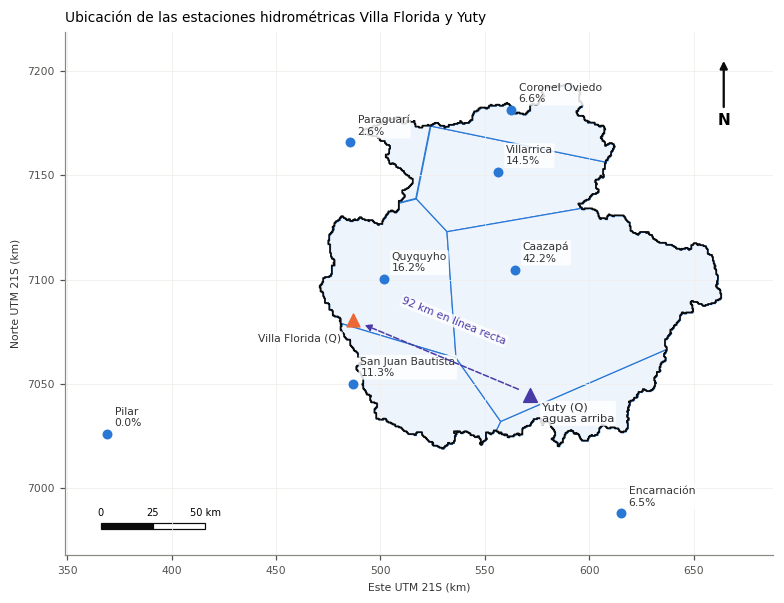

In [37]:
fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_mapa(ax, cells_full, w_full, [True]*len(EST), 'Ubicación de las estaciones hidrométricas Villa Florida y Yuty')
ax.scatter(*YUTY_UTM, s=80, marker='^', color='#4a3aa7', zorder=5)
ax.annotate('Yuty (Q)\naguas arriba', YUTY_UTM, xytext=(8, -18), textcoords='offset points', fontsize=7.5, color='#333',
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
ax.annotate('', xy=(vf.x[0] + 4e3, vf.y[0] - 2e3), xytext=(YUTY_UTM[0] - 4e3, YUTY_UTM[1] + 2e3),
            arrowprops=dict(arrowstyle='-|>', color='#4a3aa7', lw=1, ls='--'))
ax.text((vf.x[0] + YUTY_UTM[0]) / 2 + 6e3, (vf.y[0] + YUTY_UTM[1]) / 2 + 6e3, f'{d_km:.0f} km en línea recta', fontsize=7, color='#4a3aa7', ha='center', rotation=-22,
        bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.8))
plt.tight_layout(); plt.savefig(f'{FIG}/mapa_yuty.png', dpi=170); plt.show()

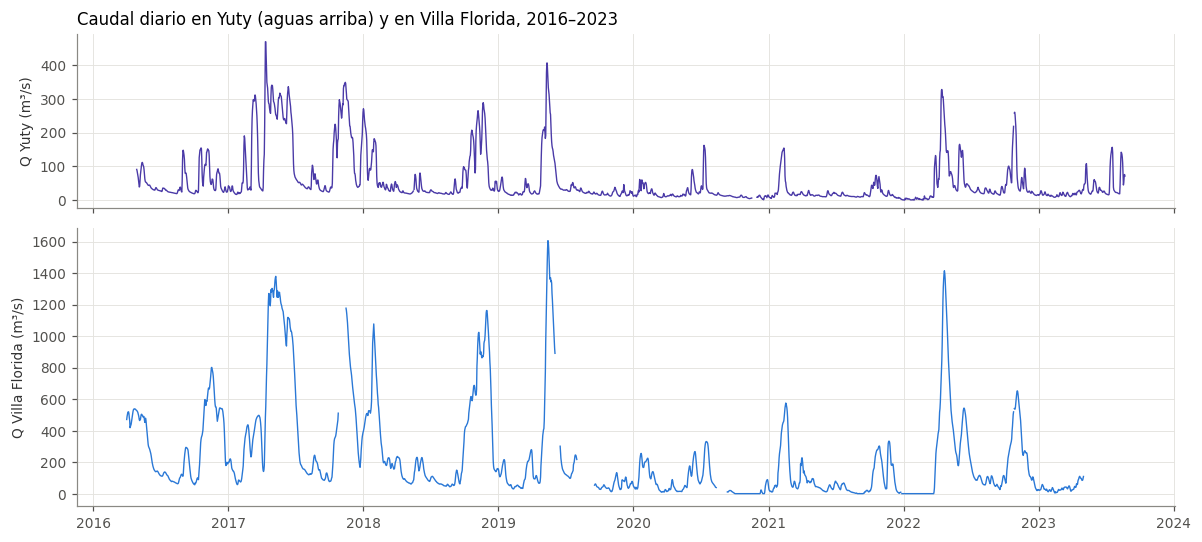

In [38]:
v = serie.loc['2016-04-01':'2023-08-31']
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={'height_ratios': [1, 1.6]})
axs[0].plot(v.index, v.Qy, color='#4a3aa7', lw=0.9); axs[0].set_ylabel('Q Yuty (m³/s)')
axs[0].set_title('Caudal diario en Yuty (aguas arriba) y en Villa Florida, 2016–2023', loc='left')
axs[1].plot(v.index, v.Q, color=C_OBS, lw=0.9); axs[1].set_ylabel('Q Villa Florida (m³/s)')
plt.tight_layout(); plt.savefig(f'{FIG}/yuty_series.png', dpi=150); plt.show()

### Tiempo de tránsito Yuty → Villa Florida

Dos medidas complementarias: la correlación entre las variaciones diarias de caudal (Δlog Q) de ambas estaciones con distintos retardos, y el desfase entre picos en los eventos de crecida.

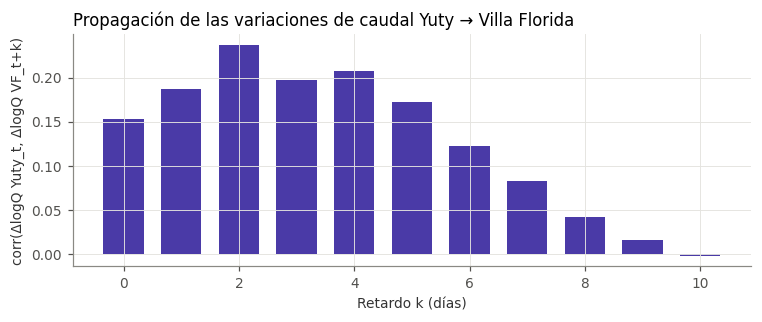

0     0.153
1     0.187
2     0.237
3     0.198
4     0.207
5     0.172
6     0.123
7     0.083
8     0.043
9     0.016
10   -0.002
dtype: float64


In [39]:
dly = np.log(comun.Qy.clip(lower=0.5)).reindex(serie.index).diff()
dlv = np.log(serie.Q).diff()
cc_y = pd.Series({k: dly.corr(dlv.shift(-k)) for k in range(0, 11)})
R['yuty']['corr_retardo'] = cc_y.round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(cc_y.index, cc_y.values, color='#4a3aa7', width=0.7)
ax.set_xlabel('Retardo k (días)'); ax.set_ylabel('corr(ΔlogQ Yuty_t, ΔlogQ VF_t+k)')
ax.set_title('Propagación de las variaciones de caudal Yuty → Villa Florida', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/yuty_correlacion.png', dpi=150); plt.show()
print(cc_y.round(3))

In [40]:
from scipy.signal import find_peaks
vv = serie.Q['2016-04-28':'2023-08-22']; yy = serie.Qy['2016-04-28':'2023-08-22']
pk, _ = find_peaks(vv.interpolate(limit=3).fillna(0).values, height=500, distance=20)
fil = []
for i in pk:
    t = vv.index[i]; w = yy[t - pd.Timedelta(days=15):t + pd.Timedelta(days=3)]
    if w.notna().sum() < 10: continue
    ty = w.idxmax()
    sub_v = vv[t] - vv[t - pd.Timedelta(days=20):t].min(); sub_y = w.max() - yy[t - pd.Timedelta(days=20):t].min()
    fil.append(dict(pico_VF=t.date(), Q_VF=vv[t], pico_Yuty=ty.date(), Q_Yuty=w.max(), desfase_dias=(t - ty).days,
                    subida_VF=sub_v, subida_Yuty=sub_y))
ev_y = pd.DataFrame(fil)
ev_y['fraccion_subida'] = np.where(ev_y.subida_VF > 300, ev_y.subida_Yuty / ev_y.subida_VF, np.nan)
R['yuty']['eventos'] = ev_y.assign(pico_VF=ev_y.pico_VF.astype(str), pico_Yuty=ev_y.pico_Yuty.astype(str)).round(3).to_dict(orient='records')
ev_y.round(2)

,pico_VF,Q_VF,pico_Yuty,Q_Yuty,desfase_dias,subida_VF,subida_Yuty,fraccion_subida
0,2016-05-11,504.57,2016-05-13,111.62,-2,40.02,73.21,NaN
1,2016-11-17,801.62,2016-11-06,151.75,11,242.02,105.88,NaN
2,2016-12-09,544.86,2016-12-04,92.52,5,85.00,64.65,NaN
3,2017-05-09,1379.12,2017-04-28,340.91,11,186.96,88.04,NaN
4,2017-06-11,1118.99,2017-06-12,336.66,-1,181.85,110.05,NaN
5,2017-11-15,1177.15,2017-11-13,349.55,2,0.00,106.42,NaN
6,2018-01-29,1077.26,2018-01-30,181.96,-1,581.12,123.69,0.21
7,2018-10-19,616.95,2018-10-21,207.35,-2,325.33,172.27,0.53
8,2018-11-09,1024.03,2018-11-07,265.24,2,433.84,185.24,0.43
9,2018-11-30,1162.33,2018-11-21,289.08,9,299.27,153.27,NaN


### Modelos con Yuty: evaluación con origen móvil (2019–2023)

Con solo siete años de registro no se puede reservar un bloque grande de test. Se usa evaluación con origen móvil: para cada año de 2019 a 2023 se entrena con todos los años anteriores desde 2016 y se pronostica ese año. Así se obtienen cinco años de pronósticos siempre "a ciegas".

Variantes comparadas:
- E0 Modelo base: el modelo principal (entrenado 1974–2002, sin Yuty), sin cambios.
- E1 Reciente sin Yuty: mismo tipo de modelo entrenado solo con los años recientes.
- E2 Reciente con Yuty: igual que E1, agregando las variables de Yuty.
- E3a Corrección local sin Yuty: un segundo modelo pequeño corrige el error del modelo base usando solo variables de Villa Florida.
- E3b Corrección con Yuty: el segundo modelo corrige el error del modelo base usando además las variables de Yuty.

La diferencia E3b − E3a aísla el aporte de Yuty. Variables de Yuty: log Q en t, t−1, t−2, t−3 y t−5; variaciones a 1, 2 y 3 días; relación Yuty/Villa Florida; subida reciente de Yuty relativa al caudal de Villa Florida; caudal de la cuenca intermedia (Villa Florida menos Yuty desfasado 2 días).

In [41]:
qy, qv = serie.Qy, serie.Q
XY = pd.DataFrame(index=serie.index)
ly = np.log(qy.clip(lower=0.5))
for l in [0, 1, 2, 3, 5]: XY[f'lY_{l}'] = ly.shift(l)
XY['dlY_1'] = ly - ly.shift(1); XY['dlY_2'] = ly - ly.shift(2); XY['dlY_3'] = ly - ly.shift(3)
XY['ratio_YV'] = ly - np.log(qv)
XY['dY1_rel'] = (qy - qy.shift(1)) / qv; XY['dY2_rel'] = (qy - qy.shift(2)) / qv
XY['frac_Y'] = qy.shift(2) / qv; XY['lLat'] = np.log((qv - qy.shift(2)).clip(lower=1))
YCOLS = list(XY.columns)
CORR_BASE = ['base', 'lQ_0', 'dlQ_1', 'dlQ_3', 'P3', 'P7']
PEQ = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=20, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=SEED)
VARIANTES = {'E1 Reciente sin Yuty': (ALL_COLS, 'y'), 'E2 Reciente con Yuty': (ALL_COLS[:-1] + YCOLS + ['mes'], 'y'),
             'E3a Corrección local sin Yuty': (CORR_BASE + ['mes'], 'res'), 'E3b Corrección con Yuty': (CORR_BASE + YCOLS + ['mes'], 'res')}
modelos_base = dict(finales)
y5, itr5, _ = datos_h(5)
modelos_base[5] = entrenar(5, mk(), ALL_COLS)

def origen_movil(h, anios=range(2019, 2024)):
    y_h = np.log(serie.Q.shift(-h)) - np.log(serie.Q)
    ok = y_h.notna() & X['lQ_0'].notna() & XY['lY_0'].notna() & XY['lY_5'].notna()
    base_h = pd.Series(modelos_base[h].predict(X[ALL_COLS]), index=X.index)
    XA = X.join(XY).assign(base=base_h)
    bloques = []
    for A in anios:
        tr_ = ok & (serie.index.year >= 2016) & (serie.index.year < A); te_ = ok & (serie.index.year == A)
        w = np.where(serie.Q.shift(-h)[tr_] > Q90, 3.0, 1.0)
        pr = {'E0 Modelo base': base_h[te_].values}
        for nom, (cols, tipo) in VARIANTES.items():
            tgt = y_h if tipo == 'y' else y_h - base_h
            p = crear_pipeline(LGBMRegressor(**PEQ), cols).fit(XA.loc[tr_, cols], tgt[tr_], modelo__sample_weight=w)
            pr[nom] = p.predict(XA.loc[te_, cols]) + (0 if tipo == 'y' else base_h[te_].values)
        d = pd.DataFrame(pr, index=serie.index[te_]); d['y'] = y_h[te_].values; d['q0'] = serie.Q[te_].values
        bloques.append(d)
    return pd.concat(bloques)

def metricas_mov(D, h):
    qo = (D.q0 * np.exp(D.y)).values; q0 = D.q0.values; alto = qo > Q90; sube = qo / q0 > 1.10
    out = {}
    for c in [c for c in D.columns if c.startswith('E')]:
        qs = q0 * np.exp(D[c].values)
        s = pd.Series(qs, index=D.index + pd.Timedelta(days=h)).asfreq('D'); o = pd.Series(qo, index=s.dropna().index).asfreq('D')
        out[c] = dict(NSE=nse(qo, qs), KGE=kge(qo, qs), Skill_pers=1 - np.mean((qo - qs) ** 2) / np.mean((qo - q0) ** 2),
                      RMSE=np.sqrt(np.mean((qo - qs) ** 2)), RMSE_alto=np.sqrt(np.mean((qo[alto] - qs[alto]) ** 2)),
                      RMSE_subida=np.sqrt(np.mean((qo[sube] - qs[sube]) ** 2)), atraso_dias=int(curva_desfase(o, s).idxmax()),
                      n=len(qo), n_alto=int(alto.sum()))
    return pd.DataFrame(out).T

MOV, MET_MOV = {}, {}
for h in [1, 2, 3, 5]:
    MOV[h] = origen_movil(h); MET_MOV[h] = metricas_mov(MOV[h], h)
R['yuty']['metricas'] = {str(h): MET_MOV[h].round(4).to_dict(orient='index') for h in MET_MOV}
pd.concat({f'h={h}': MET_MOV[h][['NSE', 'KGE', 'Skill_pers', 'RMSE_alto', 'RMSE_subida', 'atraso_dias']] for h in MET_MOV}).round(3)

NSE    KGE  Skill_pers  RMSE_alto  RMSE_subida  atraso_dias
h=1 E0 Modelo base                 0.998  0.994       0.761     30.117       17.020          0.0
    E1 Reciente sin Yuty           0.998  0.997       0.771     33.221       15.610          0.0
    E2 Reciente con Yuty           0.998  0.998       0.775     31.146       16.431          0.0
    E3a Corrección local sin Yuty  0.998  0.997       0.768     31.349       16.180          0.0
    E3b Corrección con Yuty        0.998  0.998       0.775     29.469       17.087          0.0
h=2 E0 Modelo base                 0.992  0.990       0.717     66.169       31.012          1.0
    E1 Reciente sin Yuty           0.993  0.995       0.744     63.159       27.853          1.0
    E2 Reciente con Yuty           0.993  0.994       0.746     63.527       29.744          1.0
    E3a Corrección local sin Yuty  0.992  0.990       0.709     72.410       30.411          1.0
    E3b Corrección con Yuty        0.993  0.989       0.740     64.069       31.047          1.0
h=3 E0 Modelo base                 0.982  0.983       0.689    102.265       43.772          1.0
    E1 Reciente sin Yuty           0.982  0.990       0.686    108.396       41.788          1.0
    E2 Reciente con Yuty           0.983  0.983       0.710    107.412       44.768          1.0
    E3a Corrección local sin Yuty  0.982  0.981       0.683    113.808       41.421          1.0
    E3b Corrección con Yuty        0.985  0.978       0.731     99.458       43.362          1.0
h=5 E0 Modelo base                 0.949  0.967       0.643    175.751       71.255          2.0
    E1 Reciente sin Yuty           0.942  0.960       0.595    207.066       74.128          3.0
    E2 Reciente con Yuty           0.946  0.961       0.618    214.677       77.723          2.0
    E3a Corrección local sin Yuty  0.951  0.957       0.656    188.210       69.330          2.0
    E3b Corrección con Yuty        0.959  0.960       0.709    169.986       69.271          2.0

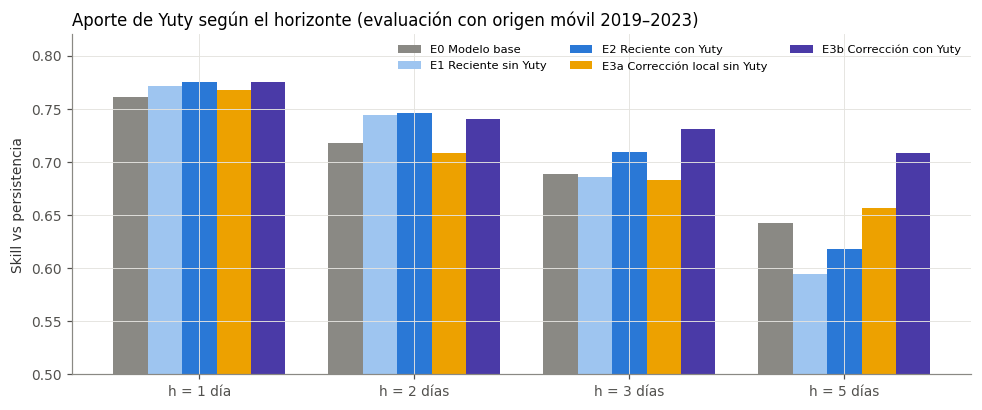

Aporte de Yuty (E3b − E3a) en skill: {1: 0.007, 2: 0.031, 3: 0.048, 5: 0.052}
Mejora sobre el modelo base (E3b − E0): {1: 0.014, 2: 0.022, 3: 0.042, 5: 0.066}


In [42]:
sk = pd.DataFrame({h: MET_MOV[h]['Skill_pers'] for h in MET_MOV}).T
fig, ax = plt.subplots(figsize=(9, 3.8))
ancho = 0.16; cols_e = ['#8a8984', '#9ec5f0', C_OBS, '#eda100', '#4a3aa7']
for i, (c, col) in enumerate(zip(sk.columns, cols_e)):
    ax.bar(np.arange(len(sk)) + (i - 2) * ancho, sk[c], width=ancho, color=col, label=c)
ax.set_xticks(range(len(sk))); ax.set_xticklabels([f'h = {h} días' if h > 1 else 'h = 1 día' for h in sk.index])
ax.set_ylim(0.5, 0.82); ax.set_ylabel('Skill vs persistencia'); ax.legend(fontsize=7.5, ncol=3, loc='upper right')
ax.set_title('Aporte de Yuty según el horizonte (evaluación con origen móvil 2019–2023)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/yuty_skill.png', dpi=150); plt.show()
print('Aporte de Yuty (E3b − E3a) en skill:', (sk['E3b Corrección con Yuty'] - sk['E3a Corrección local sin Yuty']).round(3).to_dict())
print('Mejora sobre el modelo base (E3b − E0):', (sk['E3b Corrección con Yuty'] - sk['E0 Modelo base']).round(3).to_dict())

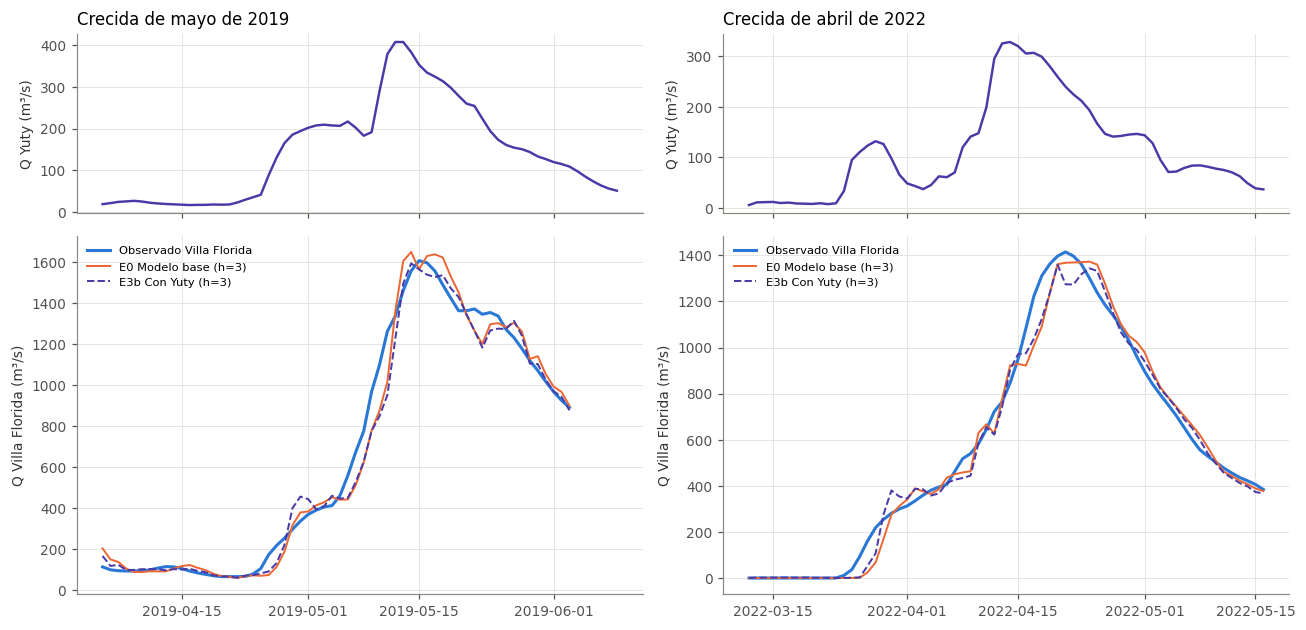

In [43]:
Hy = 3
Dm = MOV[Hy].copy(); Dm.index = Dm.index + pd.Timedelta(days=Hy); Dm = Dm.asfreq('D')
fig, axs = plt.subplots(2, 2, figsize=(12, 5.8), sharex='col', gridspec_kw={'height_ratios': [1, 2]})
for j, (t_c, tit) in enumerate([('2019-05-15', 'Crecida de mayo de 2019'), ('2022-04-21', 'Crecida de abril de 2022')]):
    tc = pd.Timestamp(t_c); vt = slice(tc - pd.Timedelta(days=40), tc + pd.Timedelta(days=25))
    axs[0, j].plot(serie.Qy[vt].index, serie.Qy[vt], color='#4a3aa7', lw=1.6); axs[0, j].set_ylabel('Q Yuty (m³/s)')
    axs[0, j].set_title(tit, loc='left')
    d = Dm[vt]; qo_ = d.q0 * np.exp(d.y)
    axs[1, j].plot(d.index, qo_, color=C_OBS, lw=2, label='Observado Villa Florida')
    axs[1, j].plot(d.index, d.q0 * np.exp(d['E0 Modelo base']), color=C_MOD, lw=1.3, label='E0 Modelo base (h=3)')
    axs[1, j].plot(d.index, d.q0 * np.exp(d['E3b Corrección con Yuty']), color='#4a3aa7', lw=1.3, ls='--', label='E3b Con Yuty (h=3)')
    axs[1, j].set_ylabel('Q Villa Florida (m³/s)'); axs[1, j].legend(fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/yuty_eventos.png', dpi=150); plt.show()

### Modelo de corrección con Yuty para operación

Se entrena la variante E3b con todo el período 2016–2023 para h = 1, 2 y 3 días. En la app, si el CSV incluye la columna `Qy` (caudal de Yuty), el pronóstico base se corrige con este modelo.

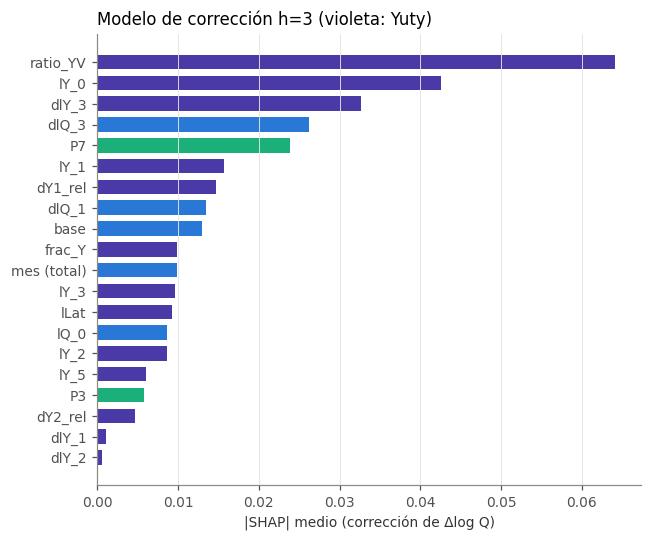

In [44]:
corr_yuty = {}
for h in [1, 2, 3]:
    y_h = np.log(serie.Q.shift(-h)) - np.log(serie.Q)
    ok = y_h.notna() & X['lQ_0'].notna() & XY['lY_0'].notna() & XY['lY_5'].notna()
    base_h = pd.Series(modelos_base[h].predict(X[ALL_COLS]), index=X.index)
    XA = X.join(XY).assign(base=base_h)
    cols = CORR_BASE + YCOLS + ['mes']
    w = np.where(serie.Q.shift(-h)[ok] > Q90, 3.0, 1.0)
    corr_yuty[h] = crear_pipeline(LGBMRegressor(**PEQ), cols).fit(XA.loc[ok, cols], (y_h - base_h)[ok], modelo__sample_weight=w)
COLS_CORR = CORR_BASE + YCOLS + ['mes']
# Importancia SHAP del modelo de corrección (h = 3)
XA3 = X.join(XY).assign(base=pd.Series(modelos_base[3].predict(X[ALL_COLS]), index=X.index))
ok3 = XA3['lY_5'].notna() & XA3['lQ_0'].notna()
Xt3 = corr_yuty[3].named_steps['prep'].transform(XA3.loc[ok3, COLS_CORR])
nom3 = [n.split('__')[1] for n in corr_yuty[3].named_steps['prep'].get_feature_names_out()]
sv3 = shap.TreeExplainer(corr_yuty[3].named_steps['modelo']).shap_values(Xt3)
imp3 = pd.Series(np.abs(sv3).mean(0), index=nom3)
imp3 = pd.concat([imp3[[c for c in nom3 if not c.startswith('mes_')]], pd.Series({'mes (total)': imp3[[c for c in nom3 if c.startswith('mes_')]].sum()})]).sort_values()
R['yuty']['shap_correccion'] = imp3.sort_values(ascending=False).round(5).to_dict()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(imp3.index, imp3.values, color=['#4a3aa7' if c in YCOLS else (C_P if c.startswith('P') else C_OBS) for c in imp3.index], height=0.7)
ax.set_xlabel('|SHAP| medio (corrección de Δlog Q)'); ax.grid(axis='y', visible=False)
ax.set_title('Modelo de corrección h=3 (violeta: Yuty)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/yuty_shap.png', dpi=150); plt.show()

## 17. Lluvia satelital CHIRPS

CHIRPS v2.0 (Climate Hazards Group, UCSB) combina estimaciones satelitales infrarrojas con estaciones, con resolución 0,05° (~5,5 km) y datos diarios desde 1981. Se descargó desde Google Earth Engine (colección `UCSB-CHG/CHIRPS/DAILY`) una grilla de 45 × 38 celdas que cubre la cuenca con margen (57,45°–55,20° O; 27,10°–25,20° S), 1981–2023. Las subcuencas se definieron con HydroBASINS nivel 8 (HydroSHEDS, también desde Earth Engine).

Preguntas: ¿qué tan bien reproduce CHIRPS la lluvia de las estaciones a escala diaria, mensual y anual? ¿Mejora el pronóstico si se agrega al modelo, ya sea como lluvia media de la cuenca o por subcuencas?

In [45]:
from shapely.geometry import box
RAWC = f'{RAW}/chirps'
arrs, fch = [], []
for fn in sorted(glob.glob(f'{RAWC}/chirps_*.npz')):
    z = np.load(fn); arrs.append(z['prcp']); fch += list(z['fechas'])
PCH = np.concatenate(arrs); idx_ch = pd.to_datetime(fch, format='%Y%m%d')
LON0, LAT0, RES = float(z['lon0']), float(z['lat0']), float(z['res'])
NY, NX = PCH.shape[1:]
celdas = gpd.GeoSeries([box(LON0 + j*RES, LAT0 - (i+1)*RES, LON0 + (j+1)*RES, LAT0 - i*RES) for i in range(NY) for j in range(NX)], crs=4326).to_crs(32721)
print(f'CHIRPS: {PCH.shape[0]} días ({idx_ch.min().date()} a {idx_ch.max().date()}), grilla {NY} × {NX}, faltantes: {int(np.isnan(PCH).sum())}')

# Subcuencas (HydroBASINS nivel 8): se agrupan por la red de drenaje (NEXT_DOWN)
hb = gpd.read_file(f'{RAWC}/hybas_8.geojson').to_crs(32721)
hb = hb[hb.geometry.intersection(geom).area / hb.geometry.area > 0.2]
nd = dict(zip(hb.HYBAS_ID, hb.NEXT_DOWN))
def aguas_arriba(raiz):
    s = {raiz}
    while True:
        nuevos = {h for h, d in nd.items() if d in s and h not in s}
        if not nuevos: return s
        s |= nuevos
ZONAS_ID = {'Tebicuary-mí': aguas_arriba(6080804520), 'Tebicuary alto (Yuty)': aguas_arriba(6080806530), 'Pirapó': aguas_arriba(6080806540)}
ZONAS_ID['Cuenca baja e intermedia'] = set(hb.HYBAS_ID) - set().union(*ZONAS_ID.values())
zonas = gpd.GeoSeries({k: hb[hb.HYBAS_ID.isin(v)].geometry.union_all().intersection(geom) for k, v in ZONAS_ID.items()}, crs=32721)
area_z = (zonas.area / 1e6).round(0)
print('Áreas de subcuenca (km²):', area_z.to_dict())

W_ch = {}
for k, zg in {'Cuenca': geom, **zonas.to_dict()}.items():
    a = celdas.intersection(zg).area.values; W_ch[k] = a / a.sum()
W_ch = pd.DataFrame(W_ch)
CH = pd.DataFrame(PCH.reshape(len(PCH), -1) @ W_ch.values, index=idx_ch, columns=W_ch.columns).reindex(serie.index)
R['chirps'] = {'dias': int(len(idx_ch)), 'areas_zonas_km2': area_z.to_dict()}

CHIRPS: 15705 días (1981-01-01 a 2023-12-31), grilla 38 × 45, faltantes: 0
Áreas de subcuenca (km²): {'Tebicuary-mí': 7189.0, 'Tebicuary alto (Yuty)': 5588.0, 'Pirapó': 4158.0, 'Cuenca baja e intermedia': 4026.0}


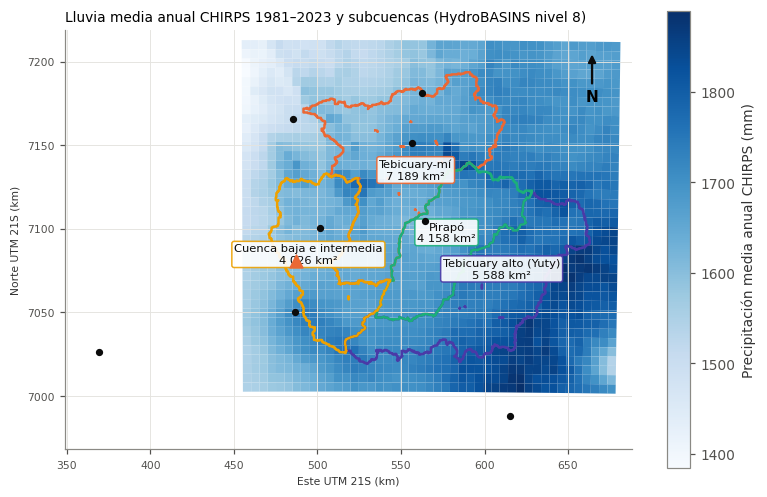

In [46]:
media_anual = pd.Series(np.nanmean(PCH, axis=0).ravel() * 365.25)
fig, ax = plt.subplots(figsize=(7.2, 7.2))
celdas_plot = gpd.GeoDataFrame({'P': media_anual}, geometry=celdas)
celdas_plot.plot(column='P', ax=ax, cmap='Blues', legend=True, legend_kwds={'label': 'Precipitación media anual CHIRPS (mm)', 'shrink': 0.6})
cols_z = ['#eb6834', '#4a3aa7', '#1baf7a', '#eda100']
for (k, zg), c in zip(zonas.items(), cols_z):
    gpd.GeoSeries([zg], crs=32721).boundary.plot(ax=ax, color=c, lw=1.6)
    ax.annotate(f'{k}\n{area_z[k]:,.0f} km²'.replace(',', ' '), (zg.representative_point().x, zg.representative_point().y), fontsize=7.5, ha='center',
                color='#0b0b0b', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=c, alpha=0.9))
est_gs.plot(ax=ax, color='#0b0b0b', markersize=14, zorder=4)
ax.scatter(vf.x[0], vf.y[0], s=70, marker='^', color=C_MOD, zorder=5)
ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}')); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}'))
ax.set_xlabel('Este UTM 21S (km)', fontsize=7); ax.set_ylabel('Norte UTM 21S (km)', fontsize=7); ax.tick_params(labelsize=7)
ax.annotate('N', xy=(XMAX - 0.07*(XMAX-XMIN), YMAX - 0.05*(YMAX-YMIN)), xytext=(XMAX - 0.07*(XMAX-XMIN), YMAX - 0.17*(YMAX-YMIN)),
            ha='center', fontsize=10, fontweight='bold', arrowprops=dict(arrowstyle='-|>', color='#0b0b0b', lw=1.5))
ax.set_title('Lluvia media anual CHIRPS 1981–2023 y subcuencas (HydroBASINS nivel 8)', loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_mapa.png', dpi=170); plt.show()

### Alineación temporal

Antes de comparar hay que verificar que "el día t" signifique lo mismo en ambas fuentes. En la DMH la lluvia se lee a la mañana y se asigna al día anterior; CHIRPS usa otra convención. Se calcula la correlación entre la Pmed de estaciones del día t y la de CHIRPS del día t + L.

corr(Pmed estaciones_t, CHIRPS_t+L): {-2: 0.012, -1: 0.065, 0: 0.493, 1: 0.589, 2: 0.022} → desplazamiento adoptado 1


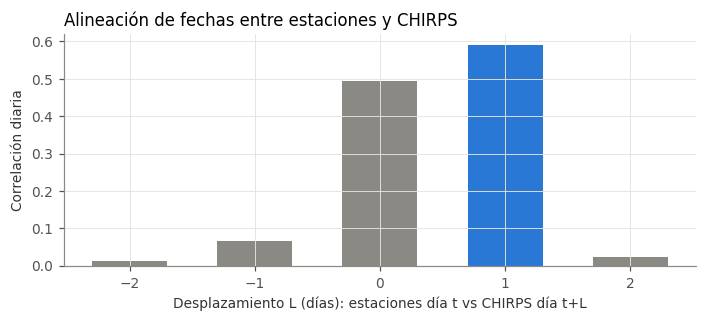

In [47]:
m_ok = CH['Cuenca'].notna() & serie.Pmed.notna()
alin = pd.Series({L: serie.Pmed[m_ok].corr(CH['Cuenca'].shift(-L)[m_ok]) for L in range(-2, 3)})
L_AL = int(alin.idxmax())
R['chirps']['alineacion'] = alin.round(4).to_dict(); R['chirps']['desplazamiento'] = L_AL
print('corr(Pmed estaciones_t, CHIRPS_t+L):', alin.round(3).to_dict(), '→ desplazamiento adoptado', L_AL)
CHa = CH.shift(-L_AL)   # CHIRPS expresado en la convención de día de las estaciones
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(alin.index, alin.values, color=['#8a8984' if L != L_AL else C_OBS for L in alin.index], width=0.6)
ax.set_xlabel('Desplazamiento L (días): estaciones día t vs CHIRPS día t+L'); ax.set_ylabel('Correlación diaria')
ax.set_title('Alineación de fechas entre estaciones y CHIRPS', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_alineacion.png', dpi=150); plt.show()

### Validación de CHIRPS frente a las estaciones

Para cada estación dentro de la grilla se compara su registro con la celda CHIRPS que la contiene (ya alineada). Métricas: correlación diaria, mensual y anual; sesgo (suma CHIRPS / suma estación); y detección de días de lluvia (≥ 1 mm): POD (proporción de días lluviosos detectados), FAR (proporción de días lluviosos de CHIRPS que en la estación fueron secos) y CSI (índice de acierto combinado).

In [48]:
val = []
for n, (la, lo) in EST.items():
    i, j = int((LAT0 - la) // RES), int((lo - LON0) // RES)
    if not (0 <= i < NY and 0 <= j < NX): continue
    cs = pd.Series(PCH[:, i, j], index=idx_ch).reindex(serie.index).shift(-L_AL); ps = P[n]
    m = cs.notna() & ps.notna()
    o, s = ps[m], cs[m]
    wo, ws = o >= 1, s >= 1
    mo = o.resample('MS').sum(min_count=25); ms = s.resample('MS').sum(min_count=25)
    ao = o.resample('YE').sum(min_count=330); as_ = s.resample('YE').sum(min_count=330)
    val.append(dict(estacion=NOMBRE[n], r_diaria=o.corr(s), r_mensual=mo.corr(ms), r_anual=ao.corr(as_), sesgo=s.sum() / o.sum(),
                    POD=(wo & ws).sum() / wo.sum(), FAR=(~wo & ws).sum() / ws.sum(), CSI=(wo & ws).sum() / (wo | ws).sum(),
                    P99_estacion=o[o > 0].quantile(0.99), P99_chirps=s[s > 0].quantile(0.99)))
val = pd.DataFrame(val)
cm_ = CHa['Cuenca'].resample('MS').sum(min_count=25); pm_ = serie.Pmed.resample('MS').sum(min_count=25)
ca_ = CHa['Cuenca'].resample('YE').sum(min_count=330); pa_ = serie.Pmed.resample('YE').sum(min_count=330)
R['chirps']['validacion'] = val.round(4).to_dict(orient='records')
R['chirps']['cuenca'] = {'r_diaria': float(serie.Pmed[m_ok].corr(CHa['Cuenca'][m_ok])), 'r_mensual': float(cm_.corr(pm_)),
                         'r_anual': float(ca_.corr(pa_)), 'anual_chirps': float(ca_.mean()), 'anual_thiessen': float(pa_[ca_.notna()].mean())}
print(R['chirps']['cuenca'])
val.round(3)

{'r_diaria': 0.5892636566152996, 'r_mensual': 0.933195837529014, 'r_anual': 0.9238482770626681, 'anual_chirps': 1682.3337012730474, 'anual_thiessen': 1698.4487208888465}


,estacion,r_diaria,r_mensual,r_anual,sesgo,POD,FAR,CSI,P99_estacion,P99_chirps
0,Paraguarí,0.417,0.841,0.816,1.014,0.454,0.567,0.285,100.430,71.169
1,Villarrica,0.513,0.858,0.847,1.026,0.492,0.484,0.337,99.652,72.812
2,Coronel Oviedo,0.510,0.831,0.736,0.922,0.502,0.478,0.344,102.440,73.121
3,Quyquyho,0.417,0.817,0.827,0.979,0.458,0.512,0.309,99.760,71.924
4,San Juan Bautista,0.469,0.852,0.861,1.017,0.463,0.478,0.325,98.750,77.695
5,Caazapá,0.478,0.861,0.853,1.084,0.484,0.474,0.337,84.035,74.582


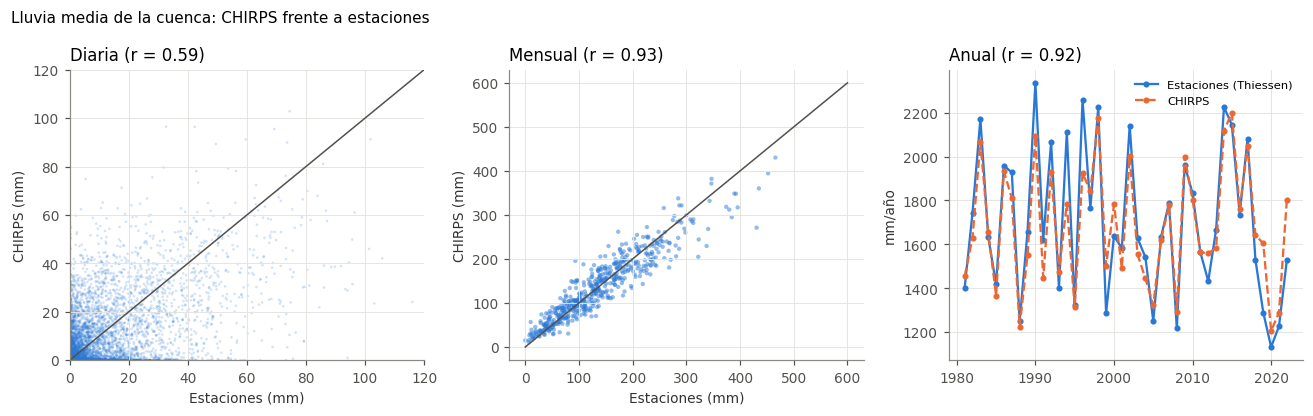

In [49]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
d_ = pd.DataFrame({'o': serie.Pmed, 's': CHa['Cuenca']}).dropna()
axs[0].scatter(d_.o, d_.s, s=3, alpha=0.2, color=C_OBS, edgecolors='none'); axs[0].plot([0, 120], [0, 120], color='#52514e', lw=1)
axs[0].set_xlim(0, 120); axs[0].set_ylim(0, 120); axs[0].set_title(f'Diaria (r = {R["chirps"]["cuenca"]["r_diaria"]:.2f})', loc='left')
d_ = pd.DataFrame({'o': pm_, 's': cm_}).dropna()
axs[1].scatter(d_.o, d_.s, s=8, alpha=0.5, color=C_OBS, edgecolors='none'); axs[1].plot([0, 600], [0, 600], color='#52514e', lw=1)
axs[1].set_title(f'Mensual (r = {R["chirps"]["cuenca"]["r_mensual"]:.2f})', loc='left')
d_ = pd.DataFrame({'o': pa_, 's': ca_}).dropna()
axs[2].plot(d_.index.year, d_.o, color=C_OBS, marker='o', ms=3, label='Estaciones (Thiessen)'); axs[2].plot(d_.index.year, d_.s, color=C_MOD, marker='o', ms=3, ls='--', label='CHIRPS')
axs[2].set_title(f'Anual (r = {R["chirps"]["cuenca"]["r_anual"]:.2f})', loc='left'); axs[2].legend(fontsize=7.5)
for a in axs[:2]: a.set_xlabel('Estaciones (mm)'); a.set_ylabel('CHIRPS (mm)')
axs[2].set_ylabel('mm/año')
plt.suptitle('Lluvia media de la cuenca: CHIRPS frente a estaciones', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_validacion.png', dpi=150); plt.show()

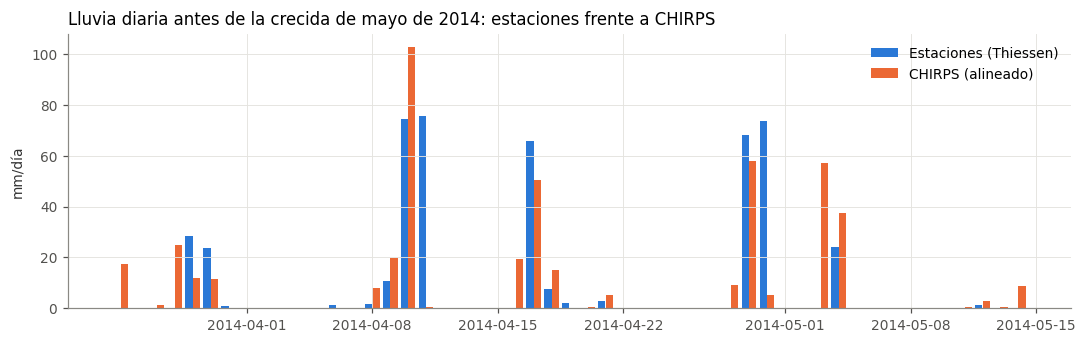

In [50]:
t_ev = pd.Timestamp('2014-05-09'); v_ev = slice(t_ev - pd.Timedelta(days=45), t_ev + pd.Timedelta(days=5))
fig, ax = plt.subplots(figsize=(10, 3.2))
xx_ = serie.Pmed[v_ev].index
ax.bar(xx_ - pd.Timedelta(hours=5), serie.Pmed[v_ev], width=0.4, color=C_OBS, label='Estaciones (Thiessen)')
ax.bar(xx_ + pd.Timedelta(hours=5), CHa['Cuenca'][v_ev], width=0.4, color=C_MOD, label='CHIRPS (alineado)')
ax.set_ylabel('mm/día'); ax.legend(); ax.set_title('Lluvia diaria antes de la crecida de mayo de 2014: estaciones frente a CHIRPS', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_hietograma_2014.png', dpi=150); plt.show()

### Corrección de sesgo y variables CHIRPS

Factores mensuales de escala = suma de la Pmed de estaciones / suma de CHIRPS en la cuenca, por mes calendario, calculados solo con 1981–2002. Se aplican a la cuenca y a cada subcuenca. Variables: acumulados de 1 a 30 días y API de la lluvia media CHIRPS (C1…C30, CAPI) y acumulados de 3, 7, 10 y 15 días por subcuenca.

In [51]:
TR81 = (serie.index.year >= 1981) & (serie.index.year <= 2002)
mm_ = CHa['Cuenca'].notna() & serie.Pmed.notna() & TR81
FAC = serie.Pmed[mm_].groupby(serie.index[mm_].month).sum() / CHa['Cuenca'][mm_].groupby(serie.index[mm_].month).sum()
R['chirps']['factores_mensuales'] = FAC.round(4).to_dict()
print('Factores de corrección mensual:', FAC.round(3).to_dict())
CHc = CHa.mul(pd.Series(serie.index.month, index=serie.index).map(FAC), axis=0)
FC = pd.DataFrame(index=serie.index)
for k in [1, 3, 5, 7, 10, 15, 30]: FC[f'C{k}'] = CHc['Cuenca'].rolling(k, min_periods=k).sum()
pch_ = CHc['Cuenca'].fillna(0).values; apic = np.zeros(len(pch_))
for i in range(1, len(pch_)): apic[i] = API_K * apic[i - 1] + pch_[i]
FC['CAPI'] = np.where(CHc['Cuenca'].notna(), apic, np.nan)
ABR = {'Tebicuary-mí': 'Ztm', 'Tebicuary alto (Yuty)': 'Zta', 'Pirapó': 'Zpi', 'Cuenca baja e intermedia': 'Zcb'}
for nom, ab in ABR.items():
    for k in [3, 7, 10, 15]: FC[f'{ab}{k}'] = CHc[nom].rolling(k, min_periods=k).sum()
XC = X.join(FC)
C_CUENCA = [f'C{k}' for k in [1, 3, 5, 7, 10, 15, 30]] + ['CAPI']
C_ZONAS = [c for c in FC.columns if c.startswith('Z')]
anual_z = CHc[list(ABR)].resample('YE').sum(min_count=330).mean()
R['chirps']['anual_zonas'] = anual_z.round(1).to_dict()
print('Lluvia media anual corregida por subcuenca (mm):', anual_z.round(0).to_dict())

Factores de corrección mensual: {1: 0.985, 2: 1.07, 3: 0.948, 4: 1.02, 5: 1.062, 6: 0.976, 7: 1.219, 8: 1.097, 9: 1.062, 10: 1.023, 11: 1.074, 12: 1.062}
Lluvia media anual corregida por subcuenca (mm): {'Tebicuary-mí': 1721.0, 'Tebicuary alto (Yuty)': 1815.0, 'Pirapó': 1747.0, 'Cuenca baja e intermedia': 1711.0}


### Experimentos con CHIRPS

Todas las variantes se entrenan con 1981–2002 (período común con CHIRPS) y se evalúan en el mismo test 2013–2023. Para distinguir mejoras reales del azar del algoritmo, cada variante se entrena con 3 semillas distintas y se reporta la media y el desvío.

- A. Estaciones (referencia, mismo período 1981–2002).
- B. Solo CHIRPS (reemplaza a las estaciones).
- C. Estaciones + CHIRPS de la cuenca.
- D. Estaciones + CHIRPS por subcuenca.
- E. Estaciones + CHIRPS de la cuenca y por subcuenca.

In [52]:
VAR_C = {'A. Estaciones': QCOLS + PCOLS + ['mes'], 'B. Solo CHIRPS': QCOLS + C_CUENCA + ['mes'],
         'C. Estaciones + CHIRPS cuenca': QCOLS + PCOLS + C_CUENCA + ['mes'],
         'D. Estaciones + CHIRPS subcuencas': QCOLS + PCOLS + C_ZONAS + ['mes'],
         'E. Estaciones + CHIRPS cuenca y subcuencas': QCOLS + PCOLS + C_CUENCA + C_ZONAS + ['mes']}
def exp_chirps(h, semilla, variantes=VAR_C, XX=XC):
    y_h = np.log(serie.Q.shift(-h)) - np.log(serie.Q)
    ok = y_h.notna() & X['lQ_0'].notna()
    itr_ = ok & TR81 & XX['C30'].notna(); ite_ = ok & TEST
    qo_, q0_ = serie.Q.shift(-h)[ite_].values, serie.Q[ite_].values
    alto, sube = qo_ > Q90, qo_ / q0_ > 1.10
    out, preds = {}, {}
    for nom, cols in variantes.items():
        p = crear_pipeline(LGBMRegressor(verbose=-1, random_state=semilla, subsample_freq=1, **MEJORES), cols)
        p.fit(XX.loc[itr_, cols], y_h[itr_], modelo__sample_weight=np.where(serie.Q.shift(-h)[itr_] > Q90, 3.0, 1.0))
        qs = q0_ * np.exp(p.predict(XX.loc[ite_, cols])); preds[nom] = qs
        s = pd.Series(qs, index=serie.index[ite_] + pd.Timedelta(days=h)).asfreq('D'); o = pd.Series(qo_, index=s.dropna().index).asfreq('D')
        out[nom] = dict(NSE=nse(qo_, qs), KGE=kge(qo_, qs), Skill_pers=1 - np.mean((qo_ - qs) ** 2) / np.mean((qo_ - q0_) ** 2),
                        RMSE_alto=np.sqrt(np.mean((qo_[alto] - qs[alto]) ** 2)), RMSE_subida=np.sqrt(np.mean((qo_[sube] - qs[sube]) ** 2)),
                        atraso_dias=int(curva_desfase(o, s).idxmax()))
    return pd.DataFrame(out).T, pd.DataFrame(preds, index=serie.index[ite_]).assign(obs=qo_, q0=q0_)

filas, PRED_C = [], {}
for h in [1, 2, 3, 5]:
    for sem in [1, 2, 3]:
        d, pr = exp_chirps(h, sem)
        filas.append(d.assign(h=h, semilla=sem).reset_index().rename(columns={'index': 'variante'}))
        if sem == 1: PRED_C[h] = pr
EXPC = pd.concat(filas)
RES_C = EXPC.groupby(['h', 'variante'])[['NSE', 'KGE', 'Skill_pers', 'RMSE_alto', 'RMSE_subida', 'atraso_dias']].mean()
SD_C = EXPC.groupby(['h', 'variante'])[['Skill_pers', 'RMSE_alto']].std()
R['chirps']['experimentos'] = {str(h): RES_C.loc[h].round(4).to_dict(orient='index') for h in [1, 2, 3, 5]}
R['chirps']['experimentos_sd'] = {str(h): SD_C.loc[h].round(4).to_dict(orient='index') for h in [1, 2, 3, 5]}
RES_C.round(3)

NSE    KGE  Skill_pers  RMSE_alto  RMSE_subida  atraso_dias
h variante                                                                                                 
1 A. Estaciones                               0.996  0.997       0.454     54.202       46.052          1.0
  B. Solo CHIRPS                              0.996  0.996       0.453     53.996       45.274          1.0
  C. Estaciones + CHIRPS cuenca               0.996  0.997       0.454     54.457       45.510          1.0
  D. Estaciones + CHIRPS subcuencas           0.996  0.997       0.453     54.494       46.054          1.0
  E. Estaciones + CHIRPS cuenca y subcuencas  0.996  0.997       0.451     54.780       45.935          1.0
2 A. Estaciones                               0.987  0.992       0.520     84.886       57.766          1.0
  B. Solo CHIRPS                              0.987  0.991       0.511     84.621       56.909          1.0
  C. Estaciones + CHIRPS cuenca               0.988  0.992       0.521     85.346       57.074          1.0
  D. Estaciones + CHIRPS subcuencas           0.987  0.992       0.520     84.704       57.174          1.0
  E. Estaciones + CHIRPS cuenca y subcuencas  0.987  0.992       0.519     85.467       57.466          1.0
3 A. Estaciones                               0.976  0.984       0.545    117.543       72.709          1.0
  B. Solo CHIRPS                              0.975  0.984       0.528    119.580       73.111          1.0
  C. Estaciones + CHIRPS cuenca               0.976  0.985       0.548    117.669       71.879          1.0
  D. Estaciones + CHIRPS subcuencas           0.976  0.985       0.540    118.538       72.611          1.0
  E. Estaciones + CHIRPS cuenca y subcuencas  0.976  0.984       0.541    119.710       72.963          1.0
5 A. Estaciones                               0.945  0.963       0.551    172.313      104.115          3.0
  B. Solo CHIRPS                              0.943  0.965       0.536    174.939      102.297          2.0
  C. Estaciones + CHIRPS cuenca               0.946  0.966       0.556    173.241      102.119          2.0
  D. Estaciones + CHIRPS subcuencas           0.946  0.966       0.555    171.483      102.190          2.0
  E. Estaciones + CHIRPS cuenca y subcuencas  0.946  0.965       0.555    173.015      102.589          2.0

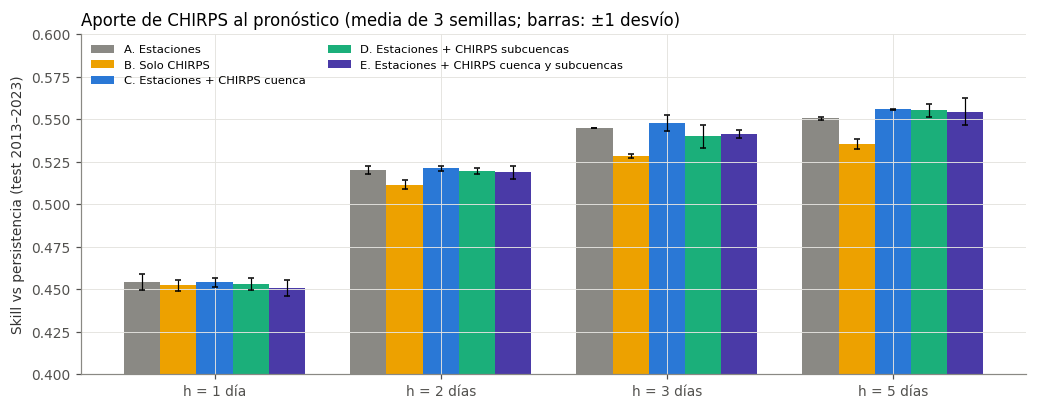

Ganancia de C sobre A: {1: 0.0, 2: 0.001, 3: 0.003, 5: 0.005}


In [53]:
sk_c = RES_C['Skill_pers'].unstack(); sd_c = SD_C['Skill_pers'].unstack()
fig, ax = plt.subplots(figsize=(9.5, 3.8))
cols_v = ['#8a8984', '#eda100', C_OBS, '#1baf7a', '#4a3aa7']; w_ = 0.16
for i, (c, col) in enumerate(zip(sk_c.columns, cols_v)):
    ax.bar(np.arange(len(sk_c)) + (i - 2) * w_, sk_c[c], yerr=sd_c[c], width=w_, color=col, label=c, capsize=2, error_kw={'lw': 0.8})
ax.set_xticks(range(len(sk_c))); ax.set_xticklabels([f'h = {h} día{"s" if h > 1 else ""}' for h in sk_c.index])
ax.set_ylim(0.4, 0.6); ax.set_ylabel('Skill vs persistencia (test 2013–2023)'); ax.legend(fontsize=7.5, ncol=2, loc='upper left')
ax.set_title('Aporte de CHIRPS al pronóstico (media de 3 semillas; barras: ±1 desvío)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_skill.png', dpi=150); plt.show()
print('Ganancia de C sobre A:', (sk_c['C. Estaciones + CHIRPS cuenca'] - sk_c['A. Estaciones']).round(3).to_dict())

In [54]:
# Efecto de alinear las fechas: variante C sin alinear
FC0 = FC.copy()
CH0 = CH.mul(pd.Series(serie.index.month, index=serie.index).map(FAC), axis=0)
for k in [1, 3, 5, 7, 10, 15, 30]: FC0[f'C{k}'] = CH0['Cuenca'].rolling(k, min_periods=k).sum()
XC0 = X.join(FC0)
sin_al = {h: exp_chirps(h, 1, {k: VAR_C[k] for k in ['A. Estaciones', 'C. Estaciones + CHIRPS cuenca']}, XC0)[0]['Skill_pers'].to_dict() for h in [1, 3, 5]}
R['chirps']['sin_alinear'] = sin_al
print('Skill con CHIRPS sin alinear:', {h: {k[:2]: round(v, 3) for k, v in d.items()} for h, d in sin_al.items()})

Skill con CHIRPS sin alinear: {1: {'A.': 0.45, 'C.': 0.46}, 3: {'A.': 0.545, 'C.': 0.54}, 5: {'A.': 0.55, 'C.': 0.547}}


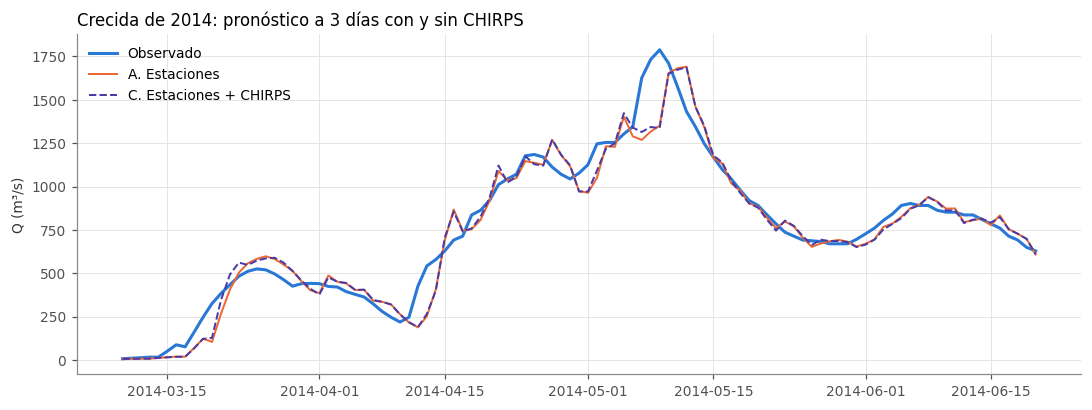

In [55]:
# Crecida de mayo de 2014 con y sin CHIRPS (h = 3)
pr = PRED_C[3].copy(); pr.index = pr.index + pd.Timedelta(days=3); pr = pr.asfreq('D')
v14 = slice(pd.Timestamp('2014-03-10'), pd.Timestamp('2014-06-20'))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(pr[v14].index, pr.obs[v14], color=C_OBS, lw=2, label='Observado')
ax.plot(pr[v14].index, pr['A. Estaciones'][v14], color=C_MOD, lw=1.3, label='A. Estaciones')
ax.plot(pr[v14].index, pr['C. Estaciones + CHIRPS cuenca'][v14], color='#4a3aa7', lw=1.3, ls='--', label='C. Estaciones + CHIRPS')
ax.set_ylabel('Q (m³/s)'); ax.legend(loc='upper left'); ax.set_title('Crecida de 2014: pronóstico a 3 días con y sin CHIRPS', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_evento_2014.png', dpi=150); plt.show()

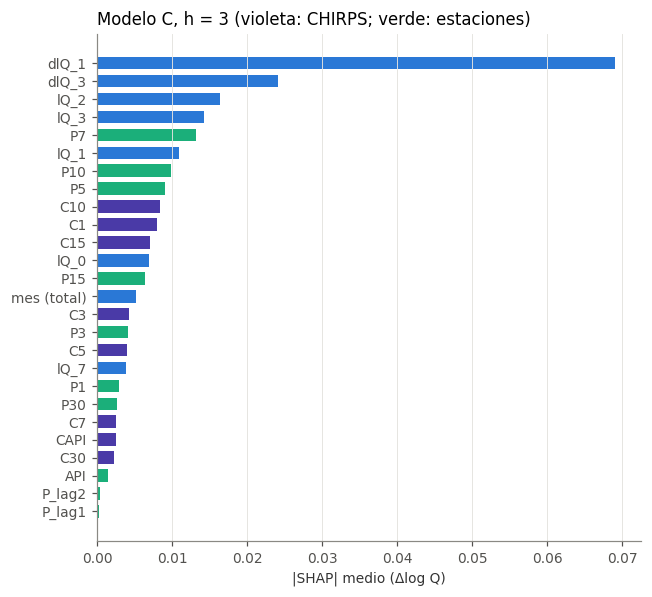

Importancia total CHIRPS vs estaciones: 0.0387 0.0499


In [56]:
# SHAP del modelo C (h = 3): ¿qué usa de CHIRPS?
cols_c = VAR_C['C. Estaciones + CHIRPS cuenca']
y3 = np.log(serie.Q.shift(-3)) - np.log(serie.Q); ok3 = y3.notna() & X['lQ_0'].notna()
itr3 = ok3 & TR81 & XC['C30'].notna(); ite3 = ok3 & TEST
pc3 = crear_pipeline(LGBMRegressor(verbose=-1, random_state=1, subsample_freq=1, **MEJORES), cols_c)
pc3.fit(XC.loc[itr3, cols_c], y3[itr3], modelo__sample_weight=np.where(serie.Q.shift(-3)[itr3] > Q90, 3.0, 1.0))
Xt_c = pc3.named_steps['prep'].transform(XC.loc[ite3, cols_c]); nom_c = [n.split('__')[1] for n in pc3.named_steps['prep'].get_feature_names_out()]
imp_c = pd.Series(np.abs(shap.TreeExplainer(pc3.named_steps['modelo']).shap_values(Xt_c)).mean(0), index=nom_c)
imp_c = pd.concat([imp_c[[c for c in nom_c if not c.startswith('mes_')]], pd.Series({'mes (total)': imp_c[[c for c in nom_c if c.startswith('mes_')]].sum()})]).sort_values()
R['chirps']['shap_C'] = imp_c.sort_values(ascending=False).round(5).to_dict()
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.barh(imp_c.index, imp_c.values, color=['#4a3aa7' if c.startswith('C') else (C_P if c.startswith(('P', 'API')) else C_OBS) for c in imp_c.index], height=0.7)
ax.set_xlabel('|SHAP| medio (Δlog Q)'); ax.grid(axis='y', visible=False)
ax.set_title('Modelo C, h = 3 (violeta: CHIRPS; verde: estaciones)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/chirps_shap.png', dpi=150); plt.show()
print('Importancia total CHIRPS vs estaciones:', round(imp_c[[c for c in imp_c.index if c.startswith('C')]].sum(), 4), round(imp_c[[c for c in imp_c.index if c.startswith(('P', 'API'))]].sum(), 4))
R['chirps']['shap_total'] = {'chirps': float(imp_c[[c for c in imp_c.index if c.startswith('C')]].sum()), 'estaciones': float(imp_c[[c for c in imp_c.index if c.startswith(('P', 'API'))]].sum())}

Síntesis CHIRPS: a escala diaria CHIRPS reproduce mal la lluvia puntual (correlación ~0,5 y la mitad de los días de lluvia no detectados o falsos), pero a escala mensual y anual coincide muy bien con las estaciones. Por eso, como variable adicional (acumulados de varios días), aporta una mejora pequeña pero consistente a 2–5 días; no reemplaza a las estaciones con ventaja y no reduce el día de atraso. La división por subcuencas no mejora respecto a la media de la cuenca.

## 18. Pronósticos meteorológicos históricos (GFS)

El modelo principal solo usa lluvia observada hasta el día de emisión; no puede anticipar crecidas causadas por lluvia que todavía no cayó. Aquí se incorporan los pronósticos de lluvia que el modelo global GFS (NOAA, 0,25°) emitió en su momento, descargados desde Google Earth Engine (colección `NOAA/GFS0P25`): corrida de las 00 UTC de cada día, acumulados de 6 horas hasta 84 horas, agosto de 2016 a septiembre de 2023 (antes de agosto de 2016 el archivo solo llega a 36 horas).

Pasos: (1) lluvia media de la cuenca pronosticada para cada día; (2) alineación con el día pluviométrico de las estaciones; (3) validación del pronóstico contra la lluvia observada; (4) uso en el modelo y comparación con el techo teórico (lluvia futura observada).

In [57]:
RAWG = f'{RAW}/gfs'
GFSD = {}
for fn in sorted(glob.glob(f'{RAWG}/gfs_*.npz')):
    z = np.load(fn)
    for n, a in zip(z['nombres'], z['prcp']): GFSD[str(n)] = a
G_LON0, G_LAT0, G_RES = float(z['lon0']), float(z['lat0']), float(z['res'])
G_NY, G_NX = z['prcp'].shape[1:]
celdas_g = gpd.GeoSeries([box(G_LON0 + j*G_RES, G_LAT0 - (i+1)*G_RES, G_LON0 + (j+1)*G_RES, G_LAT0 - i*G_RES) for i in range(G_NY) for j in range(G_NX)], crs=4326).to_crs(32721)
a_g = celdas_g.intersection(geom).area.values; w_g = a_g / a_g.sum()
corridas = sorted({pd.Timestamp(n[:8]) for n in GFSD})
HRS = list(range(6, 85, 6))
cubo = np.full((len(corridas), len(HRS)), np.nan)
for i, f in enumerate(corridas):
    for j, hh in enumerate(HRS):
        k = f'{f:%Y%m%d}00F{hh:03d}'
        if k in GFSD: cubo[i, j] = (GFSD[k].ravel() * w_g).sum()
C6 = pd.DataFrame(cubo, index=pd.DatetimeIndex(corridas), columns=HRS)   # lluvia media de cuenca por bloque de 6 h
def ventana(h0, h1):
    hs = [hh for hh in HRS if h0 < hh <= h1]
    return C6[hs].sum(1, min_count=len(hs))
VG = pd.DataFrame({'0-12 h': ventana(0, 12), '12-36 h': ventana(12, 36), '36-60 h': ventana(36, 60), '60-84 h': ventana(60, 84)}).reindex(serie.index)
print(f'GFS: {len(corridas)} corridas ({corridas[0].date()} a {corridas[-1].date()}), {int((w_g > 0).sum())} celdas sobre la cuenca')
alin_g = pd.DataFrame({c: {L: serie.Pmed.corr(VG[c].shift(L)) for L in range(-2, 3)} for c in ['12-36 h', '36-60 h', '60-84 h']})
R['gfs'] = {'corridas': len(corridas), 'inicio': str(corridas[0].date()), 'fin': str(corridas[-1].date()), 'alineacion': alin_g.round(4).to_dict()}
alin_g.round(3)

GFS: 2616 corridas (2016-08-01 a 2023-09-30), 48 celdas sobre la cuenca


,12-36 h,36-60 h,60-84 h
-2,0.024,0.020,0.052
-1,0.214,0.043,0.020
0,0.695,0.230,0.035
1,0.158,0.661,0.225
2,-0.022,0.178,0.567


La ventana 12–36 h de la corrida del día D coincide con la lluvia de estaciones del día D (correlación máxima con desplazamiento 0): el día pluviométrico de la estación va de las 12 UTC del día D a las 12 UTC del día siguiente, coherente con la lectura matinal. Por lo tanto, al emitir el pronóstico hidrológico (mañana del día t+1, con la lectura del día t) se dispone de la corrida de 00 UTC del día t+1, cuyas ventanas 12–36, 36–60 y 60–84 h pronostican la lluvia de los días t+1, t+2 y t+3.

In [58]:
GF = pd.DataFrame({'G1': VG['12-36 h'].shift(-1), 'G2': VG['36-60 h'].shift(-1), 'G3': VG['60-84 h'].shift(-1)}, index=serie.index)
OBSF = pd.DataFrame({'G1': serie.Pmed.shift(-1), 'G2': serie.Pmed.shift(-2), 'G3': serie.Pmed.shift(-3)})
CALG = (serie.index >= '2016-08-01') & (serie.index <= '2018-12-31'); EVG = serie.index >= '2019-01-01'
FAC_G = pd.Series({c: OBSF[c][CALG & GF[c].notna()].sum() / GF[c][CALG & OBSF[c].notna()].sum() for c in GF})
GFc = GF.mul(FAC_G, axis=1)
filas = []
for c, lead in [('G1', 1), ('G2', 2), ('G3', 3)]:
    m = GFc[c].notna() & OBSF[c].notna() & EVG
    o, s = OBSF[c][m], GFc[c][m]
    for umbral in [1, 10]:
        wo, ws = o >= umbral, s >= umbral
        filas.append(dict(anticipacion_dias=lead, umbral_mm=umbral, r_diaria=o.corr(s), sesgo=s.sum() / o.sum(),
                          POD=(wo & ws).sum() / wo.sum(), FAR=(~wo & ws).sum() / max(ws.sum(), 1), CSI=(wo & ws).sum() / (wo | ws).sum()))
VALG = pd.DataFrame(filas)
m3 = GFc.notna().all(1) & OBSF.notna().all(1) & EVG
R['gfs'].update({'factores_sesgo': FAC_G.round(4).to_dict(), 'validacion': VALG.round(4).to_dict(orient='records'),
                 'r_acumulado_3d': float(OBSF[m3].sum(1).corr(GFc[m3].sum(1))), 'r_referencia': float(serie.Pmed[EVG].corr(serie.Pmed.shift(-1)[EVG]))})
print('Factores de corrección de sesgo (calibrados 2016-08 a 2018):', FAC_G.round(3).to_dict())
VALG.round(3)

Factores de corrección de sesgo (calibrados 2016-08 a 2018): {'G1': 1.176, 'G2': 1.097, 'G3': 1.131}


,anticipacion_dias,umbral_mm,r_diaria,sesgo,POD,FAR,CSI
0,1,1,0.695,0.996,0.816,0.283,0.617
1,1,10,0.695,0.996,0.581,0.343,0.446
2,2,1,0.682,1.047,0.780,0.310,0.578
3,2,10,0.682,1.047,0.589,0.370,0.438
4,3,1,0.596,1.077,0.790,0.334,0.566
5,3,10,0.596,1.077,0.594,0.394,0.429


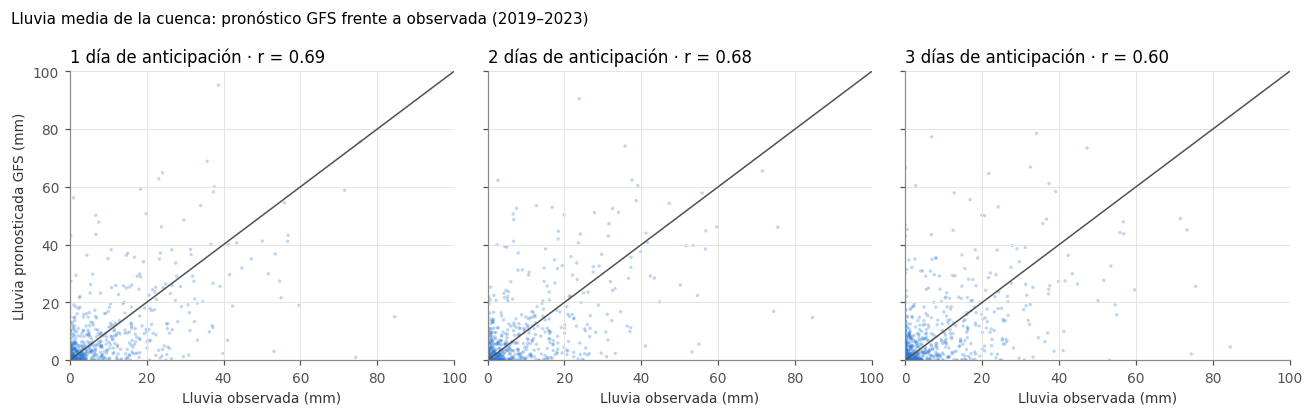

In [59]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for ax, (c, lead) in zip(axs, [('G1', 1), ('G2', 2), ('G3', 3)]):
    m = GFc[c].notna() & OBSF[c].notna() & EVG
    ax.scatter(OBSF[c][m], GFc[c][m], s=5, alpha=0.3, color=C_OBS, edgecolors='none'); ax.plot([0, 100], [0, 100], color='#52514e', lw=1)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_xlabel('Lluvia observada (mm)')
    ax.set_title(f'{lead} día{"s" if lead > 1 else ""} de anticipación · r = {OBSF[c][m].corr(GFc[c][m]):.2f}', loc='left')
axs[0].set_ylabel('Lluvia pronosticada GFS (mm)')
plt.suptitle('Lluvia media de la cuenca: pronóstico GFS frente a observada (2019–2023)', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.savefig(f'{FIG}/gfs_validacion.png', dpi=150); plt.show()

### Uso en el modelo

GFS solo existe desde 2016, por lo que no puede entrenarse el modelo con él en 1974–2002. Se comparan, siempre en 2019–2023:

- A. Modelo base (solo lluvia observada hasta t).
- B. Techo teórico: modelo entrenado en 1974–2002 con la lluvia observada de los días t+1 a t+h, evaluado también con lluvia observada (como si el pronóstico fuera perfecto).
- C. El modelo B alimentado con el pronóstico GFS corregido de sesgo (operable).
- C2. Igual que C, pero entrenado con la lluvia futura "degradada" con un error aleatorio (log-normal, σ = 1), para que aprenda a confiar solo en parte en el pronóstico. Media de 3 semillas.
- D0 / D. Corrección en dos etapas (como con Yuty), entrenada desde 2016 con origen móvil, sin y con GFS.

In [60]:
def fut(F, h):
    D = pd.DataFrame(index=serie.index)
    for k in range(1, h + 1): D[f'Pf{k}'] = F[f'G{k}']
    D['Pfut'] = F[[f'G{k}' for k in range(1, h + 1)]].sum(1, min_count=h)
    return D
def met_g(qo, q0, qs, idx, h):
    alto, sube = qo > Q90, qo / q0 > 1.10
    s = pd.Series(qs, index=idx + pd.Timedelta(days=h)).asfreq('D'); o = pd.Series(qo, index=s.dropna().index).asfreq('D')
    return dict(NSE=nse(qo, qs), Skill_pers=1 - np.mean((qo - qs) ** 2) / np.mean((qo - q0) ** 2), RMSE_alto=np.sqrt(np.mean((qo[alto] - qs[alto]) ** 2)),
                RMSE_subida=np.sqrt(np.mean((qo[sube] - qs[sube]) ** 2)), sesgo_subida_pct=100 * (qs[sube].sum() - qo[sube].sum()) / qo[sube].sum(),
                atraso_dias=int(curva_desfase(o, s).idxmax()))
PEQ_G = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=SEED)
RES_G, PRED_G, MOD_GFS, COLS_GFS = {}, {}, {}, {}
for h in [1, 2, 3]:
    y_h = np.log(serie.Q.shift(-h)) - np.log(serie.Q); ok = y_h.notna() & X['lQ_0'].notna()
    itr_ = ok & TRAIN; iev = ok & EVG & GFc[[f'G{k}' for k in range(1, h + 1)]].notna().all(1)
    qo_, q0_ = serie.Q.shift(-h)[iev].values, serie.Q[iev].values; idx_ = serie.index[iev]
    w_ = np.where(serie.Q.shift(-h)[itr_] > Q90, 3.0, 1.0)
    colsF = ALL_COLS[:-1] + list(fut(OBSF, h).columns) + ['mes']; COLS_GFS[h] = colsF
    out, pr_h = {}, {}
    qs = q0_ * np.exp(finales[h].predict(X.loc[iev])); out['A. Base'] = met_g(qo_, q0_, qs, idx_, h); pr_h['A'] = qs
    pB = crear_pipeline(mk(), colsF).fit(X.join(fut(OBSF, h)).loc[itr_, colsF], y_h[itr_], modelo__sample_weight=w_)
    qs = q0_ * np.exp(pB.predict(X.join(fut(OBSF, h)).loc[iev, colsF])); out['B. Techo (lluvia futura observada)'] = met_g(qo_, q0_, qs, idx_, h); pr_h['B'] = qs
    qs = q0_ * np.exp(pB.predict(X.join(fut(GFc, h)).loc[iev, colsF])); out['C. Modelo B con GFS'] = met_g(qo_, q0_, qs, idx_, h); pr_h['C'] = qs
    acc, preds = [], []
    for sem in [1, 2, 3]:
        rng_ = np.random.default_rng(sem); On = OBSF.copy()
        for c in On: On[c] = OBSF[c] * np.exp(rng_.normal(-0.5, 1.0, len(On)))
        pC2 = crear_pipeline(LGBMRegressor(verbose=-1, random_state=sem, subsample_freq=1, **MEJORES), colsF).fit(X.join(fut(On, h)).loc[itr_, colsF], y_h[itr_], modelo__sample_weight=w_)
        preds.append(q0_ * np.exp(pC2.predict(X.join(fut(GFc, h)).loc[iev, colsF])))
        acc.append(met_g(qo_, q0_, preds[-1], idx_, h))
        if sem == 1: MOD_GFS[h] = pC2
    out['C2. Entrenado con lluvia futura degradada, con GFS'] = pd.DataFrame(acc).mean().to_dict(); pr_h['C2'] = np.mean(preds, 0)
    base_h = pd.Series(finales[h].predict(X[ALL_COLS]), index=X.index)
    XA_ = X.join(fut(GFc, h)).assign(base=base_h); fc = list(fut(GFc, h).columns)
    for nom, cols_d in [('D0. Corrección sin GFS (control)', ['base', 'lQ_0', 'dlQ_1', 'dlQ_3', 'P3', 'P7', 'mes']),
                    ('D. Corrección en dos etapas con GFS', ['base', 'lQ_0', 'dlQ_1', 'dlQ_3', 'P3', 'P7'] + fc + ['mes'])]:
        prs = pd.Series(np.nan, index=serie.index)
        for A in range(2019, 2024):
            tr = ok & (serie.index >= '2016-08-01') & (serie.index.year < A) & XA_[fc].notna().all(1); te = iev & (serie.index.year == A)
            if te.sum() == 0: continue
            p = crear_pipeline(LGBMRegressor(**PEQ_G), cols_d).fit(XA_.loc[tr, cols_d], (y_h - base_h)[tr], modelo__sample_weight=np.where(serie.Q.shift(-h)[tr] > Q90, 3.0, 1.0))
            prs[te] = base_h[te] + p.predict(XA_.loc[te, cols_d])
        qs = q0_ * np.exp(prs[iev].values); out[nom] = met_g(qo_, q0_, qs, idx_, h); pr_h[nom[:2].strip('.')] = qs
    RES_G[h] = pd.DataFrame(out).T
    PRED_G[h] = pd.DataFrame(pr_h, index=idx_ + pd.Timedelta(days=h)).assign(obs=qo_, pers=q0_)
R['gfs']['experimentos'] = {str(h): RES_G[h].round(4).to_dict(orient='index') for h in RES_G}
pd.concat({f'h={h}': RES_G[h] for h in RES_G}).round(3)

NSE  Skill_pers  RMSE_alto  RMSE_subida  sesgo_subida_pct  atraso_dias
h=1 A. Base                                             0.998       0.761     30.448       17.020            -6.925          0.0
    B. Techo (lluvia futura observada)                  0.998       0.768     30.297       16.917            -6.817          0.0
    C. Modelo B con GFS                                 0.998       0.763     30.929       17.101            -6.762          0.0
    C2. Entrenado con lluvia futura degradada, con GFS  0.998       0.762     30.598       17.044            -6.727          0.0
    D0. Corrección sin GFS (control)                    0.998       0.770     31.222       16.488            -4.527          0.0
    D. Corrección en dos etapas con GFS                 0.998       0.767     31.192       16.464            -4.196          0.0
h=2 A. Base                                             0.992       0.718     66.768       31.047            -7.454          1.0
    B. Techo (lluvia futura observada)                  0.993       0.753     57.790       28.521            -7.320          1.0
    C. Modelo B con GFS                                 0.993       0.732     60.961       29.816            -7.470          1.0
    C2. Entrenado con lluvia futura degradada, con GFS  0.993       0.731     62.388       29.728            -6.964          1.0
    D0. Corrección sin GFS (control)                    0.992       0.713     69.573       30.832            -4.550          1.0
    D. Corrección en dos etapas con GFS                 0.992       0.710     71.296       31.595            -4.286          0.0
h=3 A. Base                                             0.982       0.689    103.335       43.770            -9.675          1.0
    B. Techo (lluvia futura observada)                  0.984       0.726     91.010       40.659            -9.450          1.0
    C. Modelo B con GFS                                 0.982       0.690     97.463       43.236            -9.624          1.0
    C2. Entrenado con lluvia futura degradada, con GFS  0.983       0.708     94.920       41.588            -8.760          1.0
    D0. Corrección sin GFS (control)                    0.982       0.691    109.414       42.202            -7.115          1.0
    D. Corrección en dos etapas con GFS                 0.983       0.705    104.994       41.797            -6.614          1.0

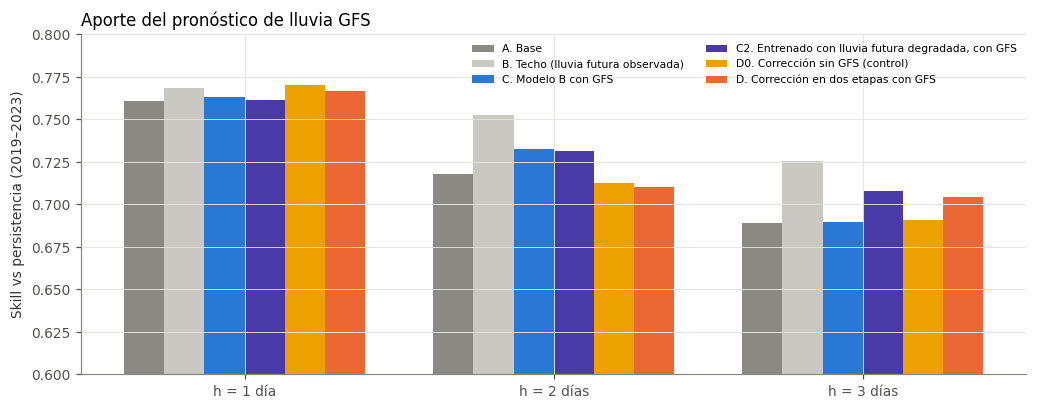

In [61]:
sk_g = pd.DataFrame({h: RES_G[h]['Skill_pers'] for h in RES_G}).T
fig, ax = plt.subplots(figsize=(9.5, 3.8)); w_b = 0.13
cols_g = ['#8a8984', '#c9c8c3', C_OBS, '#4a3aa7', '#eda100', C_MOD]
for i, (c, col) in enumerate(zip(sk_g.columns, cols_g)):
    ax.bar(np.arange(len(sk_g)) + (i - 2.5) * w_b, sk_g[c], width=w_b, color=col, label=c)
ax.set_xticks(range(len(sk_g))); ax.set_xticklabels([f'h = {h} día{"s" if h > 1 else ""}' for h in sk_g.index])
ax.set_ylim(0.6, 0.8); ax.set_ylabel('Skill vs persistencia (2019–2023)'); ax.legend(fontsize=7, ncol=2, loc='upper right')
ax.set_title('Aporte del pronóstico de lluvia GFS', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/gfs_skill.png', dpi=150); plt.show()

In [62]:
# Cruce del umbral Q90 en las subidas: ¿el pronóstico con GFS avisa antes?
def primer_cruce(s, t, U=Q90):
    w = s[t - pd.Timedelta(days=10): t + pd.Timedelta(days=10)]
    c = w[(w >= U) & (w.shift(1) < U)]
    return (c.index[0] - t).days if len(c) else np.nan
P3 = PRED_G[3].asfreq('D')
obs3 = P3.obs
cruces = obs3[(obs3 >= Q90) & (obs3.shift(1) < Q90)].index
tab_cr = pd.DataFrame([{'cruce_observado': t.date(), 'Base': primer_cruce(P3['A'], t), 'Con GFS (C2)': primer_cruce(P3['C2'], t),
                        'Techo (lluvia observada)': primer_cruce(P3['B'], t)} for t in cruces])
R['gfs']['cruces'] = tab_cr.assign(cruce_observado=tab_cr.cruce_observado.astype(str)).to_dict(orient='records')
tab_cr

,cruce_observado,Base,Con GFS (C2),Techo (lluvia observada)
0,2019-05-09,1,1,1
1,2022-04-14,0,0,0


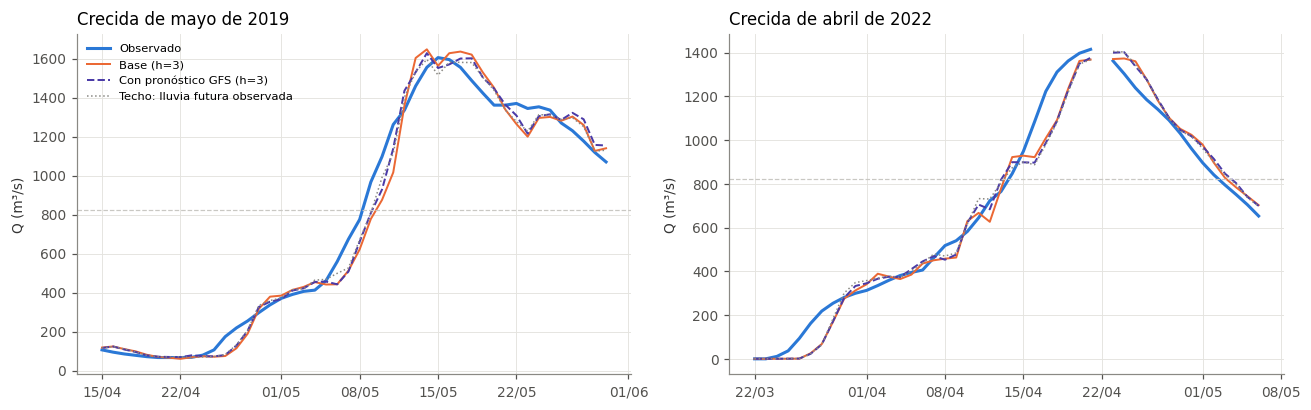

In [63]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (t_c, tit) in zip(axs, [('2019-05-15', 'Crecida de mayo de 2019'), ('2022-04-21', 'Crecida de abril de 2022')]):
    tc = pd.Timestamp(t_c); v_ = slice(tc - pd.Timedelta(days=30), tc + pd.Timedelta(days=15)); d_ = P3[v_]
    ax.plot(d_.index, d_.obs, color=C_OBS, lw=2, label='Observado')
    ax.plot(d_.index, d_['A'], color=C_MOD, lw=1.3, label='Base (h=3)')
    ax.plot(d_.index, d_['C2'], color='#4a3aa7', lw=1.3, ls='--', label='Con pronóstico GFS (h=3)')
    ax.plot(d_.index, d_['B'], color='#8a8984', lw=1, ls=':', label='Techo: lluvia futura observada')
    ax.axhline(Q90, color='#c9c8c3', lw=0.8, ls='--'); ax.set_title(tit, loc='left'); ax.set_ylabel('Q (m³/s)')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
axs[0].legend(fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/gfs_eventos.png', dpi=150); plt.show()

Síntesis GFS: el pronóstico de lluvia de la cuenca es aceptable (correlación diaria ~0,70 a 1–2 días y ~0,60 a 3 días; detecta ~80 % de los días de lluvia, con ~30 % de falsas alarmas). En el modelo aporta una mejora moderada a 2–3 días (skill +0,015–0,02 y menor error en caudales altos), que equivale a cerca de la mitad de lo que daría un pronóstico perfecto; a 1 día la mejora es despreciable. No elimina el día de atraso: en los primeros días de una crecida, el caudal de Villa Florida depende sobre todo de la lluvia que ya cayó y de su tránsito por la red, no de la lluvia futura.

## 19. Alerta de caudales altos: ¿se superará el caudal de 10 % de permanencia?

Las secciones anteriores estiman el caudal de un día exacto. Para alertar alcanza con responder una pregunta más simple: si el caudal superará un umbral en los próximos 3 días. Se usan tres umbrales de la curva de permanencia del entrenamiento: caudal superado el 5 %, el 10 % (Q90 = 823 m³/s, el umbral usado en todo el proyecto) y el 20 % del tiempo.

Se comparan cuatro formas de emitir la alerta en la mañana siguiente al día t, solo en días en que el río está por debajo del umbral:

- Regresión, valor central: alguno de los pronósticos a 1, 2 o 3 días supera el umbral.
- Regresión, percentil 75: ídem con el percentil 75.
- Clasificador: un LightGBM (mismo Pipeline y variables) que estima directamente la probabilidad de superar el umbral en los próximos 3 días. El umbral de probabilidad se elige con predicciones fuera de muestra dentro del entrenamiento (validación temporal), sin mirar el test.
- Persistencia de la tendencia: extrapolar la subida del último día (referencia simple).

La evaluación principal es por evento: cada cruce ascendente del umbral en 2013–2023 (con al menos 5 días previos por debajo) cuenta como una crecida; se registra si hubo alerta en los 3 días anteriores y con cuántos días de anticipación. Una falsa alarma es un episodio de alerta (días seguidos) sin superación en los 3 días siguientes.

In [64]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
q_tr = serie.Q[TRAIN]
UMB = {p: float(q_tr.quantile(1 - p / 100)) for p in [5, 10, 20]}
W_AL = 3
PC = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1,
          colsample_bytree=0.7, reg_lambda=5, verbose=-1, random_state=SEED, n_jobs=2)
def tabla_contingencia(o, a):
    h = (a & (o == 1)).sum(); fa = (a & (o == 0)).sum(); mi = ((~a) & (o == 1)).sum()
    return dict(POD=h / max(h + mi, 1), FAR=fa / max(h + fa, 1), CSI=h / max(h + fa + mi, 1))
def max_futuro(w): return pd.concat([serie.Q.shift(-k) for k in range(1, w + 1)], axis=1).max(1, skipna=False)

# Pronósticos de la regresión (valor central y percentil 75) para h = 1, 2, 3
p75_finales = {}
for h in [1, 2, 3]:
    y_h, itr_h, _ = datos_h(h)
    p75_finales[h] = crear_pipeline(mk(objective='quantile', alpha=0.75), ALL_COLS).fit(X.loc[itr_h, ALL_COLS], y_h[itr_h])
okx = X['lQ_0'].notna()
REG_C = pd.DataFrame({h: serie.Q * np.exp(finales[h].predict(X[ALL_COLS])) for h in [1, 2, 3]}).where(okx)
REG_75 = pd.DataFrame({h: serie.Q * np.exp(p75_finales[h].predict(X[ALL_COLS])) for h in [1, 2, 3]}).where(okx)

CLASIF, PROB_AL, filas_dia = {}, {}, []
fm = max_futuro(W_AL)
for p, U in UMB.items():
    ev = (fm > U).astype(float).where(fm.notna())
    ok = ev.notna() & okx & (serie.Q <= U)
    itr_, ite_ = ok & TRAIN, ok & TEST
    # umbral de probabilidad: máximo CSI con predicciones fuera de muestra (TimeSeriesSplit en el entrenamiento)
    oof = pd.Series(np.nan, index=serie.index); it = np.where(itr_)[0]
    for a, b in TimeSeriesSplit(5).split(it):
        m_ = crear_pipeline(LGBMClassifier(**PC), ALL_COLS).fit(X.iloc[it[a]][ALL_COLS], ev.iloc[it[a]])
        oof.iloc[it[b]] = m_.predict_proba(X.iloc[it[b]][ALL_COLS])[:, 1]
    mo = oof.notna(); us = np.round(np.arange(0.1, 0.81, 0.05), 2)
    u = float(us[np.argmax([tabla_contingencia(ev[mo].values, oof[mo].values >= x)['CSI'] for x in us])])
    clf = crear_pipeline(LGBMClassifier(**PC), ALL_COLS).fit(X.loc[itr_, ALL_COLS], ev[itr_])
    pr = pd.Series(clf.predict_proba(X.loc[okx, ALL_COLS])[:, 1], index=serie.index[okx]).reindex(serie.index)
    CLASIF[p] = {'modelo': clf, 'umbral_prob': u, 'caudal': U}; PROB_AL[p] = pr
    o = ev[ite_].values; clim = ev[itr_].mean()
    r = dict(permanencia=p, caudal=U, dias=int(len(o)), dias_con_superacion=int(o.sum()), AUC=roc_auc_score(o, pr[ite_]),
             BSS=1 - brier_score_loss(o, pr[ite_]) / np.mean((o - clim) ** 2), umbral_prob=u)
    for nom, a in [('Clasificador', pr[ite_].values >= u), ('Regresión central', (REG_C.loc[ite_].max(1) > U).values),
                   ('Regresión P75', (REG_75.loc[ite_].max(1) > U).values)]:
        r.update({f'{nom} {k}': v for k, v in tabla_contingencia(o, a).items()})
    filas_dia.append(r)
T_DIA = pd.DataFrame(filas_dia).set_index('permanencia')
T_DIA.round(3)

,caudal,dias,dias_con_superacion,AUC,BSS,umbral_prob,Clasificador POD,Clasificador FAR,Clasificador CSI,Regresión central POD,Regresión central FAR,Regresión central CSI,Regresión P75 POD,Regresión P75 FAR,Regresión P75 CSI
permanencia,,,,,,,,,,,,,,,
5,993.224,3414,39,0.995,0.618,0.10,0.846,0.411,0.532,0.538,0.087,0.512,0.692,0.206,0.587
10,823.358,3293,42,0.990,0.572,0.30,0.714,0.286,0.556,0.548,0.281,0.451,0.619,0.381,0.448
20,578.750,3014,61,0.985,0.382,0.25,0.672,0.539,0.376,0.705,0.259,0.566,0.820,0.474,0.472


In [65]:
def eventos_cruce(U, idx=TEST):
    c = serie.Q[(serie.Q > U) & (serie.Q.shift(1) <= U) & idx]
    return [t for t in c.index if (serie.Q[t - pd.Timedelta(days=5):t - pd.Timedelta(days=1)] <= U).all()]
def evaluar_alerta(alarma, U, W=W_AL):
    evs = eventos_cruce(U); ant = []
    for c in evs:
        a = [c - pd.Timedelta(days=k) for k in range(W, 0, -1) if alarma.get(c - pd.Timedelta(days=k), False)]
        ant.append((c - a[0]).days if a else 0)
    dias_al = alarma[alarma].index; falsos = 0; n_ep = 0
    if len(dias_al):
        grupo = (pd.Series(dias_al).diff().dt.days != 1).cumsum().values
        for _, g in pd.Series(dias_al).groupby(grupo):
            n_ep += 1
            falsos += int(not (serie.Q[g.iloc[0] + pd.Timedelta(days=1): g.iloc[-1] + pd.Timedelta(days=W)] > U).any())
    anos = TEST.sum() / 365.25
    return dict(eventos=len(evs), detectados=int((np.array(ant) > 0).sum()), anticipacion_media=float(np.mean([a for a in ant if a > 0])),
                episodios=n_ep, falsas_alarmas=falsos, falsas_por_ano=falsos / anos, anticipacion=ant, fechas=[str(e.date()) for e in evs])
filas_ev = []
for p, U in UMB.items():
    base_ok = TEST & okx & (serie.Q <= U)
    alarmas = {'Regresión (valor central)': (REG_C.max(1) > U) & base_ok, 'Regresión (percentil 75)': (REG_75.max(1) > U) & base_ok,
               'Clasificador': (PROB_AL[p] >= CLASIF[p]['umbral_prob']) & base_ok,
               'Persistencia de la tendencia': (serie.Q * (serie.Q / serie.Q.shift(1)).clip(lower=1) ** W_AL > U) & base_ok}
    for nom, a in alarmas.items():
        filas_ev.append(dict(permanencia=p, caudal=round(U), metodo=nom, **evaluar_alerta(a, U)))
T_EV = pd.DataFrame(filas_ev)
R['alerta'] = {'umbrales': UMB, 'ventana_dias': W_AL, 'umbral_prob': {p: CLASIF[p]['umbral_prob'] for p in UMB},
               'por_dia': T_DIA.round(4).reset_index().to_dict(orient='records'), 'por_evento': T_EV.round(3).to_dict(orient='records')}
T_EV.drop(columns=['anticipacion', 'fechas']).round(2)

,permanencia,caudal,metodo,eventos,detectados,anticipacion_media,episodios,falsas_alarmas,falsas_por_ano
0,5,993,Regresión (valor central),12,12,2.08,14,2,0.19
1,5,993,Regresión (percentil 75),12,12,2.33,15,3,0.28
2,5,993,Clasificador,12,12,2.75,19,7,0.66
3,5,993,Persistencia de la tendencia,12,12,2.75,35,22,2.07
4,10,823,Regresión (valor central),14,13,2.00,19,6,0.56
5,10,823,Regresión (percentil 75),14,13,2.15,22,9,0.85
6,10,823,Clasificador,14,13,2.54,23,9,0.85
7,10,823,Persistencia de la tendencia,14,13,2.31,40,27,2.54
8,20,579,Regresión (valor central),19,18,2.28,32,12,1.13
9,20,579,Regresión (percentil 75),19,19,2.58,43,23,2.16


In [66]:
# Crecidas del test que superaron 823 m³/s y anticipación de cada método (0 = sin alerta previa)
d10 = T_EV[T_EV.permanencia == 10].set_index('metodo')
tab_ant = pd.DataFrame({m: d10.loc[m, 'anticipacion'] for m in d10.index}, index=d10.iloc[0]['fechas'])
tab_ant

,Regresión (valor central),Regresión (percentil 75),Clasificador,Persistencia de la tendencia
2013-05-20,1,1,2,2
2014-04-18,1,2,3,2
2014-06-04,2,2,2,3
2014-07-01,3,3,3,2
2014-08-06,3,3,3,3
2015-05-19,2,2,3,2
2015-07-26,2,2,3,2
2015-10-26,0,0,0,0
2015-12-17,3,3,3,3
2017-04-16,2,3,3,3


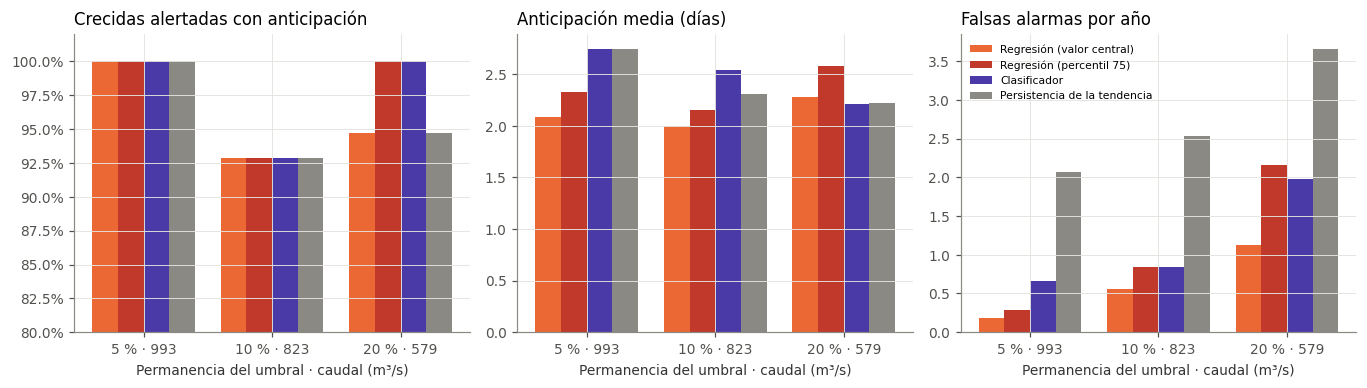

In [67]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6))
met_cols = {'Regresión (valor central)': C_MOD, 'Regresión (percentil 75)': '#c0392b', 'Clasificador': '#4a3aa7', 'Persistencia de la tendencia': C_PERS}
for ax, (col, tit) in zip(axs, [('detectados', 'Crecidas alertadas con anticipación'), ('anticipacion_media', 'Anticipación media (días)'), ('falsas_por_ano', 'Falsas alarmas por año')]):
    for i, (m, c) in enumerate(met_cols.items()):
        d = T_EV[T_EV.metodo == m]
        vals = d[col] / d.eventos if col == 'detectados' else d[col]
        ax.bar(np.arange(3) + (i - 1.5) * 0.2, vals, width=0.2, color=c, label=m)
    ax.set_xticks(range(3)); ax.set_xticklabels([f'{p_} % · {UMB[p_]:,.0f}'.replace(',', ' ') for p_ in UMB])
    ax.set_title(tit, loc='left'); ax.set_xlabel('Permanencia del umbral · caudal (m³/s)')
axs[0].set_ylim(0.8, 1.02); axs[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axs[2].legend(fontsize=7, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/alerta_eventos.png', dpi=150); plt.show()

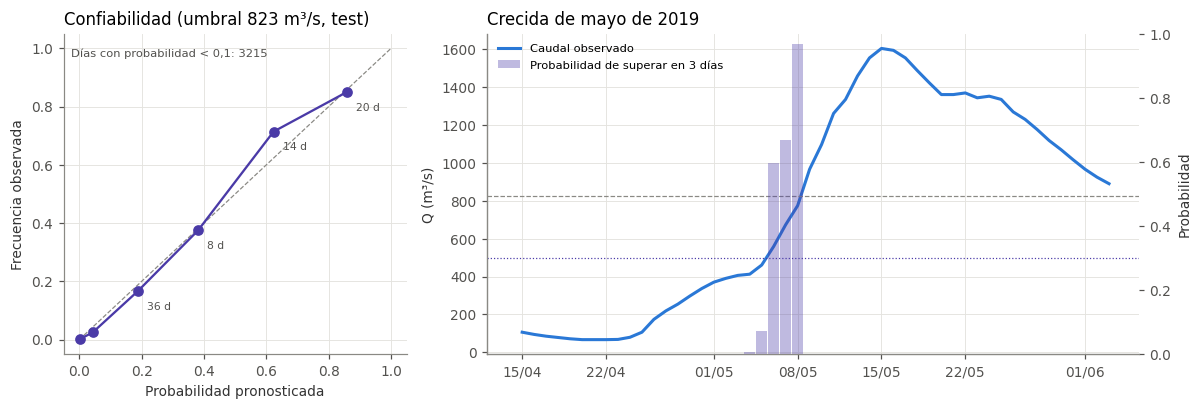

In [68]:
# Confiabilidad de la probabilidad (umbral de 10 %): ¿cuando dice 60 %, ocurre ~60 % de las veces?
p = 10; U = UMB[p]; ev = (fm > U).astype(float).where(fm.notna()); ite_ = ev.notna() & okx & (serie.Q <= U) & TEST
pr, o = PROB_AL[p][ite_], ev[ite_]
bins = [0, 0.02, 0.1, 0.3, 0.5, 0.7, 1.0]; g = pd.cut(pr, bins, include_lowest=True)
conf = pd.DataFrame({'prob_media': pr.groupby(g).mean(), 'frecuencia_obs': o.groupby(g).mean(), 'dias': o.groupby(g).size()})
R['alerta']['confiabilidad_10'] = conf.reset_index(drop=True).round(4).to_dict(orient='records')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.9]})
axs[0].plot([0, 1], [0, 1], color=C_PERS, lw=0.8, ls='--'); axs[0].plot(conf.prob_media, conf.frecuencia_obs, 'o-', color='#4a3aa7')
for _, r_ in conf[conf.prob_media > 0.1].iterrows(): axs[0].annotate(f'{int(r_.dias)} d', (r_.prob_media, r_.frecuencia_obs), xytext=(6, -12), textcoords='offset points', fontsize=7, color='#52514e')
axs[0].text(0.02, 0.93, f'Días con probabilidad < 0,1: {int(conf.dias.iloc[:2].sum())}', transform=axs[0].transAxes, fontsize=7.5, color='#52514e')
axs[0].set_xlabel('Probabilidad pronosticada'); axs[0].set_ylabel('Frecuencia observada'); axs[0].set_title('Confiabilidad (umbral 823 m³/s, test)', loc='left')
v_ = slice('2019-04-15', '2019-06-10'); ax = axs[1]; ax2 = ax.twinx()
ax.plot(serie.Q[v_].index, serie.Q[v_], color=C_OBS, lw=2, label='Caudal observado'); ax.axhline(U, color=C_PERS, ls='--', lw=0.8)
ax2.bar(PROB_AL[p][v_].index, PROB_AL[p][v_].where(serie.Q[v_] <= U), color='#4a3aa7', alpha=0.35, width=0.9, label='Probabilidad de superar en 3 días')
ax2.axhline(CLASIF[p]['umbral_prob'], color='#4a3aa7', lw=0.8, ls=':'); ax2.set_ylim(0, 1); ax2.set_ylabel('Probabilidad'); ax2.grid(False)
ax.set_ylabel('Q (m³/s)'); ax.set_title('Crecida de mayo de 2019', loc='left'); ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
h1_, l1_ = ax.get_legend_handles_labels(); h2_, l2_ = ax2.get_legend_handles_labels(); ax.legend(h1_ + h2_, l1_ + l2_, fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.savefig(f'{FIG}/alerta_probabilidad.png', dpi=150); plt.show()

Síntesis de la alerta: para el caudal de 10 % de permanencia (823 m³/s), las tres alertas basadas en el modelo detectan 13 de las 14 crecidas de 2013–2023 con anticipación. El clasificador anticipa en promedio ~2,5 días frente a ~2 días de la regresión, con una tasa de falsas alarmas similar (< 1 por año); la extrapolación de la tendencia detecta lo mismo pero con ~2,5 falsas alarmas por año. La crecida no detectada (26/10/2015) es un pico de un día provocado por 46 mm caídos ese mismo día, posterior a la emisión. Las diferencias entre métodos por día son del orden del ruido (pocas crecidas en el test); lo robusto es que cualquier alerta basada en el modelo detecta casi todas las crecidas con 2–3 días de anticipación y pocas falsas alarmas.

## 20. Diagnóstico de caudales bajos

El error relativo del pronóstico es mayor en estiaje. Esta sección verifica si el régimen de caudales bajos cambió entre el período de entrenamiento y el de test, usando solo lluvia y caudal: tendencia de los mínimos anuales y comparación con el caudal que "correspondería" a la lluvia según un modelo entrenado en 1974–2002 solo con lluvia antecedente (1 a 365 días).

In [69]:
from scipy import stats
an = pd.DataFrame({'P': serie.Pmed.resample('YE').sum(min_count=330), 'Q': serie.Q.resample('YE').mean(), 'n': serie.Q.resample('YE').count(),
                   'Qmin7': serie.Q.rolling(7).mean().resample('YE').min()})
an = an[an.n > 330]; an.index = an.index.year
an['escorrentia_mm'] = an.Q * 86400 * 365 / (A_KM2 * 1e6) * 1000
tend = {}
for c in ['P', 'escorrentia_mm', 'Qmin7']:
    d = an[c].dropna(); kt = stats.kendalltau(d.index, d.values)
    tend[c] = {'tau': float(kt.statistic), 'p_valor': float(kt.pvalue), 'pendiente_sen_por_ano': float(stats.theilslopes(d.values, d.index)[0])}
XL = pd.DataFrame(index=serie.index)
for k in [1, 3, 7, 15, 30, 60, 90, 180, 365]: XL[f'P{k}'] = serie.Pmed.rolling(k, min_periods=int(k * 0.8)).sum()
for kk in [0.9, 0.97, 0.99]:
    p_ = serie.Pmed.fillna(0).values; a_ = np.zeros(len(p_))
    for i in range(1, len(p_)): a_[i] = kk * a_[i - 1] + p_[i]
    XL[f'API{kk}'] = a_
XL['mes'] = serie.index.month
yl = np.log(serie.Q.clip(lower=0.5)); okl = yl.notna() & XL.P365.notna()
m_ll = LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=50, subsample=0.7, subsample_freq=1,
                     colsample_bytree=0.7, reg_lambda=5, verbose=-1, random_state=SEED).fit(XL[okl & TRAIN], yl[okl & TRAIN])
Qll = pd.Series(np.exp(m_ll.predict(XL.fillna(0))), index=serie.index).where(okl)
d_ = pd.DataFrame({'Q': serie.Q, 'Qll': Qll}).dropna()
d_['periodo'] = np.where(d_.index.year <= 2002, '1974–2002', '2013–2023')
d_['estacion'] = np.where(d_.index.month.isin([12, 1, 2, 3]), 'dic–mar', np.where(d_.index.month.isin([6, 7, 8, 9]), 'jun–sep', 'otros meses'))
res_per = d_.groupby('periodo').apply(lambda g: pd.Series({'Q medio observado': g.Q.mean(), 'Q medio según lluvia': g.Qll.mean(),
                                                           'Q10 bajo observado': g.Q.quantile(0.1), 'Q10 bajo según lluvia': g.Qll.quantile(0.1),
                                                           'días Q<30 observado (%)': 100 * (g.Q < 30).mean(), 'días Q<30 según lluvia (%)': 100 * (g.Qll < 30).mean()}))
ratio = d_[d_.Qll < 150].groupby(['periodo', 'estacion']).apply(lambda g: (g.Q / g.Qll).median()).unstack()
R['estiaje'] = {'tendencias': tend, 'resumen': res_per.round(2).to_dict(), 'ratio_obs_esperado': ratio.round(3).to_dict(),
                'dias_valor_0.87': int((serie.Q.round(2) == 0.87).sum())}
print('Tendencias (Kendall, pendiente de Sen):', {k: {kk: round(vv, 4) for kk, vv in v.items()} for k, v in tend.items()})
print(ratio.round(2)); res_per.round(1).T

Tendencias (Kendall, pendiente de Sen): {'P': {'tau': -0.0092, 'p_valor': 0.9652, 'pendiente_sen_por_ano': -0.7246}, 'escorrentia_mm': {'tau': -0.0462, 'p_valor': 0.76, 'pendiente_sen_por_ano': -1.4335}, 'Qmin7': {'tau': -0.34, 'p_valor': 0.0152, 'pendiente_sen_por_ano': -1.2847}}
estacion   dic–mar  jun–sep  otros meses
periodo                                 
1974–2002     0.97     0.99         0.92
2013–2023     0.55     0.79         0.61


periodo,1974–2002,2013–2023
Q medio observado,356.4,309.8
Q medio según lluvia,338.7,311.5
Q10 bajo observado,67.3,20.4
Q10 bajo según lluvia,66.2,54.8
días Q<30 observado (%),2.3,13.3
días Q<30 según lluvia (%),1.1,0.3


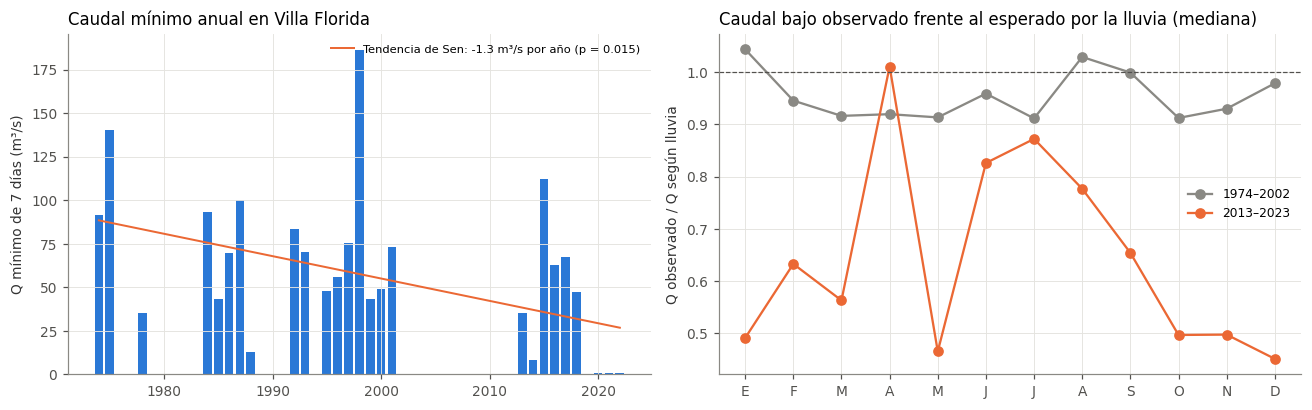

In [70]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axs[0]; ax.bar(an.index, an.Qmin7, color=C_OBS, width=0.8)
sl = tend['Qmin7']['pendiente_sen_por_ano']; x0 = an.Qmin7.dropna()
ax.plot(x0.index, np.median(x0.values - sl * x0.index.values) + sl * x0.index.values, color=C_MOD, lw=1.3, label=f'Tendencia de Sen: {sl:.1f} m³/s por año (p = {tend["Qmin7"]["p_valor"]:.3f})')
ax.set_ylabel('Q mínimo de 7 días (m³/s)'); ax.set_title('Caudal mínimo anual en Villa Florida', loc='left'); ax.legend(fontsize=7.5)
ax = axs[1]; mm = d_[d_.Qll < 150].groupby(['periodo', d_[d_.Qll < 150].index.month]).apply(lambda g: (g.Q / g.Qll).median()).unstack(0)
for c_, col in zip(mm.columns, [C_PERS, C_MOD]): ax.plot(mm.index, mm[c_], 'o-', color=col, label=c_)
ax.axhline(1, color='#52514e', lw=0.8, ls='--'); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list('EFMAMJJASOND'))
ax.set_ylabel('Q observado / Q según lluvia'); ax.set_title('Caudal bajo observado frente al esperado por la lluvia (mediana)', loc='left'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/estiaje_diagnostico.png', dpi=150); plt.show()

Síntesis del diagnóstico: la lluvia anual y la escorrentía anual no tienen tendencia, pero el caudal mínimo anual sí disminuye de forma significativa. En 2013–2023 el caudal medio coincide con el esperado por la lluvia (las crecidas no cambiaron), mientras que en aguas bajas el caudal observado es alrededor de la mitad del esperado en diciembre–marzo y ~80 % en junio–septiembre; mes a mes, el déficit es mayor entre octubre y marzo. El patrón estacional es compatible con extracciones durante la temporada de riego (arroz), aunque también pueden intervenir la sequía extrema de 2020–2022 y cambios en la curva de gasto en aguas bajas (el valor 0,87 m³/s se repite como piso). Confirmarlo requiere datos de uso del agua y aforos de estiaje. Para este proyecto, explica por qué el pronóstico es menos preciso en estiaje y refuerza que su uso recomendado es para caudales medios y altos.

## 21. Explicabilidad — SHAP

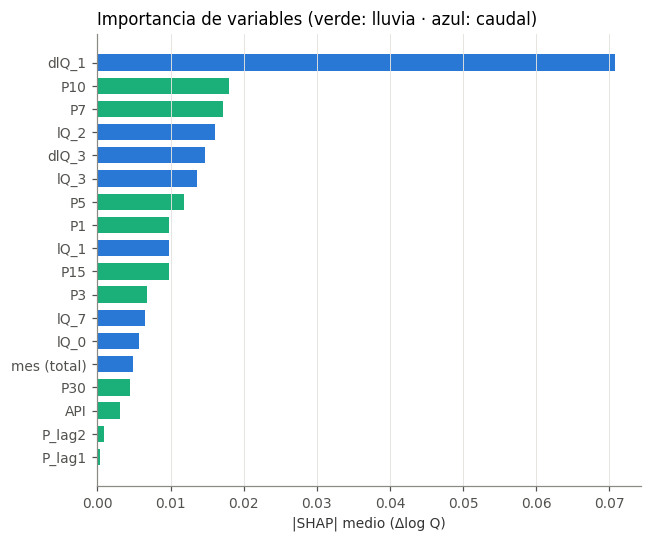

In [71]:
pipe_final = finales[H]
idx_te = ite[ite].index
Xt = pipe_final.named_steps['prep'].transform(X.loc[idx_te, ALL_COLS])
nombres = [n.split('__')[1] for n in pipe_final.named_steps['prep'].get_feature_names_out()]
explainer = shap.TreeExplainer(pipe_final.named_steps['modelo'])
sv = explainer.shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(0), index=nombres)
imp_mes = imp[[c for c in nombres if c.startswith('mes_')]].sum()
imp = pd.concat([imp[[c for c in nombres if not c.startswith('mes_')]], pd.Series({'mes (total)': imp_mes})]).sort_values()
R['shap'] = imp.sort_values(ascending=False).round(5).to_dict()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(imp.index, imp.values, color=[C_P if c.startswith(('P', 'API')) else C_OBS for c in imp.index], height=0.7)
ax.set_xlabel('|SHAP| medio (Δlog Q)'); ax.grid(axis='y', visible=False)
ax.set_title('Importancia de variables (verde: lluvia · azul: caudal)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/shap_importancia.png', dpi=150); plt.show()

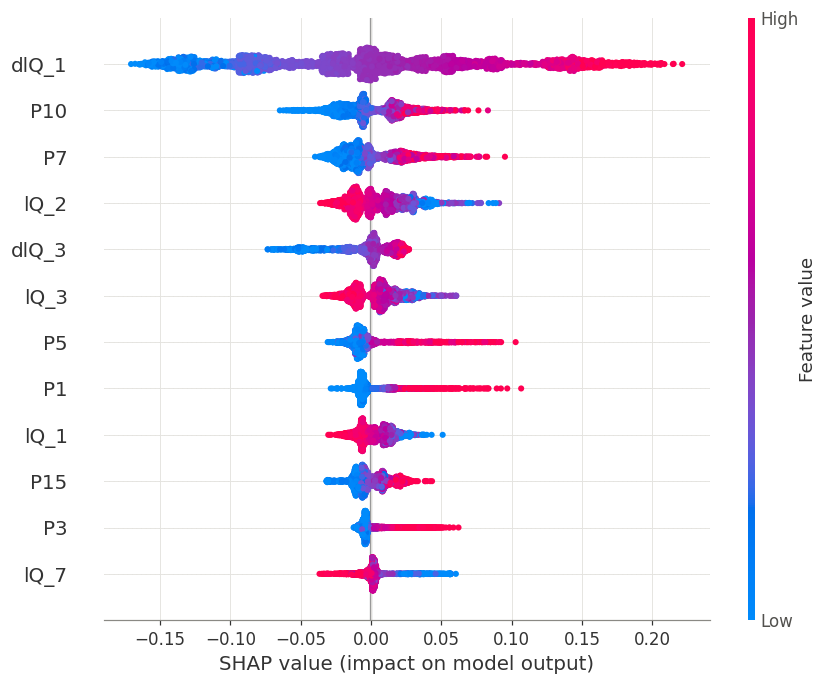

In [72]:
shap.summary_plot(sv, Xt, feature_names=nombres, max_display=12, show=False)
plt.tight_layout(); plt.savefig(f'{FIG}/shap_resumen.png', dpi=150); plt.show()

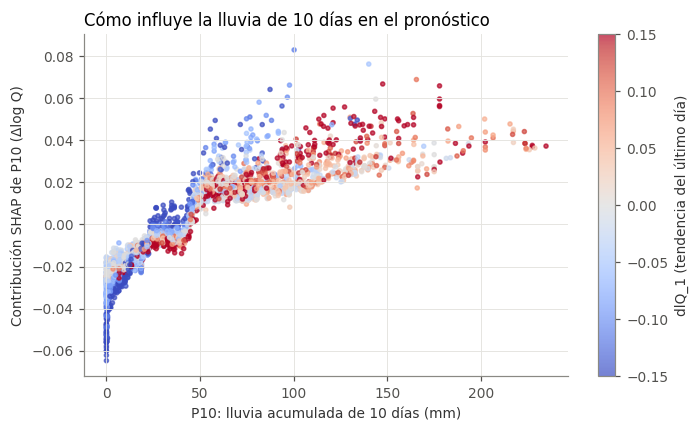

In [73]:
# Dependencia: efecto de P10 según la tendencia del caudal
i_p10, i_dq = nombres.index('P10'), nombres.index('dlQ_1')
fig, ax = plt.subplots(figsize=(6.5, 4))
sc = ax.scatter(X.loc[idx_te, 'P10'], sv[:, i_p10], c=X.loc[idx_te, 'dlQ_1'].clip(-0.15, 0.15), cmap='coolwarm', s=7, alpha=0.7)
plt.colorbar(sc, ax=ax, label='dlQ_1 (tendencia del último día)')
ax.set_xlabel('P10: lluvia acumulada de 10 días (mm)'); ax.set_ylabel('Contribución SHAP de P10 (Δlog Q)')
ax.set_title('Cómo influye la lluvia de 10 días en el pronóstico', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/shap_dependencia_P10.png', dpi=150); plt.show()

## 22. Guardado del modelo e inferencia

In [74]:
q_finales = {}
for h in [1, 2, 3]:
    y_h, itr_h, ite_h = datos_h(h)
    lo = crear_pipeline(mk(objective='quantile', alpha=0.05), ALL_COLS).fit(X.loc[itr_h, ALL_COLS], y_h[itr_h])
    hi = crear_pipeline(mk(objective='quantile', alpha=0.95), ALL_COLS).fit(X.loc[itr_h, ALL_COLS], y_h[itr_h])
    ic = ite_h & (serie.index.year <= 2015); yc = y_h[ic].values
    E = np.maximum(lo.predict(X.loc[ic, ALL_COLS]) - yc, yc - hi.predict(X.loc[ic, ALL_COLS]))
    q_finales[h] = {'p05': lo, 'p95': hi, 'qhat': float(np.quantile(E, min(1, np.ceil((len(E) + 1) * 0.9) / len(E))))}

# Percentil 75 para alertas: p75_finales (sección 19)
resumen_app = {'metricas': metricas_df.round(4).to_dict(orient='index'), 'persistencia': base.round(4).to_dict(orient='index'),
               'ablacion_skill': tab_skill.round(4).to_dict(orient='index'), 'shap': R['shap'], 'validez': R['validez'],
               'corr_retardo': [float(c) for c in cc[:15]], 'cobertura': R['cobertura'], 'desfase': R['desfase'],
               'Pmed_anual': float(Pmed.resample('YE').sum(min_count=330).mean()), 'n_train': int(datos_h(3)[1].sum()), 'n_test': int(datos_h(3)[2].sum())}
bundle = {'modelos': finales, 'cuantiles': q_finales, 'p75': p75_finales, 'resumen': resumen_app, 'features': ALL_COLS, 'ventanas': VENT, 'api_k': API_K,
          'umbral_Q90': float(Q90), 'objetivo': 'log Q(t+h) - log Q(t)', 'hiperparametros': MEJORES,
          'periodo_train': '1974-2002', 'periodo_test': '2013-2023',
          'metricas_test': metricas_df.round(4).to_dict(orient='index'),
          'area_km2': float(A_KM2), 'pesos_thiessen': w_full.round(4).to_dict(),
          'correccion_yuty': corr_yuty, 'cols_correccion': COLS_CORR, 'yuty_cols': YCOLS,
          'metricas_yuty_origen_movil': R['yuty']['metricas'],
          'gfs': {'modelos': MOD_GFS, 'columnas': COLS_GFS, 'factores_sesgo': FAC_G.round(4).to_dict(),
                  'descripcion': 'G1, G2, G3: lluvia media de la cuenca pronosticada por GFS (corrida 00 UTC del día t+1, ventanas 12-36, 36-60 y 60-84 h), sin corregir; se multiplica por factores_sesgo',
                  'metricas_2019_2023': R['gfs']['experimentos']},
          'alerta': {'clasificadores': CLASIF, 'ventana_dias': W_AL,
                     'descripcion': 'Probabilidad de que el caudal supere el umbral (permanencia 5, 10 y 20 %) en los próximos 3 días; válido si Q(t) <= umbral',
                     'por_evento': R['alerta']['por_evento']}}
joblib.dump(bundle, 'model.pkl', compress=3)
print(f'model.pkl guardado ({os.path.getsize("model.pkl") / 1e6:.2f} MB)')

model.pkl guardado (2.73 MB)


In [75]:
# Prueba de carga e inferencia: pronóstico emitido 3 días antes del pico máximo del test
cargado = joblib.load('model.pkl')
t0 = t_pico - pd.Timedelta(days=H)
hist = serie.loc[t0 - pd.Timedelta(days=60):t0, ['Pmed', 'Q']]
Xh = construir_features(hist).iloc[[-1]][cargado['features']]
q_hoy = hist.Q.iloc[-1]
print(f'Emisión: {t0.date()} · Q observado hoy = {q_hoy:,.0f} m³/s')
for h, mdl in cargado['modelos'].items():
    qf = q_hoy * np.exp(mdl.predict(Xh)[0]); cq = cargado['cuantiles'][h]
    lo = q_hoy * np.exp(cq['p05'].predict(Xh)[0] - cq['qhat']); hi = q_hoy * np.exp(cq['p95'].predict(Xh)[0] + cq['qhat'])
    print(f'  t+{h} ({(t0 + pd.Timedelta(days=h)).date()}): {qf:,.0f} m³/s  [90 %: {lo:,.0f} – {hi:,.0f}]  · observado {serie.Q.get(t0 + pd.Timedelta(days=h)):,.0f} m³/s')

Emisión: 2014-05-06 · Q observado hoy = 1,345 m³/s
  t+1 (2014-05-07): 1,353 m³/s  [90 %: 1,261 – 1,479]  · observado 1,626 m³/s
  t+2 (2014-05-08): 1,368 m³/s  [90 %: 1,204 – 1,569]  · observado 1,732 m³/s
  t+3 (2014-05-09): 1,345 m³/s  [90 %: 1,112 – 1,697]  · observado 1,788 m³/s


## 23. Muestra de datos (100 filas)

Ventana de 100 días alrededor de la crecida de mayo de 2019 (período de test): precipitación por estación, Pmed, caudal en Villa Florida (Q), caudal en Yuty (Qy) y lluvia pronosticada por GFS para los 3 días siguientes (G1–G3). Es el archivo de ejemplo que usa la app de Streamlit.

In [76]:
completo = serie.join(P).join(GF.round(2))   # G1–G3: pronóstico GFS sin corregir (opcional en la app)
ini = pd.Timestamp('2019-05-15') - pd.Timedelta(days=73)
muestra = completo.loc[ini:ini + pd.Timedelta(days=99)].round(3)
muestra.to_csv('datos_muestra.csv', index_label='fecha')
print(muestra.shape); muestra.head()

(100, 15)


,Pmed,cob_red,Q,Qy,Paraguari,Villarrica,Coronel_Oviedo,Quyquyho,Pilar,San_Juan_Bautista,Caazapa,Encarnacion,G1,G2,G3
2019-03-03,0.000,1.0,34.167,16.525,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.64,5.75
2019-03-04,0.000,1.0,35.237,14.395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.09,0.24,2.52
2019-03-05,9.614,1.0,37.384,14.822,0.0,8.0,0.0,0.0,8.5,0.0,8.0,77.8,0.37,5.05,21.71
2019-03-06,2.672,1.0,36.309,15.249,7.6,0.0,0.0,6.0,0.5,1.3,0.0,20.7,8.11,29.29,3.10
2019-03-07,12.726,1.0,34.167,16.949,0.0,9.1,0.0,0.0,0.0,0.5,11.6,98.9,22.59,1.37,2.19


In [77]:
import json
R['persistencia'] = base.round(4).to_dict(orient='index')
R['ablacion_skill'] = tab_skill.round(4).to_dict(orient='index')
R['ablacion_rmse_alto'] = tab_alto.round(2).to_dict(orient='index')
R['ganancia'] = ganancia.round(4).to_dict(orient='index')
R['comparacion'] = comp.round(4).to_dict(orient='records')
R['optimizacion'] = {'mejores': MEJORES, 'tuned': {k: float(v) for k, v in m_tuned.items()}, 'defecto': m_def.round(4).to_dict()}
R['general'] = {'Q90': float(Q90), 'area_km2': float(A_KM2), 'pesos': w_full.round(4).to_dict(), 'combinaciones': len(_cache),
                'Pmed_anual': float(Pmed.resample('YE').sum(min_count=330).mean()), 'corr_retardo': [float(c) for c in cc[:12]],
                'n_train': int(datos_h(H)[1].sum()), 'n_test': int(datos_h(H)[2].sum()), 't_pico': str(t_pico.date()),
                'evento_eval': str(ev_eval.date())}
os.makedirs('resultados', exist_ok=True)
json.dump(R, open('resultados/resultados.json', 'w'), indent=1, default=str, ensure_ascii=False)
print('resultados/resultados.json guardado')

resultados/resultados.json guardado


## 24. Conclusiones

1. Los -1 se tratan como faltantes y la Pmed se calcula con Thiessen dinámico; tratarlos como 0 subestima la lluvia anual (~5 %) aunque casi no cambia el desempeño en test.
2. La persistencia es muy exigente en Villa Florida (NSE ≈ 0,99 a 1 día); el skill frente a ella es la métrica adecuada.
3. El modelo final (LightGBM, todas las variables) representa bien la serie completa (curva de permanencia, clases bajo/medio/alto) y supera a la persistencia en todos los horizontes.
4. La lluvia de 7–10 días es la ventana más informativa; su aporte crece con el horizonte.
5. El pronóstico mantiene un atraso de ~1 día (la persistencia tiene 3). No se elimina con lluvia futura, lluvia por zonas ni ponderación de subidas: requiere información adicional (estación aguas arriba, lluvia subdiaria o satelital).
6. Las bandas de la regresión cuantílica, recalibradas con datos recientes, alcanzan la cobertura nominal; Monte Carlo muestra que la incertidumbre de las entradas explica solo una parte del error total.
7. Yuty (aguas arriba, ~23 % del caudal de Villa Florida) aporta información útil, sobre todo a 5 días; a 1–3 días la mejora es moderada y no elimina el día de atraso, porque la mayor parte de la crecida viene de afluentes sin medición (Tebicuary-mí, Pirapó) y el registro de Yuty es corto (2016–2023).
8. CHIRPS reproduce bien la lluvia mensual y anual pero mal la diaria; como variable adicional aporta una mejora pequeña y consistente a 2–5 días, no reemplaza a las estaciones con ventaja y no reduce el día de atraso.
9. Los pronósticos históricos de GFS (2016–2023) pronostican aceptablemente la lluvia de la cuenca a 1–3 días; incorporados al modelo mejoran moderadamente el pronóstico a 2–3 días (cerca de la mitad de la mejora que daría un pronóstico perfecto) y no eliminan el día de atraso.
10. Como alerta, el objetivo del proyecto se cumple: para el caudal de 10 % de permanencia (823 m³/s), las alertas basadas en el modelo detectan 13 de las 14 crecidas de 2013–2023 con 2–3 días de anticipación y menos de una falsa alarma por año; el clasificador probabilístico da la mayor anticipación (~2,5 días).
11. Los caudales mínimos disminuyeron sin que cambie la lluvia (déficit concentrado en diciembre–marzo); el pronóstico debe usarse para caudales medios y altos.
12. Las series de Quyquyho y Caazapá son idénticas en 1974–2016; se trató Caazapá como faltante en ese período. El pronóstico a 3 días es confiable con el río estable o en recesión (error típico ~5 %) y se queda corto ~10 % en las subidas, donde para alertar se usa la probabilidad de superación (sección 19) o el percentil 75. No está validado por encima de ~1 800 m³/s.